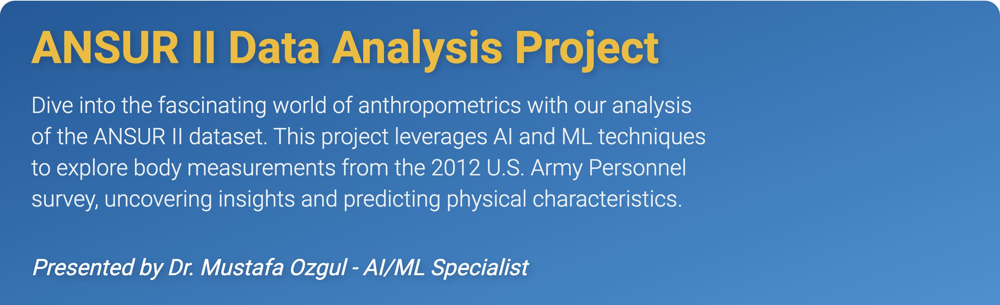

<style>
  .profile-link {
    display: inline-block;
    margin: 5px;
    transition: transform 0.3s ease; /* Smooth scaling transition */
  }

  .profile-link:hover {
    transform: scale(1.1); /* Scale up on hover */
    filter: brightness(1.2); /* Add a subtle shine effect */
  }
</style>

<a href="https://www.newwebsitename.com" class="profile-link" title="Visit my website to discover completed AI based projects ">
  <img src="https://img.shields.io/badge/Website-4285F4?style=for-the-badge&logo=google-chrome&logoColor=white" alt="Website">
</a>

<a href="https://www.linkedin.com/" class="profile-link" title="Connect with me on LinkedIn">
  <img src="https://img.shields.io/badge/LinkedIn-0077B5?style=for-the-badge&logo=linkedin&logoColor=white" alt="LinkedIn">
</a>

<a href="https://github.com/" class="profile-link" title="Check out my GitHub repositories">
  <img src="https://img.shields.io/badge/GitHub-100000?style=for-the-badge&logo=github&logoColor=white" alt="GitHub">
</a>

<a href="https://www.kaggle.com/" class="profile-link" title="View my Kaggle profile and competitions">
  <img src="https://img.shields.io/badge/Kaggle-20BEFF?style=for-the-badge&logo=kaggle&logoColor=white" alt="Kaggle">
</a>

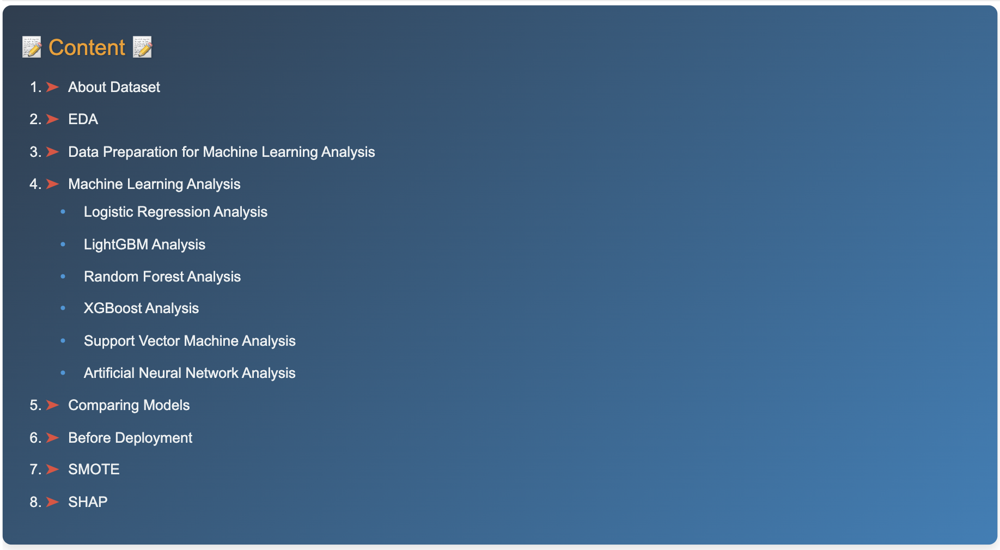

# About Dataset 

## General Overview
* ANSUR II (Anthropometric Survey of U.S. Army Personnel) is based on the results of a large-scale anthropometric (body measurements) survey conducted by the U.S. Army in 2012.

## Dataset Content
* ANSUR II contains body measurements and ethnic origin information of army personnel. The dataset includes over 100 measurements from different body parts of individuals. Measurements include details from various body regions such as head, hand, foot, leg, arm, chest, etc.
* The dataset contains 93 directly measured anthropometric measurements and 15 demographic/administrative variables as described below.
* The male dataset includes a sample of 4,082 subjects in total.
* The ANSUR II Female dataset includes a sample of 1,986 subjects in total.
* In addition to anthropometric and demographic data, the ANSUR II database also consists of 3D full-body, foot, and head scans of Soldier participants.

## Who Participated?
* This database includes representatives from various ethnic groups and age groups of active-duty army personnel. The dataset contains measurements taken from both men and women.

## Relationship Between Measurements and Ethnic Origin
* Different ethnic groups may have different body structures due to genetic and environmental factors. This can be observed with differences in measurements such as leg length, head structure, hand and foot measurements.

## Modeling and Prediction
* Ethnic origin prediction can be approached as a classification problem using body measurements in the ANSUR II dataset.
* The algorithm to be used learns the relationship between measurements and ethnic origin and can make ethnic origin predictions when applied to new data.

## Importance of the Project and Application Areas
* This type of research is used to analyze the body measurements of army personnel for the design and production of military equipment, clothing, and other systems. Accurate measurements are critical for the comfort, mobility, and overall safety of military personnel.
* It also has many potential commercial, industrial, and academic applications.
* Additionally, for example, ethnic origin could potentially be detected at an airport entrance using laser readers and sensors.

# Exploratory Data Analysis

**Retrieve data from the following links and create a data frame**

- Soldiers Male : https://query.data.world/s/h3pbhckz5ck4rc7qmt2wlknlnn7esr
- Soldiers Female : https://query.data.world/s/sq27zz4hawg32yfxksqwijxmpwmynq

- Drop unnecessary colums
- Drop DODRace class if value count below 500 (we assume that our data model can't learn if it is below 500)

In [ ]:
# Installs 

!pip install imbalanced-learn
!pip install lightgbm
!pip install bayesian-optimization
!pip install optuna
!pip install shap

In [89]:
# Standard Library Imports
import warnings
from functools import partial

# Data Manipulation and Analysis
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    make_scorer, precision_score, recall_score, roc_auc_score,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, cross_val_predict, cross_val_score,
    cross_validate, train_test_split, StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, LabelEncoder, MinMaxScaler, OneHotEncoder,
    StandardScaler
)
from sklearn.svm import SVC

# Ensemble and Boosting Models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import xgboost as xgb

# Imbalanced Learning
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Optimization
from bayes_opt import BayesianOptimization

# Parallel Processing
from joblib import Parallel, delayed
import joblib

# Explainable AI
import shap

# Image Processing
from PIL import Image

# Interactive Widgets
import ipywidgets as widgets
from IPython.display import display

In [90]:
pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_columns', 1000)
pd.set_option('display.width', 1000)

Let's understand following each code:

1. `pd.set_option('display.max_rows', 1000)`
   - This sets the maximum number of rows that will be displayed when you print a pandas DataFrame.
   - Default is typically much lower (around 60 rows).
   - Useful for viewing more rows of your data at once.

2. `pd.set_option('display.max_columns', 1000)`
   - Similar to max_rows, this sets the maximum number of columns that will be displayed.
   - Default is usually around 20 columns.
   - Helpful when working with datasets that have many columns.

3. `pd.set_option('display.width', 1000)`
   - This sets the maximum width (in characters) for displaying DataFrame columns.
   - Helps control how the data is wrapped when printed.
   - Useful for preventing column truncation in wide datasets.

These settings are particularly useful when working with large datasets, as they allow you to see more of your data at once without truncation. However, be cautious when using very large values, as it might make your output difficult to read or cause performance issues with extremely large datasets.

In [92]:
df1 = pd.read_csv("MALE_Public.csv", encoding='latin-1')
df1.head(1)

,subjectid,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,bideltoidbreadth,bimalleolarbreadth,bitragionchinarc,bitragionsubmandibulararc,bizygomaticbreadth,buttockcircumference,buttockdepth,buttockheight,buttockkneelength,buttockpopliteallength,calfcircumference,cervicaleheight,chestbreadth,chestcircumference,chestdepth,chestheight,crotchheight,crotchlengthomphalion,crotchlengthposterioromphalion,earbreadth,earlength,earprotrusion,elbowrestheight,eyeheightsitting,footbreadthhorizontal,footlength,forearmcenterofgriplength,forearmcircumferenceflexed,forearmforearmbreadth,forearmhandlength,functionalleglength,handbreadth,handcircumference,handlength,headbreadth,headcircumference,headlength,heelanklecircumference,heelbreadth,hipbreadth,hipbreadthsitting,iliocristaleheight,interpupillarybreadth,interscyei,interscyeii,kneeheightmidpatella,kneeheightsitting,lateralfemoralepicondyleheight,lateralmalleolusheight,lowerthighcircumference,mentonsellionlength,neckcircumference,neckcircumferencebase,overheadfingertipreachsitting,palmlength,poplitealheight,radialestylionlength,shouldercircumference,shoulderelbowlength,shoulderlength,sittingheight,sleevelengthspinewrist,sleeveoutseam,span,stature,suprasternaleheight,tenthribheight,thighcircumference,thighclearance,thumbtipreach,tibialheight,tragiontopofhead,trochanterionheight,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight,Gender,Date,Installation,Component,Branch,PrimaryMOS,SubjectsBirthLocation,SubjectNumericRace,Ethnicity,DODRace,Age,Heightin,Weightlbs,WritingPreference
0,10027,266,1467,337,222,1347,253,202,401,369,274,493,71,319,291,142,979,240,882,619,509,373,1535,291,1074,259,1292,877,607,351,36,71,19,247,802,101,273,349,299,575,477,1136,90,214,193,150,583,206,326,70,332,366,1071,685,422,441,502,560,500,77,391,118,400,436,1447,113,437,273,1151,368,145,928,883,600,1782,1776,1449,1092,610,164,786,491,140,919,1700,501,329,933,240,440,1054,815,175,853,Male,4-Oct-10,Fort Hood,Regular Army,Combat Arms,19D,North Dakota,1,NaN,1,41,71,180,Right hand


In [93]:
df2 = pd.read_csv("FEMALE_Public.csv", encoding='latin-1')
df2.head(1)

,SubjectId,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,bideltoidbreadth,bimalleolarbreadth,bitragionchinarc,bitragionsubmandibulararc,bizygomaticbreadth,buttockcircumference,buttockdepth,buttockheight,buttockkneelength,buttockpopliteallength,calfcircumference,cervicaleheight,chestbreadth,chestcircumference,chestdepth,chestheight,crotchheight,crotchlengthomphalion,crotchlengthposterioromphalion,earbreadth,earlength,earprotrusion,elbowrestheight,eyeheightsitting,footbreadthhorizontal,footlength,forearmcenterofgriplength,forearmcircumferenceflexed,forearmforearmbreadth,forearmhandlength,functionalleglength,handbreadth,handcircumference,handlength,headbreadth,headcircumference,headlength,heelanklecircumference,heelbreadth,hipbreadth,hipbreadthsitting,iliocristaleheight,interpupillarybreadth,interscyei,interscyeii,kneeheightmidpatella,kneeheightsitting,lateralfemoralepicondyleheight,lateralmalleolusheight,lowerthighcircumference,mentonsellionlength,neckcircumference,neckcircumferencebase,overheadfingertipreachsitting,palmlength,poplitealheight,radialestylionlength,shouldercircumference,shoulderelbowlength,shoulderlength,sittingheight,sleevelengthspinewrist,sleeveoutseam,span,stature,suprasternaleheight,tenthribheight,thighcircumference,thighclearance,thumbtipreach,tibialheight,tragiontopofhead,trochanterionheight,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight,Gender,Date,Installation,Component,Branch,PrimaryMOS,SubjectsBirthLocation,SubjectNumericRace,Ethnicity,DODRace,Age,Heightin,Weightlbs,WritingPreference
0,10037,231,1282,301,204,1180,222,177,373,315,263,466,65,338,301,141,1011,223,836,587,476,360,1336,274,922,245,1095,759,557,310,35,65,16,220,713,91,246,316,265,517,432,1028,75,182,184,141,548,191,314,69,345,388,966,645,363,399,435,496,447,55,404,118,335,368,1268,113,362,235,1062,327,148,803,809,513,1647,1560,1280,1013,622,174,736,430,110,844,1488,406,295,850,217,345,942,657,152,756,Female,5-Oct-10,Fort Hood,Regular Army,Combat Support,92Y,Germany,2,NaN,2,26,61,142,Right hand


In [94]:
# Let's check if the feature names of df1 and df2 are the same
if df1.columns.equals(df2.columns):
    print("Feature names match.")
else:
    print("Feature names do not match.")

Feature names do not match.


In [95]:
# Let's print the different features in df1 and df2
diff_df1 = set(df1.columns) - set(df2.columns)
diff_df2 = set(df2.columns) - set(df1.columns)

print("Sadece df1'de:", diff_df1) if diff_df1 else None
print("Sadece df2'de:", diff_df2) if diff_df2 else None

Sadece df1'de: {'subjectid'}
Sadece df2'de: {'SubjectId'}


In [96]:
df2.rename(columns={'SubjectId':'subjectid'}, inplace=True)


In [97]:
# We check whether the feature names of df1 and df2 are the same.
if df1.columns.equals(df2.columns):
    print("Feature names match.")
else:
    print("Feature names do not match.")

Feature names match.


In [98]:
# Merge df1 and df2 DataFrames and Display Head
data = pd.concat([df1,df2], axis=0, ignore_index=True)
df = data.copy()
df.head(1)

,subjectid,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,bideltoidbreadth,bimalleolarbreadth,bitragionchinarc,bitragionsubmandibulararc,bizygomaticbreadth,buttockcircumference,buttockdepth,buttockheight,buttockkneelength,buttockpopliteallength,calfcircumference,cervicaleheight,chestbreadth,chestcircumference,chestdepth,chestheight,crotchheight,crotchlengthomphalion,crotchlengthposterioromphalion,earbreadth,earlength,earprotrusion,elbowrestheight,eyeheightsitting,footbreadthhorizontal,footlength,forearmcenterofgriplength,forearmcircumferenceflexed,forearmforearmbreadth,forearmhandlength,functionalleglength,handbreadth,handcircumference,handlength,headbreadth,headcircumference,headlength,heelanklecircumference,heelbreadth,hipbreadth,hipbreadthsitting,iliocristaleheight,interpupillarybreadth,interscyei,interscyeii,kneeheightmidpatella,kneeheightsitting,lateralfemoralepicondyleheight,lateralmalleolusheight,lowerthighcircumference,mentonsellionlength,neckcircumference,neckcircumferencebase,overheadfingertipreachsitting,palmlength,poplitealheight,radialestylionlength,shouldercircumference,shoulderelbowlength,shoulderlength,sittingheight,sleevelengthspinewrist,sleeveoutseam,span,stature,suprasternaleheight,tenthribheight,thighcircumference,thighclearance,thumbtipreach,tibialheight,tragiontopofhead,trochanterionheight,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight,Gender,Date,Installation,Component,Branch,PrimaryMOS,SubjectsBirthLocation,SubjectNumericRace,Ethnicity,DODRace,Age,Heightin,Weightlbs,WritingPreference
0,10027,266,1467,337,222,1347,253,202,401,369,274,493,71,319,291,142,979,240,882,619,509,373,1535,291,1074,259,1292,877,607,351,36,71,19,247,802,101,273,349,299,575,477,1136,90,214,193,150,583,206,326,70,332,366,1071,685,422,441,502,560,500,77,391,118,400,436,1447,113,437,273,1151,368,145,928,883,600,1782,1776,1449,1092,610,164,786,491,140,919,1700,501,329,933,240,440,1054,815,175,853,Male,4-Oct-10,Fort Hood,Regular Army,Combat Arms,19D,North Dakota,1,NaN,1,41,71,180,Right hand


In [99]:
# This code provides numbers of row and columns, respectively 

df.shape

(6068, 108)

In [100]:
# Create a dataframe with data types and null counts
info_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Null Count': df.isnull().sum()
})

# Reset the index to make the column names a separate column
info_df = info_df.reset_index()
info_df.columns = ['Feature', 'Data Type', 'Null Count']

# Display the result
print(info_df)

                            Feature Data Type  Null Count
0                         subjectid     int64           0
1    abdominalextensiondepthsitting     int64           0
2                    acromialheight     int64           0
3             acromionradialelength     int64           0
4                anklecircumference     int64           0
5                      axillaheight     int64           0
6           balloffootcircumference     int64           0
7                  balloffootlength     int64           0
8                 biacromialbreadth     int64           0
9         bicepscircumferenceflexed     int64           0
10                 bicristalbreadth     int64           0
11                 bideltoidbreadth     int64           0
12               bimalleolarbreadth     int64           0
13                 bitragionchinarc     int64           0
14        bitragionsubmandibulararc     int64           0
15               bizygomaticbreadth     int64           0
16            

In [101]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
subjectid,6068.0,20757.198418,13159.390894,10027.0,14841.75,20063.5,27234.50,920103.0
abdominalextensiondepthsitting,6068.0,246.468688,37.400106,155.0,219.00,242.0,271.00,451.0
acromialheight,6068.0,1406.161338,79.091048,1115.0,1350.00,1410.0,1462.00,1683.0
acromionradialelength,6068.0,327.374423,20.720018,249.0,313.00,328.0,341.25,393.0
anklecircumference,6068.0,224.891397,16.051833,156.0,214.00,225.0,235.00,293.0
axillaheight,6068.0,1299.608767,72.022286,1038.0,1249.00,1302.0,1349.00,1553.0
balloffootcircumference,6068.0,244.192650,16.845020,186.0,232.00,245.0,256.00,306.0
balloffootlength,6068.0,194.754614,13.516368,151.0,185.00,195.0,204.00,245.0
biacromialbreadth,6068.0,399.204186,30.236914,283.0,376.00,404.0,421.00,489.0
bicepscircumferenceflexed,6068.0,340.934245,41.519866,216.0,311.00,341.0,370.00,490.0


In [102]:
df.duplicated().sum() 

0

In [103]:
df.drop("Ethnicity", axis=1, inplace=True)

In [104]:
df["SubjectsBirthLocation"].unique()

array(['North Dakota', 'New York', 'Wisconsin', 'North Carolina',
       'Kentucky', 'Mississippi', 'Romania', 'Arkansas', 'Maryland',
       'Arizona', 'South Carolina', 'California', 'Washington',
       'Virginia', 'Texas', 'Illinois', 'Puerto Rico', 'Georgia',
       'Colombia', 'El Salvador', 'Michigan', 'Missouri', 'Philippines',
       'Florida', 'Pennsylvania', 'West Virginia', 'Nebraska', 'Indiana',
       'Montana', 'Colorado', 'Mexico', 'Minnesota', 'Iowa', 'Peru',
       'Oklahoma', 'Massachusetts', 'District of Columbia', 'Ohio',
       'Louisiana', 'Oregon', 'Tennessee', 'Alaska', 'Connecticut',
       'Guam', 'Vietnam', 'Hawaii', 'Netherlands', 'Taiwan', 'Idaho',
       'New Mexico', 'Belgium', 'Japan', 'Maine', 'New Jersey', 'Morocco',
       'Alabama', 'Canada', 'Germany', 'Kansas', 'South Korea',
       'British Virgin Islands', 'Utah', 'US Virgin Islands', 'Nevada',
       'Guyana', 'Delaware', 'Jamaica', 'Cameroon', 'New Hampshire',
       'Nicaragua', 'United Kingd

**Drop unnecessary features to improve prediction**

**Heightin**
Height in Inches; self-reported, comparable to measured "stature"


**Weightlbs**
Weight in Pounds; self-reported, comparable to measured "weightkg"


**SubjectNumericRace**
Subject Numeric Race; a single or multi-digit code indicating a subject's self-reported race or races (verified through interview).
Where:
- 1 = White
- 2 = Black
- 3 = Hispanic
- 4 = Asian
- 5 = Native American
- 6 = Pacific Islander
- 8 = Other

**Installation**
U.S. Army installation where the measurement occurred; e.g. "Fort Hood", "Camp Shelby"

In [106]:
# Drop unnecessary features to improve prediction 

df.drop(["subjectid", "SubjectNumericRace", "Heightin", "Weightlbs", "Installation", "Date"], axis=1, inplace=True)

In [107]:
# Evaluate Target Values 

df["DODRace"].unique()

array([1, 2, 3, 4, 5, 6, 8])

**DODRace Explanation**

DODRace (Department of Defense Race) is a single digit indicating a subject's self-reported preferred single race where selecting multiple races is not an option. 


| Value | Race/Ethnicity    |
|-------|-------------------|
| 1     | White             |
| 2     | Black             |
| 3     | Hispanic          |
| 4     | Asian             |
| 5     | Native American   |
| 6     | Pacific Islander  |
| 8     | Other             |

*Reference*: https://data.world/datamil/ansur-ii-data-dictionary/workspace/file?filename=ANSUR+II+Databases+Overview.pdf

In [109]:
# Mapping Target Value 

df["DODRace"] = df.DODRace.map({
    1: "White",
    2: "Black",
    3: "Hispanic",
    4: "Asian",
    5: "Native American",
    6: "Pacific Islander",
    8: "Other"
})

In [110]:
# We will not work with DODraces with less than 500 row data for each target value . 

df.DODRace.value_counts()   

DODRace
White               3792
Black               1298
Hispanic             679
Asian                188
Pacific Islander      59
Native American       49
Other                  3
Name: count, dtype: int64

In [111]:
# Since there are more than 500 data in in white, black and hispanic only, we keep them and remove the others.

df = df[df.DODRace.isin(["White", "Black", "Hispanic"])]


In [112]:
df["DODRace"].unique()

array(['White', 'Black', 'Hispanic'], dtype=object)

DODRace
White       3792
Black       1298
Hispanic     679
Name: count, dtype: int64


<Axes: xlabel='DODRace'>

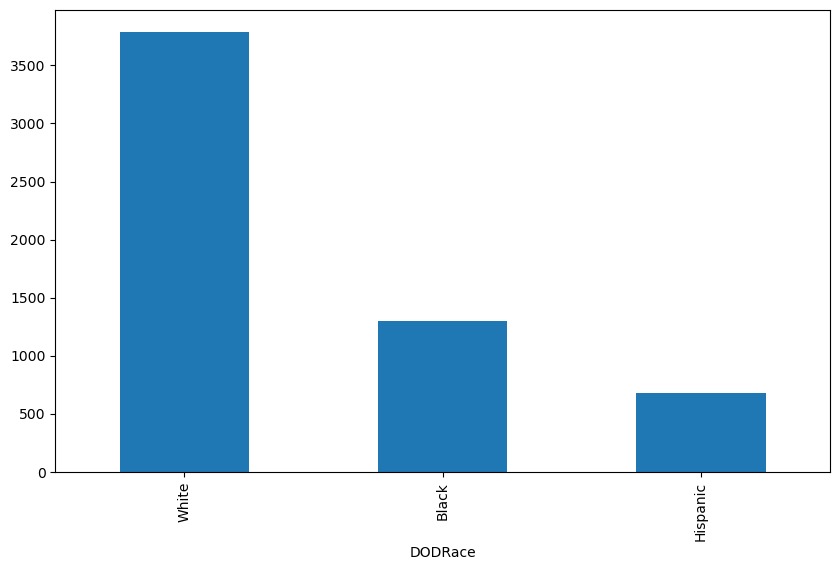

In [113]:
# Print Each Race Value 
print(df["DODRace"].value_counts())

# Prepare Bar Graph 
df["DODRace"].value_counts().plot(kind="bar", figsize=(10,6))

In [114]:
# After removing unnecessary features, we would like to see numbers of rows and columns in current dataframe
df.shape

(5769, 101)

In [115]:
df.isnull().sum()

abdominalextensiondepthsitting    0
acromialheight                    0
acromionradialelength             0
anklecircumference                0
axillaheight                      0
balloffootcircumference           0
balloffootlength                  0
biacromialbreadth                 0
bicepscircumferenceflexed         0
bicristalbreadth                  0
bideltoidbreadth                  0
bimalleolarbreadth                0
bitragionchinarc                  0
bitragionsubmandibulararc         0
bizygomaticbreadth                0
buttockcircumference              0
buttockdepth                      0
buttockheight                     0
buttockkneelength                 0
buttockpopliteallength            0
calfcircumference                 0
cervicaleheight                   0
chestbreadth                      0
chestcircumference                0
chestdepth                        0
chestheight                       0
crotchheight                      0
crotchlengthomphalion       

In [116]:
# Shows only Object Features 

df.select_dtypes("object")

,Gender,Component,Branch,PrimaryMOS,SubjectsBirthLocation,DODRace,WritingPreference
0,Male,Regular Army,Combat Arms,19D,North Dakota,White,Right hand
1,Male,Regular Army,Combat Support,68W,New York,White,Left hand
2,Male,Regular Army,Combat Support,68W,New York,Black,Left hand
3,Male,Regular Army,Combat Service Support,88M,Wisconsin,White,Right hand
4,Male,Regular Army,Combat Service Support,92G,North Carolina,Black,Right hand
...,...,...,...,...,...,...,...
6063,Female,Army National Guard,Combat Support,42A,Texas,Hispanic,Right hand
6064,Female,Army National Guard,Combat Support,25U,Texas,Hispanic,Right hand
6065,Female,Army National Guard,Combat Support,42A,Texas,Black,Right hand
6066,Female,Army National Guard,Combat Support,92Y,Texas,Hispanic,Right hand


In [117]:
# Organize Dataset using Reset Index
df = df.reset_index(drop=True)


In [118]:
df

,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,bideltoidbreadth,bimalleolarbreadth,bitragionchinarc,bitragionsubmandibulararc,bizygomaticbreadth,buttockcircumference,buttockdepth,buttockheight,buttockkneelength,buttockpopliteallength,calfcircumference,cervicaleheight,chestbreadth,chestcircumference,chestdepth,chestheight,crotchheight,crotchlengthomphalion,crotchlengthposterioromphalion,earbreadth,earlength,earprotrusion,elbowrestheight,eyeheightsitting,footbreadthhorizontal,footlength,forearmcenterofgriplength,forearmcircumferenceflexed,forearmforearmbreadth,forearmhandlength,functionalleglength,handbreadth,handcircumference,handlength,headbreadth,headcircumference,headlength,heelanklecircumference,heelbreadth,hipbreadth,hipbreadthsitting,iliocristaleheight,interpupillarybreadth,interscyei,interscyeii,kneeheightmidpatella,kneeheightsitting,lateralfemoralepicondyleheight,lateralmalleolusheight,lowerthighcircumference,mentonsellionlength,neckcircumference,neckcircumferencebase,overheadfingertipreachsitting,palmlength,poplitealheight,radialestylionlength,shouldercircumference,shoulderelbowlength,shoulderlength,sittingheight,sleevelengthspinewrist,sleeveoutseam,span,stature,suprasternaleheight,tenthribheight,thighcircumference,thighclearance,thumbtipreach,tibialheight,tragiontopofhead,trochanterionheight,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight,Gender,Component,Branch,PrimaryMOS,SubjectsBirthLocation,DODRace,Age,WritingPreference
0,266,1467,337,222,1347,253,202,401,369,274,493,71,319,291,142,979,240,882,619,509,373,1535,291,1074,259,1292,877,607,351,36,71,19,247,802,101,273,349,299,575,477,1136,90,214,193,150,583,206,326,70,332,366,1071,685,422,441,502,560,500,77,391,118,400,436,1447,113,437,273,1151,368,145,928,883,600,1782,1776,1449,1092,610,164,786,491,140,919,1700,501,329,933,240,440,1054,815,175,853,Male,Regular Army,Combat Arms,19D,North Dakota,White,41,Right hand
1,233,1395,326,220,1293,245,193,394,338,257,479,67,344,320,135,944,232,870,584,468,357,1471,269,1021,253,1244,851,615,376,33,62,18,232,781,98,263,348,289,523,476,1096,86,203,195,146,568,201,334,72,312,356,1046,620,441,447,490,540,488,73,371,131,380,420,1380,118,417,254,1119,353,141,884,868,564,1745,1702,1387,1076,572,169,822,476,120,918,1627,432,316,870,225,371,1054,726,167,815,Male,Regular Army,Combat Support,68W,New York,White,35,Left hand
2,287,1430,341,230,1327,256,196,427,408,261,544,75,345,330,135,1054,258,901,623,506,412,1501,288,1120,267,1288,854,636,359,40,61,23,237,810,103,270,355,357,575,491,1115,93,220,203,148,573,202,356,70,349,393,1053,665,462,475,496,556,482,72,409,123,403,434,1447,121,431,268,1276,367,167,917,910,604,1867,1735,1438,1105,685,198,807,477,125,918,1678,472,329,964,255,411,1041,929,180,831,Male,Regular Army,Combat Support,68W,New York,Black,42,Left hand
3,234,1347,310,230,1239,262,199,401,359,262,518,73,328,309,143,991,242,821,560,437,395,1423,296,1114,262,1205,769,590,341,39,66,25,272,794,106,267,352,318,593,467,1034,91,217,194,158,576,199,341,68,338,367,986,640,458,461,460,511,452,76,393,106,407,446,1357,118,393,249,1155,330,148,903,848,550,1708,1655,1346,1021,604,180,803,445,127,847,1625,461,315,857,205,399,968,794,176,793,Male,Regular Army,Combat Service Support,88M,Wisconsin,White,31,Right hand
4,250,1585,372,247,1478,267,224,435,356,263,524,80,340,310,138,1029,275,1080,706,567,425,1684,304,1048,232,1452,1014,682,382,32,56,19,188,814,111,305,399,324,605,550,1279,94,222,218,153,566,197,374,69,332,372,1251,675,481,505,612,666,585,85,458,135,398,430,1572,132,523,302,1231,400,180,919,995,641,2035,1914,1596,1292,672,194,962,584,122,1090,1679,467,303,868,214,379,1245,946,188,954,Male,Regular Army,Combat Service Support,92G,North Carolina,Black,21,Right ha

In [119]:
# This function identifies and returns pairs of numerical columns in a DataFrame
# that have a correlation coefficient higher than a specified threshold (0.92), 
# helping to detect strongly correlated features in the dataset. 

def high_correlation(df, threshold=0.90):

    corr_matrix = df.select_dtypes(include=[np.number]).corr()
    

    high_corr_var = [(col1, col2, corr_matrix[col1][col2]) 
                     for col1 in corr_matrix.columns 
                     for col2 in corr_matrix.columns 
                     if col1 != col2 and abs(corr_matrix[col1][col2]) > threshold]

    return pd.DataFrame(high_corr_var, columns=['Column 1', 'Column 2', 'Correlation'])


high_corr_df = high_correlation(df)
print(high_corr_df)

                           Column 1                        Column 2  Correlation
0    abdominalextensiondepthsitting              waistcircumference     0.939645
1    abdominalextensiondepthsitting                      waistdepth     0.958716
2                    acromialheight                    axillaheight     0.987115
3                    acromialheight                 cervicaleheight     0.983955
4                    acromialheight                     chestheight     0.959300
5                    acromialheight              iliocristaleheight     0.932232
6                    acromialheight               kneeheightsitting     0.931762
7                    acromialheight                         stature     0.979925
8                    acromialheight             suprasternaleheight     0.984711
9                    acromialheight                  tenthribheight     0.945019
10                   acromialheight            waistheightomphalion     0.930954
11                   acromia

# Data Preparation for Machine Learning Analysis

- In this step we divide our data to X(Features) and y(Target) then ,
- To train and evaluation purposes we create train and test sets,
- Lastly, scale our data if features not in same scale. Why?

In [121]:
df.drop(columns=["PrimaryMOS", "Branch"], inplace=True)

**Component**
One of:
- "Army National Guard"
- "Army Reserve"
- "Regular Army"

**Branch**
One of:
- "Combat Arms"
- "Combat Support"
- "Combat Service Support"

**PrimaryMOS**
Primary Military Occupational Specialty (Askeri Mesleki Uzmanligi)

In [123]:
df.head(1).T

,0
abdominalextensiondepthsitting,266
acromialheight,1467
acromionradialelength,337
anklecircumference,222
axillaheight,1347
balloffootcircumference,253
balloffootlength,202
biacromialbreadth,401
bicepscircumferenceflexed,369
bicristalbreadth,274


In [39]:
df.shape

(5769, 99)

# Machine Learning Analysis
- Fit the model with train dataset
- Get predict from vanilla model on both train and test sets to examine if there is over/underfitting   
- Apply GridseachCV for both hyperparemeter tuning and sanity test of our model.
- Use hyperparameters that you find from gridsearch and make final prediction and evaluate the result according to chosen metric.

## Logistic Regression Analysis

### Logistic Regression (Vanilla) Model_1

In [44]:
X = df.drop(columns= ["DODRace"])
y = df.DODRace

In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify = y)

# stratify=y preserves the target variable's class distribution in train and test sets
# Useful for imbalanced datasets where some classes have significantly more samples
# Ensures fair representation of all classes during model training and evaluation

In [46]:
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred))

In [47]:
# Select Categoric Data
cat = X_train.select_dtypes("object").columns
cat 

Index(['Gender', 'Component', 'SubjectsBirthLocation', 'WritingPreference'], dtype='object')



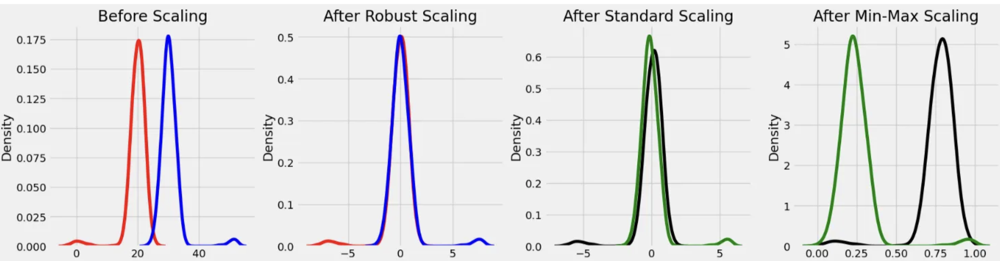


Reference: https://medium.com/@hhuseyincosgun/which-data-scaling-technique-should-i-use-a1615292061e 


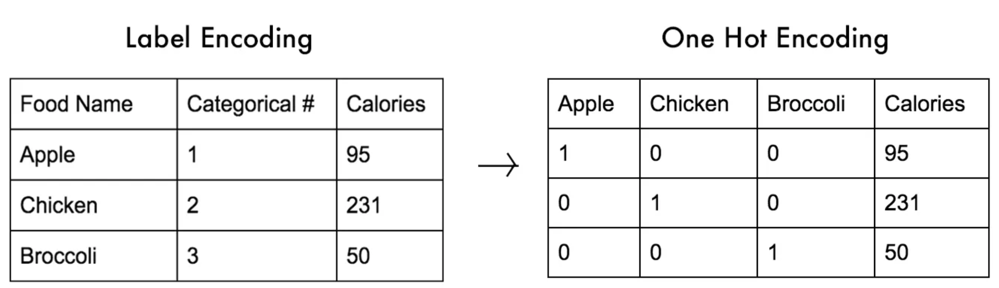

Reference: https://medium.com/@michaeldelsole/what-is-one-hot-encoding-and-how-to-do-it-f0ae272f1179 

In [48]:
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

In [49]:
operations = [("OneHotEncoder", column_trans), ("log", LogisticRegression(class_weight='balanced',max_iter=10000,
                                                                          random_state=101))]

In [50]:
pipe_log_model = Pipeline(steps=operations)

In [51]:
pipe_log_model.fit(X_train,y_train)

Pipeline(steps=[('OneHotEncoder',
                 ColumnTransformer(remainder=MinMaxScaler(),
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  Index(['Gender', 'Component', 'SubjectsBirthLocation', 'WritingPreference'], dtype='object'))])),
                ('log',
                 LogisticRegression(class_weight='balanced', max_iter=10000,
                                    random_state=101))])

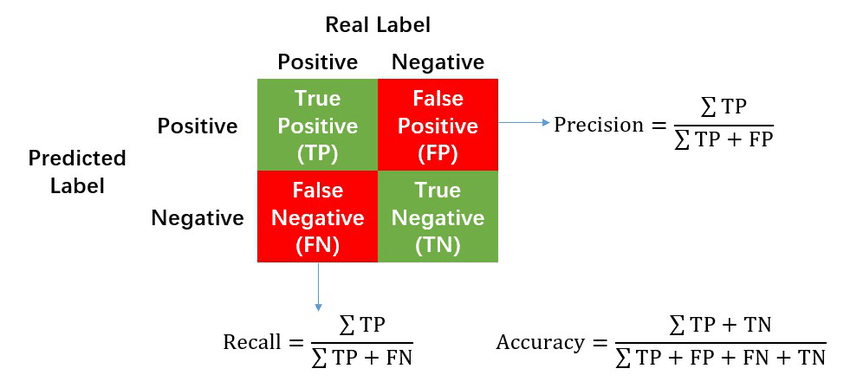

In [52]:
eval_metric(pipe_log_model, X_train, y_train, X_test, y_test)

# There is no overfitting between the Train and Test sets.
# The scores of the White and Black classes are very high.
# The White and Black classes have better results of precision, recall and f1-score than Hispanic.
# There are differences between the values in the Hispanic class.
# In our next steps, we will work on improving the Precision, Recall and F1 scores of the Hispanic class

Test_Set
[[240  14   6]
 [  4 110  22]
 [ 26  87 645]]
              precision    recall  f1-score   support

       Black       0.89      0.92      0.91       260
    Hispanic       0.52      0.81      0.63       136
       White       0.96      0.85      0.90       758

    accuracy                           0.86      1154
   macro avg       0.79      0.86      0.81      1154
weighted avg       0.89      0.86      0.87      1154


Train_Set
[[ 970   38   30]
 [  18  457   68]
 [  58  356 2620]]
              precision    recall  f1-score   support

       Black       0.93      0.93      0.93      1038
    Hispanic       0.54      0.84      0.66       543
       White       0.96      0.86      0.91      3034

    accuracy                           0.88      4615
   macro avg       0.81      0.88      0.83      4615
weighted avg       0.91      0.88      0.89      4615



_Comparing Class Weights and SMOTE_

The main differences between these two approaches are:

> **Data modification**
> * Class weights don't change the dataset
> * SMOTE creates new synthetic samples

> **Computational cost**
> * Class weights are generally less computationally expensive than SMOTE

> **Interpretability**
> * Class weights maintain the original data structure
> * SMOTE may affect feature relationships and importance

In [217]:
from IPython.display import HTML, display
import json

comparison_data = {
    "Class Weights": [
        {"aspect": "Approach", "description": "Adjusts the importance of classes during model training"},
        {"aspect": "Data Modification", "description": "Does not modify the original dataset"},
        {"aspect": "Impact on Model", "description": "Affects the loss function and decision boundary"},
        {"aspect": "Computational Cost", "description": "Generally lower, as it doesn't create new samples"},
        {"aspect": "Flexibility", "description": "Can be easily adjusted by changing weight values"}
    ],
    "Enhanced SMOTE": [
        {"aspect": "Approach", "description": "Creates synthetic samples of minority classes"},
        {"aspect": "Data Modification", "description": "Increases the number of samples in the training set"},
        {"aspect": "Impact on Model", "description": "Changes the distribution of the training data"},
        {"aspect": "Computational Cost", "description": "Higher, due to the creation of synthetic samples"},
        {"aspect": "Flexibility", "description": "Offers control over the degree of oversampling"}
    ]
}

html_template = """
<div id="comparison-container" style="font-family: Arial, sans-serif; max-width: 800px; margin: 0 auto;">
    <style>
        .tab {
            overflow: hidden;
            border: 1px solid #ccc;
            background-color: #f1f1f1;
        }
        .tab button {
            background-color: inherit;
            float: left;
            border: none;
            outline: none;
            cursor: pointer;
            padding: 14px 16px;
            transition: 0.3s;
            font-size: 17px;
        }
        .tab button:hover {
            background-color: #ddd;
        }
        .tab button.active {
            background-color: #ccc;
        }
        .tabcontent {
            display: none;
            padding: 6px 12px;
            border: 1px solid #ccc;
            border-top: none;
        }
        .aspect-card {
            background-color: #f9f9f9;
            border: 1px solid #ddd;
            border-radius: 4px;
            padding: 10px;
            margin-bottom: 10px;
        }
        .aspect-card h3 {
            margin-top: 0;
            color: #333;
        }
        .aspect-card p {
            margin-bottom: 0;
            color: #666;
        }
    </style>
    <div class="tab">
        <button class="tablinks" onclick="openMethod(event, 'ClassWeights')" id="defaultOpen">Class Weights</button>
        <button class="tablinks" onclick="openMethod(event, 'EnhancedSMOTE')">Enhanced SMOTE</button>
    </div>

    <div id="ClassWeights" class="tabcontent"></div>
    <div id="EnhancedSMOTE" class="tabcontent"></div>

    <script>
        function openMethod(evt, methodName) {
            var i, tabcontent, tablinks;
            tabcontent = document.getElementsByClassName("tabcontent");
            for (i = 0; i < tabcontent.length; i++) {
                tabcontent[i].style.display = "none";
            }
            tablinks = document.getElementsByClassName("tablinks");
            for (i = 0; i < tablinks.length; i++) {
                tablinks[i].className = tablinks[i].className.replace(" active", "");
            }
            document.getElementById(methodName).style.display = "block";
            evt.currentTarget.className += " active";
        }

        var comparisonData = {comparison_json};

        function populateContent() {
            for (let method in comparisonData) {
                let contentDiv = document.getElementById(method.replace(' ', ''));
                comparisonData[method].forEach(item => {
                    let card = document.createElement('div');
                    card.className = 'aspect-card';
                    card.innerHTML = `<h3>${item.aspect}</h3><p>${item.description}</p>`;
                    contentDiv.appendChild(card);
                });
            }
        }

        populateContent();
        document.getElementById("defaultOpen").click();
    </script>
</div>
"""

html_content = html_template.replace('{comparison_json}', json.dumps(comparison_data))
display(HTML(html_content))

### Logistic Regression (Enhanced Smote, no hyperparameters,  Labelencoder) Model_2

In [54]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(pd.Series(y_train_encoded).map(lambda x: le.classes_[x]).value_counts())

# Function to get enhanced SMOTE strategy with more emphasis on minority class
def get_enhanced_smote_strategy(y):
    class_counts = np.bincount(y)
    majority_class_count = np.max(class_counts)
    minority_class = np.argmin(class_counts)
    strategy = {i: majority_class_count for i in range(len(class_counts))}
    strategy[minority_class] = int(majority_class_count * 2)  # Oversample minority class even more
    return strategy

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the pipeline with enhanced SMOTE
operations = [
    ("preprocessor", column_trans),
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train_encoded), random_state=42)),
    ("classifier", LogisticRegression(class_weight='balanced', max_iter=10000, random_state=101))
]

# Create and fit the pipeline
imb_pipe = ImbPipeline(steps=operations)
imb_pipe.fit(X_train, y_train_encoded)

# Evaluate the model
eval_metric(imb_pipe, X_train, y_train_encoded, X_test, y_test_encoded)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# F1 score used specifically for the minority class, 
# so it effectively just calculates the F1 score for that single class.


# Print the new class distribution after SMOTE
smote_step = imb_pipe.named_steps['smote']
X_resampled, y_resampled = smote_step.fit_resample(
    imb_pipe.named_steps['preprocessor'].transform(X_train),
    y_train_encoded
)
print("\nNew class distribution after SMOTE:")
print(pd.Series(y_resampled).map(lambda x: le.classes_[x]).value_counts())

print("\nModel performance metrics:")
y_pred = imb_pipe.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# If you want to use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(imb_pipe, X_test, y_test_encoded))

Original class distribution in training set:
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Test_Set
[[234  16  10]
 [  6 104  26]
 [ 11  84 663]]
              precision    recall  f1-score   support

       Black       0.93      0.90      0.92       260
    Hispanic       0.51      0.76      0.61       136
       White       0.95      0.87      0.91       758

    accuracy                           0.87      1154
   macro avg       0.80      0.85      0.81      1154
weighted avg       0.89      0.87      0.88      1154


Train_Set
[[ 971   29   38]
 [  20  448   75]
 [  54  311 2669]]
              precision    recall  f1-score   support

       Black       0.93      0.94      0.93      1038
    Hispanic       0.57      0.83      0.67       543
       White       0.96      0.88      0.92      3034

    accuracy                           0.89      4615
   macro avg       0.82      0.88      0.84      4615
weighted avg       0.91      0.89      0.89      4

_Adjusting Custom Thresholds_

> **Purpose of using a custom threshold**
>   - Lowering the threshold for 'Hispanic' would make the model more likely to predict 'Hispanic', potentially increasing recall for this class but possibly reducing precision.
>   - Raising the threshold would make the model less likely to predict 'Hispanic', potentially increasing precision but reducing recall.

### Logistic Regression (Class Weights and Threshold) Model_3 (Best Result)

In [56]:
# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat = X_train.select_dtypes("object").columns

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define class weights
class_weights = {
    'Black': 1.5,
    'Hispanic': 2.2,
    'White': 1
}

# Define the pipeline operations
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(class_weight=class_weights, max_iter=10000, random_state=42))
]

# Create and fit the pipeline
log_model_threshold = Pipeline(steps=operations)
log_model_threshold.fit(X_train, y_train)

# Define the custom threshold prediction function
def predict_with_threshold(model, X, threshold=0.5):
    proba = model.predict_proba(X)
    return np.where(proba[:, model.named_steps['log'].classes_.tolist().index('Hispanic')] > threshold, 'Hispanic', model.predict(X))

# Make predictions with custom threshold
y_pred_custom = predict_with_threshold(log_model_threshold, X_test)

# Evaluate the model with custom threshold
print("Test Set Results with Custom Threshold:")
print(confusion_matrix(y_test, y_pred_custom))
print(classification_report(y_test, y_pred_custom))

# Compare with standard predictions
y_pred_standard = log_model_threshold.predict(X_test)
print("\nTest Set Results with Standard Prediction:")
print(confusion_matrix(y_test, y_pred_standard))
print(classification_report(y_test, y_pred_standard))

Test Set Results with Custom Threshold:
[[240   7  13]
 [  5  97  34]
 [ 16  34 708]]
              precision    recall  f1-score   support

       Black       0.92      0.92      0.92       260
    Hispanic       0.70      0.71      0.71       136
       White       0.94      0.93      0.94       758

    accuracy                           0.91      1154
   macro avg       0.85      0.86      0.86      1154
weighted avg       0.91      0.91      0.91      1154


Test Set Results with Standard Prediction:
[[240   7  13]
 [  5  97  34]
 [ 16  34 708]]
              precision    recall  f1-score   support

       Black       0.92      0.92      0.92       260
    Hispanic       0.70      0.71      0.71       136
       White       0.94      0.93      0.94       758

    accuracy                           0.91      1154
   macro avg       0.85      0.86      0.86      1154
weighted avg       0.91      0.91      0.91      1154



_Solver and L1 Regularization in Logistic Regression_

> **Solver**
> * The solver is the algorithm used to find the optimal weights for the logistic regression model.
> * "liblinear" is a linear classifier that can handle L1 and L2 regularization.
> * It's particularly efficient for datasets with a large number of samples or features, especially when combined with L1 regularization.

> **L1 Regularization (penalty="l1")**

> * L1 regularization, also known as Lasso regularization, is a technique used to prevent overfitting in machine learning models.

> **Key characteristics of L1 regularization**

> * Feature selection: 
>   - L1 tends to produce sparse models by driving some coefficients to exactly zero.
>   - This effectively performs feature selection, as features with zero coefficients are eliminated from the model.
> * Robustness to outliers: 
>   - L1 is less sensitive to outliers compared to L2 regularization.
> * Useful for high-dimensional data: 
>   - It's particularly effective when you have a large number of features but suspect only a subset are truly important.

### Logistic Regression (Solver = liblinear, penalty=l1) Model_4

In [58]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(pd.Series(y_train).value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the updated pipeline
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(class_weight='balanced', max_iter=10000, random_state=42, solver="liblinear", penalty="l1"))
]

# Create and fit the pipeline
pipe = Pipeline(steps=operations)
pipe.fit(X_train, y_train_encoded)

# Evaluate the model
eval_metric(pipe, X_train, y_train_encoded, X_test, y_test_encoded)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = pipe.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(pipe, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Test_Set
[[239   8  13]
 [  8  90  38]
 [  9  38 711]]
              precision    recall  f1-score   support

       Black       0.93      0.92      0.93       260
    Hispanic       0.66      0.66      0.66       136
       White       0.93      0.94      0.94       758

    accuracy                           0.90      1154
   macro avg       0.84      0.84      0.84      1154
weighted avg       0.90      0.90      0.90      1154


Train_Set
[[ 979   13   46]
 [  28  375  140]
 [  52  146 2836]]
              precision    recall  f1-score   support

       Black       0.92      0.94      0.93      1038
    Hispanic       0.70      0.69      0.70       543
       White       0.94      0.93      0.94      3034

    accuracy                           0.91      4615
   macro avg       0.86      0.86      0.86      4615
weighted avg       0.91      0.91      0.9

### Logistic Regression (Hyperparamaters, GridSearchCV) - Model_5

In [219]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the updated pipeline
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(random_state=101))
]

# Create the pipeline
pipe = Pipeline(steps=operations)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Define the parameter grid
param_grid = {
    'log__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'log__penalty': ['l1', 'l2'],
    'log__solver': ['liblinear', 'saga'],
    'log__class_weight': ['balanced', None],
    'log__max_iter': [8000]
}

# Create GridSearchCV object
grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring=minority_class_scorer, n_jobs=-1)

# Fit GridSearchCV
grid_search.fit(X_train, y_train_encoded)

# Print the best parameters and score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Use the best model for prediction
best_model = grid_search.best_estimator_

# Evaluate the best model
eval_metric(best_model, X_train, y_train_encoded, X_test, y_test_encoded)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = best_model.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(best_model, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Best parameters: {'log__C': 1, 'log__class_weight': 'balanced', 'log__max_iter': 8000, 'log__penalty': 'l1', 'log__solver': 'liblinear'}
Best score: 0.6543079724811344
Test_Set
[[239   8  13]
 [  8  90  38]
 [  9  38 711]]
              precision    recall  f1-score   support

       Black       0.93      0.92      0.93       260
    Hispanic       0.66      0.66      0.66       136
       White       0.93      0.94      0.94       758

    accuracy                           0.90      1154
   macro avg       0.84      0.84      0.84      1154
weighted avg       0.90      0.90      0.90      1154


Train_Set
[[ 979   13   46]
 [  28  375  140]
 [  52  146 2836]]
              precision    recall  f1-score   support

       Black       0.92      0.94      0.93      1038
    Hispanic       0.70      0.69      0.70       543
       White       0.94      0.93    

### Logistic Regression (Elastic Net, GridSearchCV) - Model_6

In [62]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, f1_score, make_scorer
from sklearn.pipeline import Pipeline


# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the updated pipeline
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(random_state=101))
]

# Create the pipeline
pipe = Pipeline(steps=operations)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Define the parameter grid
param_grid_elasticnet = {
    'log__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'log__penalty': ['elasticnet'],
    'log__solver': ['saga'],
    'log__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
    'log__class_weight': ['balanced', None],
    'log__max_iter': [10000]
}

# Create GridSearchCV object
grid_search_elasticnet = GridSearchCV(pipe, param_grid_elasticnet, cv=5, scoring=minority_class_scorer, n_jobs=-1)

# Fit GridSearchCV
grid_search_elasticnet.fit(X_train, y_train_encoded)

# Print the best parameters and score
print("Best parameters (Elasticnet):", grid_search_elasticnet.best_params_)
print("Best score (Elasticnet):", grid_search_elasticnet.best_score_)

# Use the best model for prediction and evaluation
best_model_elasticnet = grid_search_elasticnet.best_estimator_
eval_metric(best_model_elasticnet, X_train, y_train_encoded, X_test, y_test_encoded)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = best_model.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(best_model, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Best parameters (Elasticnet): {'log__C': 10, 'log__class_weight': None, 'log__l1_ratio': 0.5, 'log__max_iter': 10000, 'log__penalty': 'elasticnet', 'log__solver': 'saga'}
Best score (Elasticnet): 0.6454985408312057
Test_Set
[[235   9  16]
 [  6  80  50]
 [  5  21 732]]
              precision    recall  f1-score   support

       Black       0.96      0.90      0.93       260
    Hispanic       0.73      0.59      0.65       136
       White       0.92      0.97      0.94       758

    accuracy                           0.91      1154
   macro avg       0.87      0.82      0.84      1154
weighted avg       0.90      0.91      0.90      1154


Train_Set
[[ 973    9   56]
 [  21  343  179]
 [  31   62 2941]]
              precision    recall  f1-score   support

       Black       0.95      0.94      0.94      1038
    Hispanic       0.83      0.63      0.72 

### Logistic Regression (None Penalty, GridSearchCV) - Model_7

In [64]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the updated pipeline
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(random_state=101))
]

# Create the pipeline
pipe = Pipeline(steps=operations)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)


param_grid_none = {
    'log__penalty': [None],
    'log__solver': ['newton-cg', 'lbfgs', 'sag', 'saga'],
    'log__class_weight': ['balanced', None],
    'log__max_iter': [10000]
}
# Create GridSearchCV object
grid_search_none = GridSearchCV(pipe, param_grid_none, cv=5, scoring=minority_class_scorer, n_jobs=-1)

# Fit GridSearchCV
grid_search_none.fit(X_train, y_train_encoded)

# Print the best parameters and score
print("Best parameters (No Penalty):", grid_search_none.best_params_)
print("Best score (No Penalty):", grid_search_none.best_score_)

# Use the best model for prediction and evaluation
best_model_none = grid_search_none.best_estimator_
eval_metric(best_model_none, X_train, y_train_encoded, X_test, y_test_encoded)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = best_model.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(best_model, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Best parameters (No Penalty): {'log__class_weight': None, 'log__max_iter': 10000, 'log__penalty': None, 'log__solver': 'lbfgs'}
Best score (No Penalty): 0.6402924793503733
Test_Set
[[236   9  15]
 [  6  78  52]
 [  9  24 725]]
              precision    recall  f1-score   support

       Black       0.94      0.91      0.92       260
    Hispanic       0.70      0.57      0.63       136
       White       0.92      0.96      0.94       758

    accuracy                           0.90      1154
   macro avg       0.85      0.81      0.83      1154
weighted avg       0.90      0.90      0.90      1154


Train_Set
[[ 982    7   49]
 [  20  355  168]
 [  24   72 2938]]
              precision    recall  f1-score   support

       Black       0.96      0.95      0.95      1038
    Hispanic       0.82      0.65      0.73       543
       White       0.93      0.97

### Logistic Regression (SAG, Newton-CG, and LBFGS Solvers, GridSearchCV) - Model_8

In [66]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the updated pipeline
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(random_state=101))
]

# Create the pipeline
pipe = Pipeline(steps=operations)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

param_grid_combined = {
    'log__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'log__penalty': ['l2', 'none'],
    'log__solver': ['sag', 'newton-cg', 'lbfgs'],
    'log__class_weight': ['balanced', None],
    'log__max_iter': [10000]
}

# Create GridSearchCV object
grid_search_combined = GridSearchCV(pipe, param_grid_combined, cv=5, scoring=minority_class_scorer, n_jobs=-1)

# Fit GridSearchCV
grid_search_combined.fit(X_train, y_train_encoded)

# Print the best parameters and score
print("Best parameters (Combined):", grid_search_combined.best_params_)
print("Best score (Combined):", grid_search_combined.best_score_)

# Use the best model for prediction and evaluation
best_model_combined = grid_search_combined.best_estimator_
eval_metric(best_model_combined, X_train, y_train_encoded, X_test, y_test_encoded)



# Print model performance metrics
print("\nModel performance metrics:")
y_pred = best_model.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(best_model, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Best parameters (Combined): {'log__C': 10, 'log__class_weight': None, 'log__max_iter': 10000, 'log__penalty': 'l2', 'log__solver': 'lbfgs'}
Best score (Combined): 0.6510153222559562
Test_Set
[[235   9  16]
 [  5  82  49]
 [  4  24 730]]
              precision    recall  f1-score   support

       Black       0.96      0.90      0.93       260
    Hispanic       0.71      0.60      0.65       136
       White       0.92      0.96      0.94       758

    accuracy                           0.91      1154
   macro avg       0.86      0.82      0.84      1154
weighted avg       0.90      0.91      0.90      1154


Train_Set
[[ 972    9   57]
 [  21  341  181]
 [  31   61 2942]]
              precision    recall  f1-score   support

       Black       0.95      0.94      0.94      1038
    Hispanic       0.83      0.63      0.71       543
       White       0.93

### Logistic Regression (Bayesian Optimization, Elastic Net, Saga) Model_9

In [68]:
# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Label encode the target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(y_train.value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Modify the objective function to use cross-validation
def objective(C, l1_ratio):
    operations = [
        ("OneHotEncoder", column_trans),
        ("log", LogisticRegression(C=C, class_weight='balanced', max_iter=10000, 
                                   random_state=101, solver="saga", penalty="elasticnet", 
                                   l1_ratio=l1_ratio, n_jobs=-1))  # Use all available CPUs
    ]
    pipe = Pipeline(steps=operations)
    
    # Use cross-validation score
    scores = cross_val_score(pipe, X_train, y_train_encoded, cv=5, scoring=minority_class_scorer, n_jobs=-1)
    return np.mean(scores)

# Define the parameter space
pbounds = {
    'C': (0.001, 10),
    'l1_ratio': (0, 1)
}

# Perform Bayesian Optimization
optimizer = BayesianOptimization(
    f=objective,
    pbounds=pbounds,
    random_state=101,
    verbose=2
)

optimizer.maximize(init_points=5, n_iter=25)

# Get the best parameters
best_params = optimizer.max['params']
print("Best parameters:", best_params)

# Create the final model with the best parameters
final_operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(C=best_params['C'], class_weight='balanced', max_iter=10000, 
                               random_state=101, solver="saga", penalty="elasticnet", 
                               l1_ratio=best_params['l1_ratio'], n_jobs=-1))  # Use all available CPUs
]

final_pipe = Pipeline(steps=final_operations)
final_pipe.fit(X_train, y_train_encoded)

# Evaluate the final model
print("\nFinal Model Evaluation:")
eval_metric(final_pipe, X_train, y_train_encoded, X_test, y_test_encoded)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = final_pipe.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(final_pipe, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
|   iter    |  target   |     C     | l1_ratio  |
-------------------------------------------------
| 1         | 0.5961    | 5.164     | 0.5707    |
| 2         | 0.5834    | 0.2857    | 0.1715    |
| 3         | 0.5877    | 6.853     | 0.8339    |
| 4         | 0.5944    | 3.07      | 0.8936    |
| 5         | 0.5953    | 7.216     | 0.1899    |
| 6         | 0.5953    | 7.218     | 0.1899    |
| 7         | 0.5922    | 4.308     | 0.6856    |
| 8         | 0.5977    | 5.569     | 0.0       |
| 9         | 0.5943    | 8.693     | 0.0       |
| 10        | 0.5904    | 9.983     | 0.5227    |
| 11        | 0.5969    | 4.943     | 0.0       |
| 12        | 0.5971    | 2.486     | 0.0       |
| 13        | 0.5933    | 2.025     | 0.9257    |
| 14        | 0.5961    | 3.285     | 0.0       |
| 15        | 0.5777    | 8.546     | 1.0       |
| 16        | 0.5952

### Logistic Regression (Bayesian Optimization, Sublinear, l1) Model_10

In [70]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, f1_score, make_scorer
from bayes_opt import BayesianOptimization

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Label encode the target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Modify the objective function to use cross-validation
def objective(C, l1_ratio):
    operations = [
        ("OneHotEncoder", column_trans),
        ("log", LogisticRegression(C=C, l1_ratio=l1_ratio, class_weight='balanced', max_iter=10000, 
                                   random_state=42, solver="saga", penalty="elasticnet"))
    ]
    pipe = Pipeline(steps=operations)
    # Use cross-validation score
    scores = cross_val_score(pipe, X_train, y_train_encoded, cv=5, scoring=minority_class_scorer, n_jobs=-1)
    return np.mean(scores)

# Define the parameter space
pbounds = {
    'C': (0.001, 10),
    'l1_ratio': (0, 1)
}

# Perform Bayesian Optimization
optimizer = BayesianOptimization(
    f=objective,
    pbounds=pbounds,
    random_state=42,
    verbose=2
)

optimizer.maximize(init_points=5, n_iter=25)

# Get the best parameters
best_params = optimizer.max['params']
print("Best parameters:", best_params)

# Create the final model with the best parameters
final_operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(C=best_params['C'], l1_ratio=best_params['l1_ratio'], 
                               class_weight='balanced', max_iter=10000, 
                               random_state=42, solver="saga", penalty="elasticnet"))
]
final_pipe = Pipeline(steps=final_operations)
final_pipe.fit(X_train, y_train_encoded)

# Evaluate the final model
print("\nFinal Model Evaluation:")
y_pred = final_pipe.predict(X_test)
print(confusion_matrix(y_test_encoded, y_pred))
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Print model performance metrics
print("\nModel performance metrics:")
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(final_pipe, X_test, y_test_encoded))

|   iter    |  target   |     C     | l1_ratio  |
-------------------------------------------------
| 1         | 0.5912    | 3.746     | 0.9507    |
| 2         | 0.5919    | 7.32      | 0.5987    |
| 3         | 0.597     | 1.561     | 0.156     |
| 4         | 0.589     | 0.5818    | 0.8662    |
| 5         | 0.5871    | 6.012     | 0.7081    |
| 6         | 0.597     | 1.605     | 0.1848    |
| 7         | 0.5966    | 2.473     | 0.0       |
| 8         | 0.5918    | 9.938     | 0.3661    |
| 9         | 0.5781    | 8.62      | 1.0       |
| 10        | 0.5906    | 2.438     | 1.0       |
| 11        | 0.5969    | 3.408     | 0.0       |
| 12        | 0.5982    | 4.412     | 0.0       |
| 13        | 0.5976    | 5.079     | 0.0       |
| 14        | 0.3691    | 0.001     | 0.0       |
| 15        | 0.583     | 4.894     | 1.0       |
| 16        | 0.5945    | 8.38      | 0.0       |
| 17        | 0.5911    | 1.331     | 1.0       |
| 18        | 0.5958    | 6.605     | 0.0       |


### Logistic Regression (Bayesian Optimization, l1, Saga, ElasticNet, Custom Weight) Model_11

In [72]:
# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Define class weights
class_weights = {
    'Black': 1.5,
    'Hispanic': 2,
    'White': 1
}

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Label encode the target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Convert class_weights to use encoded labels
encoded_class_weights = {le.transform([k])[0]: v for k, v in class_weights.items()}

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Modify the objective function to use cross-validation and include l1_ratio
def objective(C, l1_ratio):
    operations = [
        ("OneHotEncoder", column_trans),
        ("log", LogisticRegression(C=C, l1_ratio=l1_ratio, class_weight=encoded_class_weights, 
                                   max_iter=10000, random_state=42, solver="saga", penalty="elasticnet"))
    ]
    pipe = Pipeline(steps=operations)
    # Use cross-validation score
    scores = cross_val_score(pipe, X_train, y_train_encoded, cv=5, scoring=minority_class_scorer, n_jobs=-1)
    return np.mean(scores)

# Define the parameter space
pbounds = {
    'C': (0.001, 10),
    'l1_ratio': (0, 1)
}

# Perform Bayesian Optimization
optimizer = BayesianOptimization(
    f=objective,
    pbounds=pbounds,
    random_state=42,
    verbose=2
)

optimizer.maximize(init_points=5, n_iter=25)

# Get the best parameters
best_params = optimizer.max['params']
print("Best parameters:", best_params)

# Create the final model with the best parameters
final_operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(C=best_params['C'], l1_ratio=best_params['l1_ratio'], 
                               class_weight=encoded_class_weights, max_iter=10000, 
                               random_state=42, solver="saga", penalty="elasticnet"))
]

Bayesian_model_custom_weight = Pipeline(steps=final_operations)
Bayesian_model_custom_weight.fit(X_train, y_train_encoded)

# Evaluate the final model
print("\nFinal Model Evaluation:")
y_pred = Bayesian_model_custom_weight.predict(X_test)
print(confusion_matrix(y_test_encoded, y_pred))
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Print model performance metrics
print("\nModel performance metrics:")
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(Bayesian_model_custom_weight, X_test, y_test_encoded))

|   iter    |  target   |     C     | l1_ratio  |
-------------------------------------------------
| 1         | 0.6439    | 3.746     | 0.9507    |
| 2         | 0.6447    | 7.32      | 0.5987    |
| 3         | 0.6463    | 1.561     | 0.156     |
| 4         | 0.6366    | 0.5818    | 0.8662    |
| 5         | 0.6442    | 6.012     | 0.7081    |
| 6         | 0.6469    | 1.618     | 0.2133    |
| 7         | 0.6493    | 2.207     | 0.2608    |
| 8         | 0.6435    | 2.3       | 1.0       |
| 9         | 0.6508    | 2.79      | 0.0       |
| 10        | 0.6472    | 3.489     | 0.0       |
| 11        | 0.6436    | 9.99      | 0.05399   |
| 12        | 0.6363    | 8.718     | 1.0       |
| 13        | 0.6508    | 4.882     | 0.0       |
| 14        | 0.6447    | 4.872     | 0.7028    |
| 15        | 0.6489    | 5.473     | 0.0       |
| 16        | 0.6497    | 4.362     | 0.0       |
| 17        | 0.6489    | 6.634     | 0.0       |
| 18        | 0.6482    | 2.367     | 0.0       |


## LightGBM Analysis 

### LightGBM Model_1

In [75]:
# Preprocessing
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Convert categorical features to 'category' dtype
categorical_features = ['Gender', 'Component', 'SubjectsBirthLocation', 'WritingPreference']
for col in categorical_features:
    X[col] = X[col].astype('category')
    
# Encode target variable
le = LabelEncoder()
y = le.fit_transform(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    print("Train Set Metrics:")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=['Black', 'Hispanic', 'White']))
    
    print("\nTest Set Metrics:")
    print(confusion_matrix(y_test, y_test_pred))
    print(classification_report(y_test, y_test_pred, target_names=['Black', 'Hispanic', 'White']))
    
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    
    train_roc_auc = roc_auc_score(y_train, model.predict_proba(X_train), multi_class='ovr', average='macro')
    test_roc_auc = roc_auc_score(y_test, model.predict_proba(X_test), multi_class='ovr', average='macro')
    
    print(f"\nTrain Accuracy: {train_accuracy:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Train ROC AUC: {train_roc_auc:.4f}")
    print(f"Test ROC AUC: {test_roc_auc:.4f}")

# Train and evaluate the model
lgbm_model = LGBMClassifier(random_state=42, 
                            categorical_feature=categorical_features,
                            force_col_wise=True)

lgbm_model.fit(X_train, y_train)


print("Model Evaluation Metrics:")
eval_metric(lgbm_model, X_train, y_train, X_test, y_test)

# Cross-validation
model = LGBMClassifier(random_state=42, categorical_feature=categorical_features, force_col_wise=True)
scores = cross_validate(model,
                        X_train,
                        y_train,
                        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'roc_auc_ovr'],
                        cv=10)

df_scores = pd.DataFrame(scores, index=range(1, 11))
mean_scores = df_scores.mean()[2:]
print("\nCross-validation Mean Scores:")
print(mean_scores)

[LightGBM] [Warning] categorical_feature is set=Gender,Component,SubjectsBirthLocation,WritingPreference, categorical_column=93,94,95,97 will be ignored. Current value: categorical_feature=Gender,Component,SubjectsBirthLocation,WritingPreference
[LightGBM] [Info] Total Bins 15026
[LightGBM] [Info] Number of data points in the train set: 4615, number of used features: 98
[LightGBM] [Info] Start training from score -1.513439
[LightGBM] [Info] Start training from score -2.145498
[LightGBM] [Info] Start training from score -0.411224
Model Evaluation Metrics:
Train Set Metrics:
[[1016    0    0]
 [   0  540    0]
 [   0    0 3059]]
              precision    recall  f1-score   support

       Black       1.00      1.00      1.00      1016
    Hispanic       1.00      1.00      1.00       540
       White       1.00      1.00      1.00      3059

    accuracy                           1.00      4615
   macro avg       1.00      1.00      1.00      4615
weighted avg       1.00      1.00      

### LightGBM Model_2

In [77]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score
from lightgbm import LGBMClassifier

# Preprocessing
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Define categorical and numerical columns
categorical_features = ['Gender', 'Component', 'SubjectsBirthLocation', 'WritingPreference']
numerical_features = X.columns.drop(categorical_features).tolist()

# Encode target variable
le = LabelEncoder()
y = le.fit_transform(y)

# Split the data before preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)
    ])

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    print("Train Set Metrics:")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=['Black', 'Hispanic', 'White']))
    
    print("\nTest Set Metrics:")
    print(confusion_matrix(y_test, y_test_pred))
    print(classification_report(y_test, y_test_pred, target_names=['Black', 'Hispanic', 'White']))
    
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    
    train_roc_auc = roc_auc_score(y_train, model.predict_proba(X_train), multi_class='ovr', average='macro')
    test_roc_auc = roc_auc_score(y_test, model.predict_proba(X_test), multi_class='ovr', average='macro')
    
    print(f"\nTrain Accuracy: {train_accuracy:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Train ROC AUC: {train_roc_auc:.4f}")
    print(f"Test ROC AUC: {test_roc_auc:.4f}")

# Create a pipeline with preprocessor and model
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(random_state=42, force_col_wise=True))
])

# Train and evaluate the model
pipeline.fit(X_train, y_train)
print("Model Evaluation Metrics:")
eval_metric(pipeline, X_train, y_train, X_test, y_test)

# Cross-validation
scores = cross_validate(pipeline,
                        X_train,
                        y_train,
                        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'roc_auc_ovr'],
                        cv=10)
df_scores = pd.DataFrame(scores, index=range(1, 11))
mean_scores = df_scores.mean()[2:]
print("\nCross-validation Mean Scores:")
print(mean_scores)

[LightGBM] [Info] Total Bins 15029
[LightGBM] [Info] Number of data points in the train set: 4615, number of used features: 143
[LightGBM] [Info] Start training from score -1.513439
[LightGBM] [Info] Start training from score -2.145498
[LightGBM] [Info] Start training from score -0.411224
Model Evaluation Metrics:
Train Set Metrics:
[[1016    0    0]
 [   0  540    0]
 [   0    0 3059]]
              precision    recall  f1-score   support

       Black       1.00      1.00      1.00      1016
    Hispanic       1.00      1.00      1.00       540
       White       1.00      1.00      1.00      3059

    accuracy                           1.00      4615
   macro avg       1.00      1.00      1.00      4615
weighted avg       1.00      1.00      1.00      4615


Test Set Metrics:
[[247   1  34]
 [  7  54  78]
 [ 17   5 711]]
              precision    recall  f1-score   support

       Black       0.91      0.88      0.89       282
    Hispanic       0.90      0.39      0.54       139
 

### LightGBM Model_3

In [79]:
# Preprocessing
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Encode target variable after splitting
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)


# Function to get enhanced SMOTE strategy with more emphasis on minority class
def get_enhanced_smote_strategy(y):
    class_counts = np.bincount(y)
    majority_class_count = np.max(class_counts)
    minority_class = np.argmin(class_counts)
    strategy = {i: majority_class_count for i in range(len(class_counts))}
    strategy[minority_class] = int(majority_class_count * 2)  # Oversample minority class even more
    return strategy

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    print("Train Set Metrics:")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))
    
    print("\nTest Set Metrics:")
    print(confusion_matrix(y_test, y_test_pred))
    print(classification_report(y_test, y_test_pred, target_names=le.classes_))

# Custom scorer focusing on Hispanic recall
def hispanic_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, average=None)[1]  # Assuming Hispanic is the second class (index 1)

hispanic_recall_scorer = make_scorer(hispanic_recall)

# Define the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Define the pipeline with SMOTE
operations = [
    ("preprocessor", preprocessor),
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train), random_state=42)),
    ("classifier", LGBMClassifier(random_state=42, class_weight='balanced', force_col_wise=True))
]

pipeline = ImbPipeline(steps=operations)

# Fit the model
pipeline.fit(X_train, y_train)

# Evaluate the model
print("Model Evaluation Metrics:")
eval_metric(pipeline, X_train, y_train, X_test, y_test)

# Cross-validation
scores = cross_validate(pipeline,
                        X_train,
                        y_train,
                        scoring={'accuracy': 'accuracy',
                                 'precision_macro': 'precision_macro',
                                 'recall_macro': 'recall_macro',
                                 'f1_macro': 'f1_macro',
                                 'roc_auc_ovr': 'roc_auc_ovr',
                                 'hispanic_recall': hispanic_recall_scorer},
                        cv=10)

df_scores = pd.DataFrame(scores)
mean_scores = df_scores.mean()
print("\nCross-validation Mean Scores:")
print(mean_scores)

# Print original and SMOTE-adjusted class distribution
print("\nOriginal class distribution in training set:")
print(pd.Series(y_train).map(lambda x: le.inverse_transform([x])[0]).value_counts())

y_resampled = pipeline.named_steps['smote'].fit_resample(preprocessor.fit_transform(X_train), y_train)[1]
print("\nSMOTE-adjusted class distribution:")
print(pd.Series(y_resampled).map(lambda x: le.inverse_transform([x])[0]).value_counts())



[LightGBM] [Info] Total Bins 29240
[LightGBM] [Info] Number of data points in the train set: 12136, number of used features: 168
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
Model Evaluation Metrics:
Train Set Metrics:
[[1038    0    0]
 [   0  528   15]
 [   0    0 3034]]
              precision    recall  f1-score   support

       Black       1.00      1.00      1.00      1038
    Hispanic       1.00      0.97      0.99       543
       White       1.00      1.00      1.00      3034

    accuracy                           1.00      4615
   macro avg       1.00      0.99      0.99      4615
weighted avg       1.00      1.00      1.00      4615


Test Set Metrics:
[[235   0  25]
 [  8  63  65]
 [ 22  18 718]]
              precision    recall  f1-score   support

       Black       0.89      0.90      0.90       260
    Hispanic       0.78      0.46      0.58       136


### LightGBM Model_4

In [81]:

# Preprocessing
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Encode target variable after splitting
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)


# Function to get enhanced SMOTE strategy with more emphasis on minority class
def get_enhanced_smote_strategy(y):
    class_counts = np.bincount(y)
    majority_class_count = np.max(class_counts)
    minority_class = np.argmin(class_counts)
    strategy = {i: majority_class_count for i in range(len(class_counts))}
    strategy[minority_class] = int(majority_class_count * 2)  # Oversample minority class even more
    return strategy

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    print("Train Set Metrics:")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))
    
    print("\nTest Set Metrics:")
    print(confusion_matrix(y_test, y_test_pred))
    print(classification_report(y_test, y_test_pred, target_names=le.classes_))

# Custom scorer focusing on Hispanic recall
def hispanic_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, average=None)[1]  # Assuming Hispanic is the second class (index 1)

hispanic_recall_scorer = make_scorer(hispanic_recall)

# Define the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

# Define the pipeline with SMOTE
operations = [
    ("preprocessor", preprocessor),
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train), random_state=42)),
    ("classifier", LGBMClassifier(random_state=42, class_weight='balanced'))
]

pipeline = ImbPipeline(steps=operations)

# Fit the model
pipeline.fit(X_train, y_train)

# Evaluate the model
print("Model Evaluation Metrics:")
eval_metric(pipeline, X_train, y_train, X_test, y_test)

# Cross-validation
scores = cross_validate(pipeline,
                        X_train,
                        y_train,
                        scoring={'accuracy': 'accuracy',
                                 'precision_macro': 'precision_macro',
                                 'recall_macro': 'recall_macro',
                                 'f1_macro': 'f1_macro',
                                 'roc_auc_ovr': 'roc_auc_ovr',
                                 'hispanic_recall': hispanic_recall_scorer},
                        cv=10)

df_scores = pd.DataFrame(scores)
mean_scores = df_scores.mean()
print("\nCross-validation Mean Scores:")
print(mean_scores)

# Print original and SMOTE-adjusted class distribution
print("\nOriginal class distribution in training set:")
print(pd.Series(y_train).map(lambda x: le.inverse_transform([x])[0]).value_counts())

y_resampled = pipeline.named_steps['smote'].fit_resample(preprocessor.fit_transform(X_train), y_train)[1]
print("\nSMOTE-adjusted class distribution:")
print(pd.Series(y_resampled).map(lambda x: le.inverse_transform([x])[0]).value_counts())

# Print feature importances
feature_names = (numeric_features.tolist() + 
                 pipeline.named_steps['preprocessor']
                 .named_transformers_['cat']
                 .get_feature_names_out(categorical_features).tolist())
importances = pipeline.named_steps['classifier'].feature_importances_
feature_imp = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_imp = feature_imp.sort_values('importance', ascending=False)
print("\nTop 10 Feature Importances:")
print(feature_imp.head(10))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007495 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29240
[LightGBM] [Info] Number of data points in the train set: 12136, number of used features: 168
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
Model Evaluation Metrics:
Train Set Metrics:
[[1038    0    0]
 [   0  528   15]
 [   0    0 3034]]
              precision    recall  f1-score   support

       Black       1.00      1.00      1.00      1038
    Hispanic       1.00      0.97      0.99       543
       White       1.00      1.00      1.00      3034

    accuracy                           1.00      4615
   macro avg       1.00      0.99      0.99      4615
weighted avg       1.00      1.00      1.00      4615


Test Set Metrics:
[[235   0  25]
 [  8  63  65]
 [ 22  18 718]]
 

### LightGBM Model_5

In [83]:
# Preprocessing
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Encode target variable after splitting
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

# Function to get enhanced SMOTE strategy with more emphasis on minority class
def get_enhanced_smote_strategy(y):
    class_counts = np.bincount(y)
    majority_class_count = np.max(class_counts)
    minority_class = np.argmin(class_counts)
    strategy = {i: majority_class_count for i in range(len(class_counts))}
    strategy[minority_class] = int(majority_class_count * 2)  # Oversample minority class even more
    return strategy

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    print("Train Set Metrics:")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))
    
    print("\nTest Set Metrics:")
    print(confusion_matrix(y_test, y_test_pred))
    print(classification_report(y_test, y_test_pred, target_names=le.classes_))

# Custom scorer focusing on Hispanic recall
def hispanic_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, average=None)[1]  # Assuming Hispanic is the second class (index 1)

hispanic_recall_scorer = make_scorer(hispanic_recall)

# Define the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

# Define the pipeline with SMOTE
operations = [
    ("preprocessor", preprocessor),
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train), random_state=42)),
    ("classifier", LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1, force_col_wise=True))
]

pipeline = ImbPipeline(steps=operations)

# Define parameter distribution for RandomizedSearchCV
param_dist = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.1, 0.3],
    'classifier__max_depth': [3, 5, 7],
    'classifier__num_leaves': [31, 63, 127],
    'classifier__min_child_samples': [20, 50, 100],
    'classifier__verbose': [-1],  # Ensure verbose is always set to -1
    'classifier__force_col_wise': [True]  # Ensure force_col_wise is always True
}

# Perform RandomizedSearchCV
random_search = RandomizedSearchCV(pipeline, param_distributions=param_dist, 
                                   n_iter=20, scoring=hispanic_recall_scorer, 
                                   n_jobs=-1, cv=5, random_state=42, verbose=2)
random_search.fit(X_train, y_train)

# Get the best model
best_model = random_search.best_estimator_

print("Best parameters found:")
print(random_search.best_params_)

# Evaluate the best model
print("\nBest Model Evaluation Metrics:")
eval_metric(best_model, X_train, y_train, X_test, y_test)

# Cross-validation of the best model
scores = cross_validate(best_model,
                        X_train,
                        y_train,
                        scoring={'accuracy': 'accuracy',
                                 'precision_macro': 'precision_macro',
                                 'recall_macro': 'recall_macro',
                                 'f1_macro': 'f1_macro',
                                 'roc_auc_ovr': 'roc_auc_ovr',
                                 'hispanic_recall': hispanic_recall_scorer},
                        cv=10)

df_scores = pd.DataFrame(scores)
mean_scores = df_scores.mean()
print("\nCross-validation Mean Scores for Best Model:")
print(mean_scores)

# Print original and SMOTE-adjusted class distribution
print("\nOriginal class distribution in training set:")
print(pd.Series(y_train).map(lambda x: le.inverse_transform([x])[0]).value_counts())

y_resampled = best_model.named_steps['smote'].fit_resample(best_model.named_steps['preprocessor'].transform(X_train), y_train)[1]
print("\nSMOTE-adjusted class distribution:")
print(pd.Series(y_resampled).map(lambda x: le.inverse_transform([x])[0]).value_counts())

# Print feature importances
feature_names = (numeric_features.tolist() + 
                 best_model.named_steps['preprocessor']
                 .named_transformers_['cat']
                 .get_feature_names_out(categorical_features).tolist())
importances = best_model.named_steps['classifier'].feature_importances_
feature_imp = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_imp = feature_imp.sort_values('importance', ascending=False)
print("\nTop 10 Feature Importances:")
print(feature_imp.head(10))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters found:
{'classifier__verbose': -1, 'classifier__num_leaves': 63, 'classifier__n_estimators': 100, 'classifier__min_child_samples': 20, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1, 'classifier__force_col_wise': True}

Best Model Evaluation Metrics:
Train Set Metrics:
[[ 955    7   76]
 [  27  298  218]
 [  53   68 2913]]
              precision    recall  f1-score   support

       Black       0.92      0.92      0.92      1038
    Hispanic       0.80      0.55      0.65       543
       White       0.91      0.96      0.93      3034

    accuracy                           0.90      4615
   macro avg       0.88      0.81      0.84      4615
weighted avg       0.90      0.90      0.90      4615


Test Set Metrics:
[[228   1  31]
 [  7  62  67]
 [ 32  27 699]]
              precision    recall  f1-score   support

       Black       0.85      0.88      0.87       260
    Hispanic       0.69     

#### Feature Importance of LightGBM_Model_5

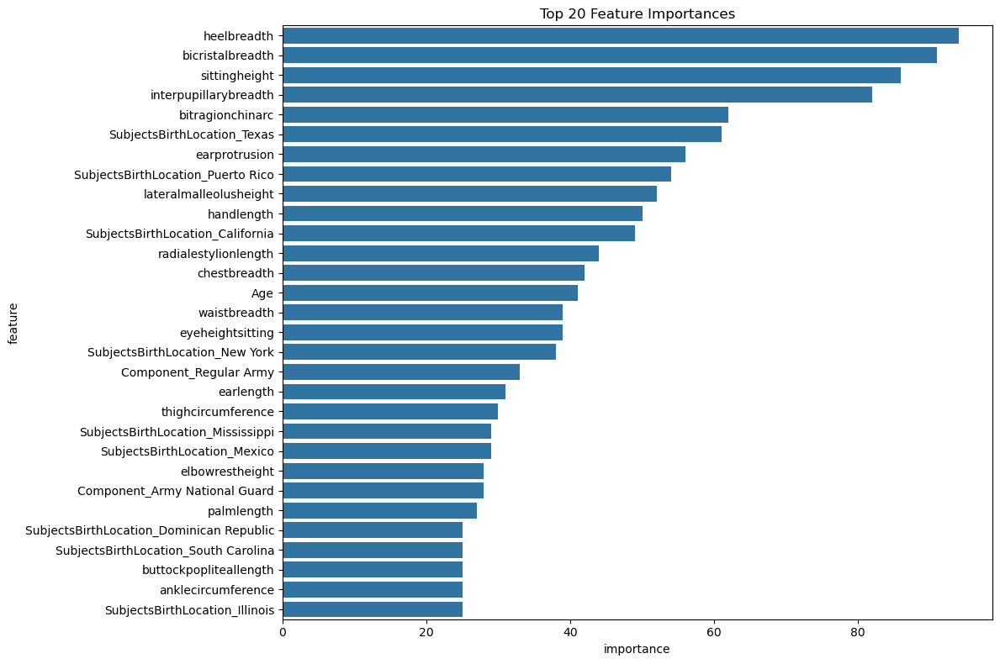

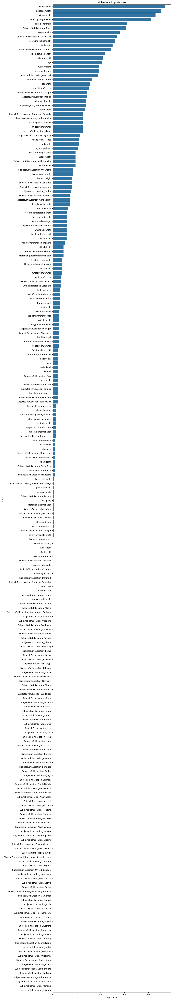

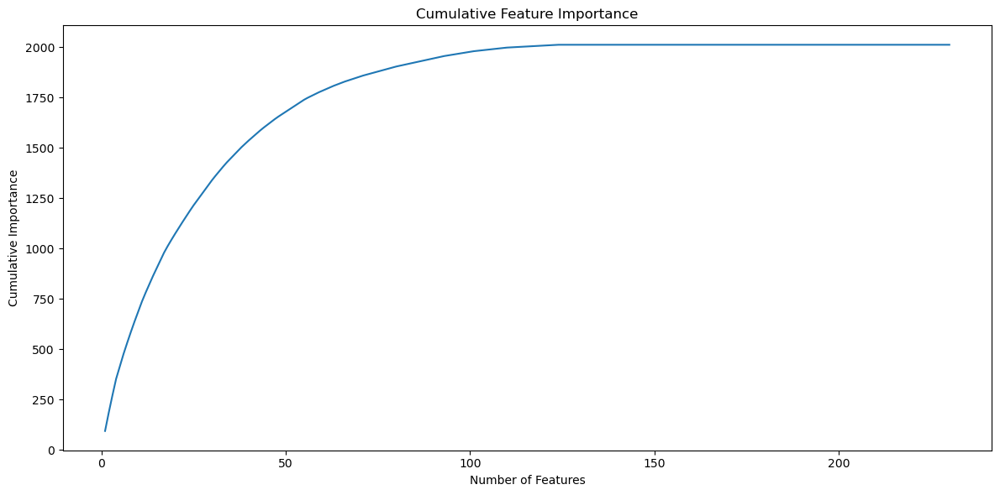

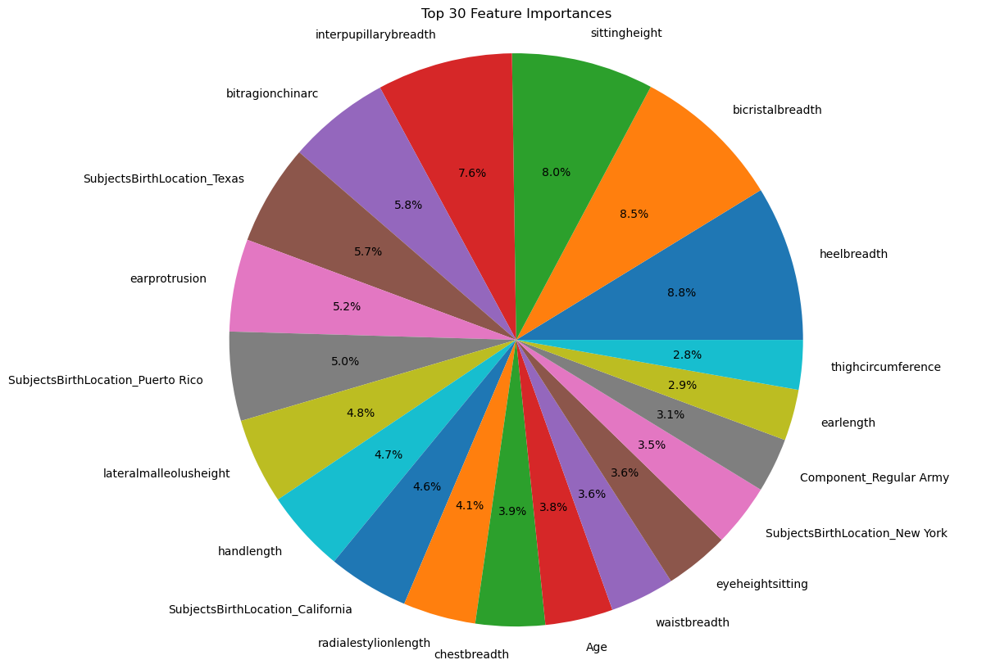

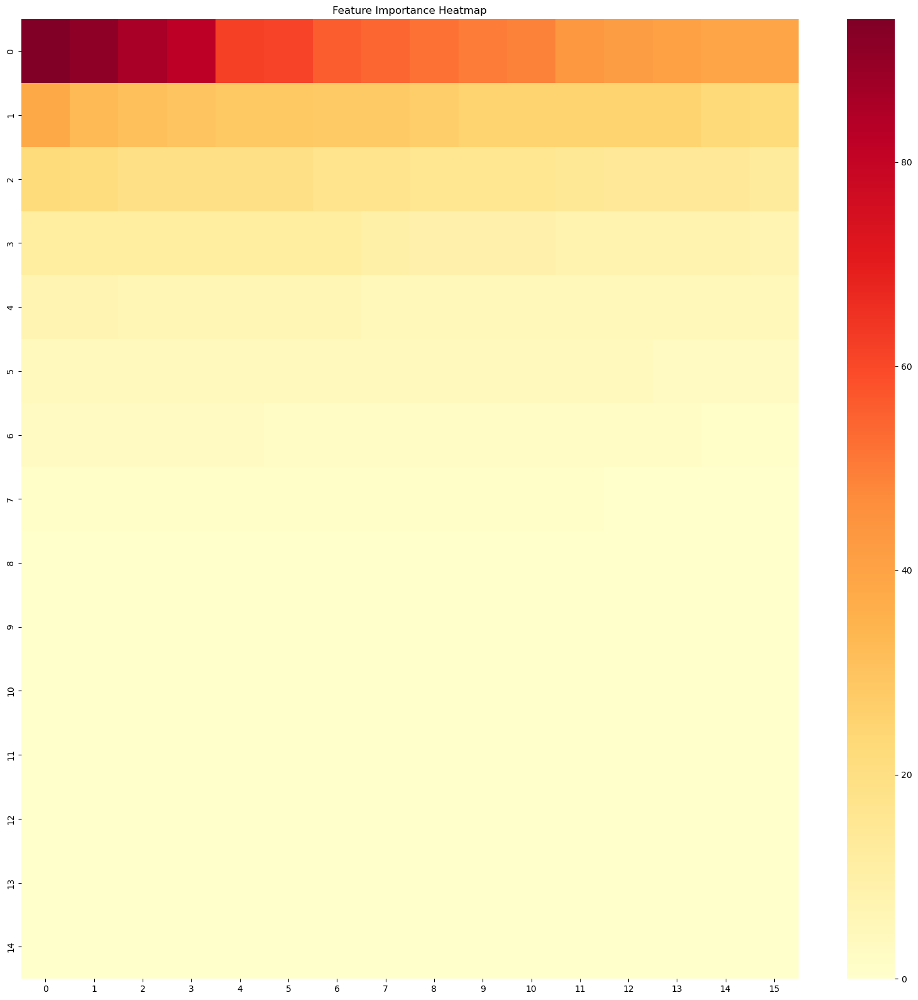


Feature Importance Summary:
count    230.000000
mean       8.752174
std       16.581264
min        0.000000
25%        0.000000
50%        1.000000
75%        9.000000
max       94.000000
Name: importance, dtype: float64

Top 20 Feature Importances:
                               feature  importance
48                         heelbreadth          94
9                     bicristalbreadth          91
70                       sittingheight          86
52               interpupillarybreadth          82
12                    bitragionchinarc          62
211        SubjectsBirthLocation_Texas          61
31                       earprotrusion          56
196  SubjectsBirthLocation_Puerto Rico          54
58              lateralmalleolusheight          52
43                          handlength          50
116   SubjectsBirthLocation_California          49
66                radialestylionlength          44
22                        chestbreadth          42
93                                 

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Sort features by importance
feature_imp = feature_imp.sort_values('importance', ascending=False)

# 1. Bar plot of top 20 features
plt.figure(figsize=(12, 8))
sns.barplot(x='importance', y='feature', data=feature_imp.head(30))
plt.title('Top 20 Feature Importances')
plt.tight_layout()
plt.show()

# 2. Horizontal bar plot of all features
plt.figure(figsize=(12, len(feature_imp) * 0.3))  # Adjust figure height based on number of features
sns.barplot(x='importance', y='feature', data=feature_imp)
plt.title('All Feature Importances')
plt.tight_layout()
plt.show()

# 3. Cumulative importance plot
cumulative_importance = np.cumsum(feature_imp['importance'])
plt.figure(figsize=(12, 6))
plt.plot(range(1, len(cumulative_importance) + 1), cumulative_importance)
plt.xlabel('Number of Features')
plt.ylabel('Cumulative Importance')
plt.title('Cumulative Feature Importance')
plt.tight_layout()
plt.show()

# 4. Pie chart of top 20 features
plt.figure(figsize=(15, 10))
plt.pie(feature_imp['importance'][:20], labels=feature_imp['feature'][:20], autopct='%1.1f%%')
plt.title('Top 30 Feature Importances')
plt.axis('equal')
plt.show()

# 5. Heatmap of feature importances
# Reshape the data into a square-like grid
n_features = len(feature_imp)
n_cols = int(np.ceil(np.sqrt(n_features)))
n_rows = int(np.ceil(n_features / n_cols))
importance_grid = np.zeros((n_rows, n_cols))
importance_grid.flat[:n_features] = feature_imp['importance']

plt.figure(figsize=(16, 16))
sns.heatmap(importance_grid, annot=False, cmap='YlOrRd')
plt.title('Feature Importance Heatmap')
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nFeature Importance Summary:")
print(feature_imp['importance'].describe())

print("\nTop 20 Feature Importances:")
print(feature_imp.head(20))

print("\nBottom 20 Feature Importances:")
print(feature_imp.tail(20))

# Calculate and print the number of features needed to reach 95% cumulative importance
cumulative_importance = np.cumsum(feature_imp['importance'])
n_features_95 = np.argmax(cumulative_importance >= 0.95) + 1
print(f"\nNumber of features needed to reach 95% cumulative importance: {n_features_95}")

### LightGBM Model_6

In [87]:
# Preprocessing
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Encode target variable after splitting
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

# Define the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

# Fit the preprocessor and transform the data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names after preprocessing
feature_names = (numeric_features.tolist() + 
                 preprocessor.named_transformers_['cat']
                 .get_feature_names_out(categorical_features).tolist())

# Train a simple model to get feature importances
initial_model = LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1, force_col_wise=True)
initial_model.fit(X_train_preprocessed, y_train)

# Get feature importances
importances = initial_model.feature_importances_
feature_imp = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Remove features with zero importance
non_zero_features = feature_imp[feature_imp['importance'] > 0]['feature'].tolist()
X_train_reduced = X_train_preprocessed[:, [feature_names.index(f) for f in non_zero_features]]
X_test_reduced = X_test_preprocessed[:, [feature_names.index(f) for f in non_zero_features]]

print(f"Original number of features: {len(feature_names)}")
print(f"Number of features after removing zero importance: {len(non_zero_features)}")

# Function to get enhanced SMOTE strategy with more emphasis on minority class
def get_enhanced_smote_strategy(y):
    class_counts = np.bincount(y)
    majority_class_count = np.max(class_counts)
    minority_class = np.argmin(class_counts)
    strategy = {i: majority_class_count for i in range(len(class_counts))}
    strategy[minority_class] = int(majority_class_count * 2)  # Oversample minority class even more
    return strategy

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    print("Train Set Metrics:")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))
    
    print("\nTest Set Metrics:")
    print(confusion_matrix(y_test, y_test_pred))
    print(classification_report(y_test, y_test_pred, target_names=le.classes_))

# Custom scorer focusing on Hispanic recall
def hispanic_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, average=None)[1]  # Assuming Hispanic is the second class (index 1)

hispanic_recall_scorer = make_scorer(hispanic_recall)

# Define the pipeline with SMOTE
operations = [
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train), random_state=42)),
    ("classifier", LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1, force_col_wise=True))
]

pipeline = ImbPipeline(steps=operations)

# Define parameter distribution for RandomizedSearchCV
param_dist = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.1, 0.3],
    'classifier__max_depth': [3, 5, 7],
    'classifier__num_leaves': [31, 63, 127],
    'classifier__min_child_samples': [20, 50, 100],
    'classifier__verbose': [-1],
    'classifier__force_col_wise': [True]
}

# Perform RandomizedSearchCV
random_search = RandomizedSearchCV(pipeline, param_distributions=param_dist, 
                                   n_iter=20, scoring=hispanic_recall_scorer, 
                                   n_jobs=-1, cv=5, random_state=42, verbose=2)
random_search.fit(X_train_reduced, y_train)

# Get the best model
best_model = random_search.best_estimator_

print("Best parameters found:")
print(random_search.best_params_)

# Evaluate the best model
print("\nBest Model Evaluation Metrics:")
eval_metric(best_model, X_train_reduced, y_train, X_test_reduced, y_test)

# Cross-validation of the best model
scores = cross_validate(best_model,
                        X_train_reduced,
                        y_train,
                        scoring={'accuracy': 'accuracy',
                                 'precision_macro': 'precision_macro',
                                 'recall_macro': 'recall_macro',
                                 'f1_macro': 'f1_macro',
                                 'roc_auc_ovr': 'roc_auc_ovr',
                                 'hispanic_recall': hispanic_recall_scorer},
                        cv=10)

df_scores = pd.DataFrame(scores)
mean_scores = df_scores.mean()
print("\nCross-validation Mean Scores for Best Model:")
print(mean_scores)

# Print original and SMOTE-adjusted class distribution
print("\nOriginal class distribution in training set:")
print(pd.Series(y_train).map(lambda x: le.inverse_transform([x])[0]).value_counts())

y_resampled = best_model.named_steps['smote'].fit_resample(X_train_reduced, y_train)[1]
print("\nSMOTE-adjusted class distribution:")
print(pd.Series(y_resampled).map(lambda x: le.inverse_transform([x])[0]).value_counts())

# Print feature importances
importances = best_model.named_steps['classifier'].feature_importances_
feature_imp = pd.DataFrame({'feature': non_zero_features, 'importance': importances})
feature_imp = feature_imp.sort_values('importance', ascending=False)
print("\nTop 10 Feature Importances:")
print(feature_imp.head(10))

Original number of features: 230
Number of features after removing zero importance: 137
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters found:
{'classifier__verbose': -1, 'classifier__num_leaves': 63, 'classifier__n_estimators': 100, 'classifier__min_child_samples': 20, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1, 'classifier__force_col_wise': True}

Best Model Evaluation Metrics:
Train Set Metrics:
[[ 949    7   82]
 [  28  303  212]
 [  51   71 2912]]
              precision    recall  f1-score   support

       Black       0.92      0.91      0.92      1038
    Hispanic       0.80      0.56      0.66       543
       White       0.91      0.96      0.93      3034

    accuracy                           0.90      4615
   macro avg       0.88      0.81      0.84      4615
weighted avg       0.90      0.90      0.90      4615


Test Set Metrics:
[[227   1  32]
 [  7  63  66]
 [ 29  28 701]]
              precision    recall  f1-score   sup

### Stacking (Logistic Regression and LightGBM --> Random Forest  (Base Model)

In [89]:
# Preprocessing
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=101, stratify=y_encoded)

# Define preprocessor (assuming you have categorical and numerical columns)
categorical_features = [col for col in X.columns if X[col].dtype == 'object']
numerical_features = [col for col in X.columns if X[col].dtype != 'object']

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Define function for feature engineering (replace with your actual function)
def create_interaction_features(X):
    # Add your feature engineering logic here
    return X

# Define function to get enhanced SMOTE strategy (replace with your actual function)
def get_enhanced_smote_strategy(y):
    # Add your SMOTE strategy logic here
    return 'auto'

# Define base models
model1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("log", LogisticRegression(class_weight='balanced', max_iter=10000, random_state=101, solver="liblinear", penalty="l1"))
])

model2 = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_engineering", FunctionTransformer(create_interaction_features)),
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train), random_state=42)),
    ("classifier", LGBMClassifier(random_state=42))
])

# Train base models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

# Make predictions on the training set
train_pred1 = model1.predict_proba(X_train)
train_pred2 = model2.predict_proba(X_train)

# Combine predictions for meta-model training
meta_features = np.column_stack((train_pred1, train_pred2))

# Define and train meta-model
meta_model = RandomForestClassifier(n_estimators=100, random_state=42)
meta_model.fit(meta_features, y_train)

# Make predictions on the test set
test_pred1 = model1.predict_proba(X_test)
test_pred2 = model2.predict_proba(X_test)
meta_features_test = np.column_stack((test_pred1, test_pred2))

# Final predictions
final_predictions = meta_model.predict(meta_features_test)

# Get the original class names
class_names = le.classes_.astype(str)

# Evaluate the stacked model
print(classification_report(y_test, final_predictions, target_names=class_names))

              precision    recall  f1-score   support

       Black       0.88      0.89      0.88       260
    Hispanic       0.70      0.52      0.60       136
       White       0.90      0.93      0.91       758

    accuracy                           0.87      1154
   macro avg       0.82      0.78      0.80      1154
weighted avg       0.87      0.87      0.87      1154



### Stacking LightGBM and Logistic Regression (no feature selection)

In [91]:
# DataFrame
X = df.drop(columns=['DODRace'])
y = df['DODRace']

# Encode target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=101, stratify=y_encoded)

# Preprocessing
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

# Define base models
model1 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model2 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(random_state=42))
])

# Function to get stacked predictions
def get_stacked_predictions(models, X, y, cv=5):
    stacked_predictions = np.column_stack([
        cross_val_predict(model, X, y, cv=cv, method='predict_proba')
        for model in models
    ])
    return stacked_predictions

# Train base models and get stacked predictions
base_models = [model1, model2]
stacked_predictions = get_stacked_predictions(base_models, X_train, y_train)

# Train meta-model
meta_model = RandomForestClassifier(n_estimators=100, random_state=42)
meta_model.fit(stacked_predictions, y_train)

# Make predictions on test set
test_predictions = np.column_stack([
    model.fit(X_train, y_train).predict_proba(X_test) for model in base_models
])
final_predictions = meta_model.predict(test_predictions)

# Evaluate the stacked model
print("Stacked Model Performance:")
print(classification_report(y_test, final_predictions, target_names=le.classes_))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

# Evaluate individual models
for i, model in enumerate(base_models, 1):
    print(f"\nModel {i} Performance:")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

# Print feature importances for Model 2 (LightGBM)
model2.fit(X_train, y_train)
feature_names = (numeric_features.tolist() + 
                 model2.named_steps['preprocessor']
                 .named_transformers_['cat']
                 .get_feature_names_out(categorical_features).tolist())
importances = model2.named_steps['classifier'].feature_importances_
feature_imp = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_imp = feature_imp.sort_values('importance', ascending=False)
print("\nTop 10 Feature Importances for Model 2 (LightGBM):")
print(feature_imp.head(10))

Stacked Model Performance:
              precision    recall  f1-score   support

       Black       0.92      0.93      0.92       260
    Hispanic       0.81      0.56      0.66       136
       White       0.91      0.96      0.93       758

    accuracy                           0.90      1154
   macro avg       0.88      0.81      0.84      1154
weighted avg       0.90      0.90      0.90      1154


Confusion Matrix:
[[241   2  17]
 [  5  76  55]
 [ 16  16 726]]

Model 1 Performance:
              precision    recall  f1-score   support

       Black       0.92      0.93      0.92       260
    Hispanic       0.81      0.64      0.72       136
       White       0.92      0.96      0.94       758

    accuracy                           0.91      1154
   macro avg       0.89      0.84      0.86      1154
weighted avg       0.91      0.91      0.91      1154

Confusion Matrix:
[[241   3  16]
 [  6  87  43]
 [ 15  17 726]]

Model 2 Performance:
              precision    recall  f1-

## Random Forest Analysis 

### Random Forest Model 1

In [94]:
# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat = X_train.select_dtypes("object").columns

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the pipeline operations
operations = [
    ("preprocessor", column_trans),
    ("classifier", RandomForestClassifier(random_state=42))
]

# Create and fit the pipeline
rf_model = Pipeline(steps=operations)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Test Set Results:")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))



Random Forest Test Set Results:
[[205   2  53]
 [ 11  18 107]
 [  9   5 744]]
              precision    recall  f1-score   support

       Black       0.91      0.79      0.85       260
    Hispanic       0.72      0.13      0.22       136
       White       0.82      0.98      0.90       758

    accuracy                           0.84      1154
   macro avg       0.82      0.63      0.65      1154
weighted avg       0.83      0.84      0.80      1154



### RF (Hyperparameters with Cross Validation) Model_2 

In [96]:
# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat = X_train.select_dtypes("object").columns

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the pipeline operations
operations = [
    ("preprocessor", column_trans),
    ("classifier", RandomForestClassifier(random_state=42))
]

# Create the pipeline
rf_model = Pipeline(steps=operations)

# Perform cross-validation
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='accuracy')
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())

# Define a parameter grid for GridSearchCV
param_grid = {
    'classifier__n_estimators': [32, 64, 100, 200, 300, 500, 1000],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10]
}

# Perform GridSearchCV
grid_search = GridSearchCV(rf_model, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Print the best parameters and score
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

# Use the best model to make predictions on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Evaluate the model
print("\nRandom Forest Test Set Results:")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Cross-validation scores: [0.82231853 0.8212351  0.81581798 0.83098592 0.8255688 ]
Mean CV score: 0.8231852654387865
Best parameters: {'classifier__max_depth': 30, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 64}
Best cross-validation score: 0.8231852654387867

Random Forest Test Set Results:
[[208   2  50]
 [ 13  16 107]
 [ 11   4 743]]
              precision    recall  f1-score   support

       Black       0.90      0.80      0.85       260
    Hispanic       0.73      0.12      0.20       136
       White       0.83      0.98      0.90       758

    accuracy                           0.84      1154
   macro avg       0.82      0.63      0.65      1154
weighted avg       0.83      0.84      0.80      1154



## XGBoost

### XGBoost Basic Model_1 

In [99]:
# Define X and y
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Encode the target variable
le = LabelEncoder()
y = le.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Evaluation Metric Function (You've already defined this)
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))


# Identify Categorical Features
cat = X_train.select_dtypes("object").columns

# Preprocessing with ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat) 
    ],
    remainder='passthrough' 
)

# XGBoost Model
xgb_model = xgb.XGBClassifier(
    objective='multi:softmax', 
    num_class=len(le.classes_), 
    class_weight='balanced',
    max_iter=10000,
    random_state=101
)

# Pipeline
pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

# Fit and Evaluate
pipe.fit(X_train, y_train)
eval_metric(pipe, X_train, y_train, X_test, y_test)

# Make Predictions
y_pred = pipe.predict(X_test)
y_pred_decoded = le.inverse_transform(y_pred)

import warnings
import io
import contextlib

# Capture warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")  # Always show warnings
    
    # Re-run your Random Forest code here
    # (Copy and paste the entire Random Forest code block here)
    
    # Print captured warnings
    if len(w) > 0:
        print("Captured warnings:")
        for warning in w:
            print(warning.message)

Test_Set
[[228   1  31]
 [  8  58  70]
 [ 18  10 730]]
              precision    recall  f1-score   support

       Black       0.90      0.88      0.89       260
    Hispanic       0.84      0.43      0.57       136
       White       0.88      0.96      0.92       758

    accuracy                           0.88      1154
   macro avg       0.87      0.76      0.79      1154
weighted avg       0.88      0.88      0.87      1154


Train_Set
[[1038    0    0]
 [   0  543    0]
 [   0    0 3034]]
              precision    recall  f1-score   support

       Black       1.00      1.00      1.00      1038
    Hispanic       1.00      1.00      1.00       543
       White       1.00      1.00      1.00      3034

    accuracy                           1.00      4615
   macro avg       1.00      1.00      1.00      4615
weighted avg       1.00      1.00      1.00      4615



## Support Vector Machine

### Support Vector Machine Basic Model_1

In [142]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)


def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(pd.Series(y_train).value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define the updated pipeline with SVM
operations = [
    ("OneHotEncoder", column_trans),
    ("svm", SVC(kernel='rbf', class_weight='balanced', random_state=42))
]

# Create and fit the pipeline
pipe = Pipeline(steps=operations)
pipe.fit(X_train, y_train_encoded)

# Evaluate the model
eval_metric(pipe, X_train, y_train_encoded, X_test, y_test_encoded)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = pipe.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(pipe, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Test_Set
[[236  14  10]
 [  6 105  25]
 [ 10 100 648]]
              precision    recall  f1-score   support

       Black       0.94      0.91      0.92       260
    Hispanic       0.48      0.77      0.59       136
       White       0.95      0.85      0.90       758

    accuracy                           0.86      1154
   macro avg       0.79      0.84      0.80      1154
weighted avg       0.89      0.86      0.87      1154


Train_Set
[[ 960   38   40]
 [  21  452   70]
 [  51  402 2581]]
              precision    recall  f1-score   support

       Black       0.93      0.92      0.93      1038
    Hispanic       0.51      0.83      0.63       543
       White       0.96      0.85      0.90      3034

    accuracy                           0.87      4615
   macro avg       0.80      0.87      0.82      4615
weighted avg       0.90      0.87      0.8

### SVM Model_2 

In [144]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    stratify=y, random_state=42)

# Encode target variable
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Define evaluation metric function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test_Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train_Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Print original class distribution
print("Original class distribution in training set:")
print(pd.Series(y_train).value_counts())

# Identify categorical and numerical columns
categorical_columns = X_train.select_dtypes(include=['object', 'category']).columns
numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns

# Create column transformer with OneHotEncoder for categorical variables and MinMaxScaler for numerical variables
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_columns),
    (MinMaxScaler(), numerical_columns),
)

# Define the pipeline with SVM
operations = [
    ("preprocessor", column_trans),
    ("svm", SVC(kernel='rbf', random_state=42))
]

# Create the pipeline
pipe = Pipeline(steps=operations)

# Define the parameter grid
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': [0.01, 0.1, 1, 'scale', 'auto'],
    'svm__class_weight': ['balanced', None]
}

# Create the grid search object
grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring=minority_class_scorer, n_jobs=-1)

# Fit the grid search
grid_search.fit(X_train, y_train_encoded)

# Print the best parameters and score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Use the best estimator for prediction
best_model = grid_search.best_estimator_

# Evaluate the best model
eval_metric(best_model, X_train, y_train_encoded, X_test, y_test_encoded)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = best_model.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(best_model, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Best parameters: {'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.01}
Best score: 0.6399335324174034
Test_Set
[[236   6  18]
 [  6  72  58]
 [  7  14 737]]
              precision    recall  f1-score   support

       Black       0.95      0.91      0.93       260
    Hispanic       0.78      0.53      0.63       136
       White       0.91      0.97      0.94       758

    accuracy                           0.91      1154
   macro avg       0.88      0.80      0.83      1154
weighted avg       0.90      0.91      0.90      1154


Train_Set
[[ 984    9   45]
 [  27  332  184]
 [  15   23 2996]]
              precision    recall  f1-score   support

       Black       0.96      0.95      0.95      1038
    Hispanic       0.91      0.61      0.73       543
       White       0.93      0.99      0.96      3034

    accuracy                           

### SVM (Class Weight) Model_3

In [146]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=101)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(pd.Series(y_train).value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define class weights
class_weights = {
    0: 1.2,  # Black
    1: 2.5,  # Hispanic
    2: 1     # White
}

# Define the updated pipeline with SVM
operations = [
    ("OneHotEncoder", column_trans),
    ("svm", SVC(kernel='rbf', class_weight=class_weights, random_state=42, max_iter=10000))
]

# Create and fit the pipeline
pipe = Pipeline(steps=operations)
pipe.fit(X_train, y_train_encoded)

# Evaluate the model
eval_metric(pipe, X_train, y_train_encoded, X_test, y_test_encoded)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = pipe.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(pipe, X_test, y_test_encoded))

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Test Set
[[227   7  26]
 [  3  92  41]
 [  8  35 715]]
              precision    recall  f1-score   support

       Black       0.95      0.87      0.91       260
    Hispanic       0.69      0.68      0.68       136
       White       0.91      0.94      0.93       758

    accuracy                           0.90      1154
   macro avg       0.85      0.83      0.84      1154
weighted avg       0.90      0.90      0.90      1154


Train Set
[[ 921   25   92]
 [  18  370  155]
 [  16  115 2903]]
              precision    recall  f1-score   support

       Black       0.96      0.89      0.92      1038
    Hispanic       0.73      0.68      0.70       543
       White       0.92      0.96      0.94      3034

    accuracy                           0.91      4615
   macro avg       0.87      0.84      0.86      4615
weighted avg       0.91      0.91      0.9

### SVM Model (Class Weight and SMOTE) Model_4

In [148]:
# Prepare the data
X = df.drop(columns=["DODRace"])  # Features
y = df["DODRace"]  # Target variable

# Split the data before encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=101)

# Encode target variable after splitting
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print()
    print("Train Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Print original class distribution
print("Original class distribution in training set:")
print(pd.Series(y_train).value_counts())

# Get categorical columns
cat = X_train.select_dtypes("object").columns

# Create column transformer with OneHotEncoder and MinMaxScaler
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Function to get enhanced SMOTE strategy with more emphasis on minority class
def get_enhanced_smote_strategy(y):
    class_counts = np.bincount(y)
    majority_class_count = np.max(class_counts)
    minority_class = np.argmin(class_counts)
    strategy = {i: majority_class_count for i in range(len(class_counts))}
    strategy[minority_class] = int(majority_class_count * 1.2)  # Oversample minority class even more
    return strategy

# Define class weights
class_weights = {
    0: 1,  # Black
    1: 2.2,  # Hispanic
    2: 1     # White
}

# Define the updated pipeline with SVM and SMOTE
operations = [
    ("OneHotEncoder", column_trans),
    ("smote", SMOTE(sampling_strategy=get_enhanced_smote_strategy(y_train_encoded), random_state=42)),
    ("svm", SVC(kernel='rbf', class_weight=class_weights, random_state=42, max_iter=10000))
]

# Create and fit the pipeline
pipe = ImbPipeline(steps=operations)
pipe.fit(X_train, y_train_encoded)

# Evaluate the model
eval_metric(pipe, X_train, y_train_encoded, X_test, y_test_encoded)

# Custom scorer focusing on minority class
def minority_class_f1_score(y_true, y_pred):
    minority_class = np.argmin(np.bincount(y_true))
    return f1_score(y_true, y_pred, labels=[minority_class], average='micro')

minority_class_scorer = make_scorer(minority_class_f1_score)

# Print model performance metrics
print("\nModel performance metrics:")
y_pred = pipe.predict(X_test)
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Use the custom scorer for evaluation
print("\nMinority Class F1 Score:", minority_class_scorer(pipe, X_test, y_test_encoded))

# Print resampled class distribution
print("\nResampled class distribution:")
X_resampled, y_resampled = pipe.named_steps['smote'].fit_resample(pipe.named_steps['OneHotEncoder'].transform(X_train), y_train_encoded)
print(pd.Series(y_resampled).value_counts())

Original class distribution in training set:
DODRace
White       3034
Black       1038
Hispanic     543
Name: count, dtype: int64
Test Set
[[231  19  10]
 [  4 116  16]
 [ 21 148 589]]
              precision    recall  f1-score   support

       Black       0.90      0.89      0.90       260
    Hispanic       0.41      0.85      0.55       136
       White       0.96      0.78      0.86       758

    accuracy                           0.81      1154
   macro avg       0.76      0.84      0.77      1154
weighted avg       0.88      0.81      0.83      1154


Train Set
[[ 951   53   34]
 [   9  508   26]
 [  33  609 2392]]
              precision    recall  f1-score   support

       Black       0.96      0.92      0.94      1038
    Hispanic       0.43      0.94      0.59       543
       White       0.98      0.79      0.87      3034

    accuracy                           0.83      4615
   macro avg       0.79      0.88      0.80      4615
weighted avg       0.91      0.83      0.8

## ANN 

### ANN Model_1 

Epoch 1/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6729 - loss: 1.2373 - val_accuracy: 0.7985 - val_loss: 0.6323
Epoch 2/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8238 - loss: 0.8366 - val_accuracy: 0.8310 - val_loss: 0.4779
Epoch 3/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 525us/step - accuracy: 0.8589 - loss: 0.6263 - val_accuracy: 0.8624 - val_loss: 0.3783
Epoch 4/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 538us/step - accuracy: 0.8587 - loss: 0.5479 - val_accuracy: 0.8559 - val_loss: 0.3893
Epoch 5/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 529us/step - accuracy: 0.8543 - loss: 0.5382 - val_accuracy: 0.8819 - val_loss: 0.3594
Epoch 6/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 510us/step - accuracy: 0.8737 - loss: 0.4817 - val_accuracy: 0.8830 - val_loss: 0.3383
Epoch 7/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 552us/step - accuracy: 0.8685 - loss: 0.4823 - val_accuracy: 0.8505 - val_loss: 0.4310
Epoch 8/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 755us/step - accuracy: 0.8614 - loss: 0.487

<Figure size 2000x500 with 0 Axes>

<Figure size 2000x500 with 0 Axes>

<Figure size 2000x500 with 0 Axes>

<Figure size 1600x3200 with 0 Axes>

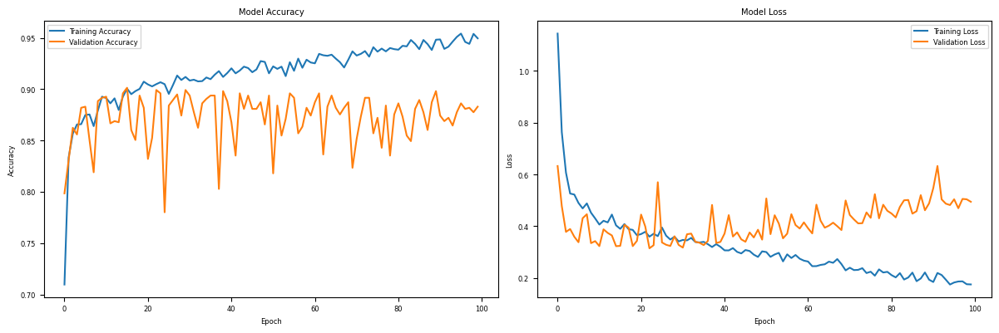

In [506]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat = X_train.select_dtypes("object").columns

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Fit and transform the data
X_train_processed = column_trans.fit_transform(X_train)
X_test_processed = column_trans.transform(X_test)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_train_numeric = y_train.map(label_mapping)
y_test_numeric = y_test.map(label_mapping)

# Convert to one-hot encoded format
y_train_categorical = to_categorical(y_train_numeric)
y_test_categorical = to_categorical(y_test_numeric)

# Define the ANN model
def create_ann_model(input_dim):
    model = Sequential([
        Dense(64, activation='relu', input_shape=(input_dim,)),
        Dense(32, activation='relu'),
        Dense(16, activation='relu'),
        Dense(3, activation='softmax')  # 3 output classes
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Create and compile the model
model = create_ann_model(X_train_processed.shape[1])

# Define class weights
class_weights = {
    0: 1.5,  # Black
    1: 2.2,  # Hispanic
    2: 1     # White
}

# Fit the model
history = model.fit(
    X_train_processed, y_train_categorical,
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    validation_split=0.2,
    verbose=1
)

# Make predictions
y_pred_proba = model.predict(X_test_processed)
y_pred_numeric = np.argmax(y_pred_proba, axis=1)

# Convert numeric predictions back to string labels
reverse_label_mapping = {v: k for k, v in label_mapping.items()}
y_pred_labels = [reverse_label_mapping[pred] for pred in y_pred_numeric]

# Evaluate the model
print("Test Set Results:")
print(confusion_matrix(y_test, y_pred_labels))
print(classification_report(y_test, y_pred_labels))

# Plot training history
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### ANN_Model_2

Epoch 1/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4595 - loss: 14.1733 - val_accuracy: 0.0000e+00 - val_loss: 25.9751
Epoch 2/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5900 - loss: 12.0682 - val_accuracy: 0.1060 - val_loss: 17.7789
Epoch 3/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7131 - loss: 8.8638 - val_accuracy: 0.5003 - val_loss: 12.3623
Epoch 4/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7759 - loss: 6.6954 - val_accuracy: 0.5843 - val_loss: 12.3879
Epoch 5/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8012 - loss: 5.8883 - val_accuracy: 0.6326 - val_loss: 9.7190
Epoch 6/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8263 - loss: 5.3790 - val_accuracy: 0.6831 - val_loss: 8.1091
Epoch 7/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8443 - loss: 4.6002 - val_accuracy: 0.7276 - val_loss: 7.8671
Epoch 8/150
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8519 - loss: 4.3167 - val_accuracy: 

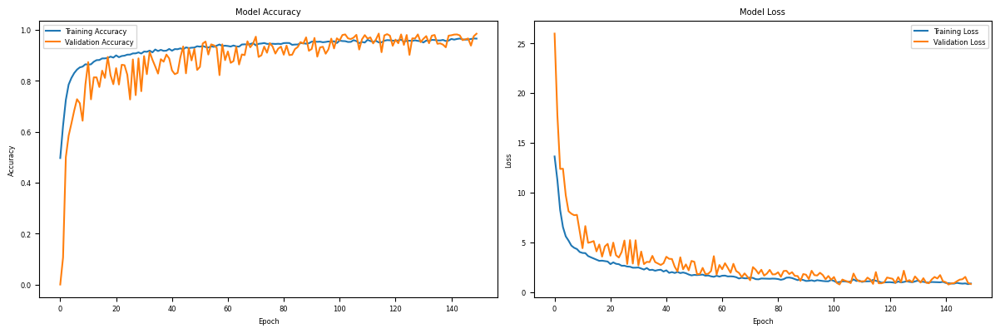

In [531]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from imblearn.over_sampling import SMOTE
import tensorflow as tf

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat = X_train.select_dtypes("object").columns

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Fit and transform the data
X_train_processed = column_trans.fit_transform(X_train)
X_test_processed = column_trans.transform(X_test)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_train_numeric = y_train.map(label_mapping)
y_test_numeric = y_test.map(label_mapping)

# Apply SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train_numeric)

# Convert to one-hot encoded format
y_train_categorical = to_categorical(y_train_resampled)
y_test_categorical = to_categorical(y_test_numeric)

# Define focal loss
def focal_loss(gamma=2., alpha=.25):
    def focal_loss_fixed(y_true, y_pred):
        pt_1 = tf.where(tf.equal(y_true, 1), y_pred, tf.ones_like(y_pred))
        return -tf.reduce_sum(alpha * tf.pow(1. - pt_1, gamma) * tf.math.log(pt_1))
    return focal_loss_fixed

# Define the ANN model
def create_ann_model(input_dim):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')  # 3 output classes
    ])
    model.compile(optimizer=Adam(learning_rate=0.0005), loss=focal_loss(alpha=.25, gamma=2), metrics=['accuracy'])
    return model

# Create and compile the model
model = create_ann_model(X_train_resampled.shape[1])

# Define class weights (can be adjusted if needed after SMOTE)
class_weights = {
    0: 1.0,  # Black
    1: 1.0,  # Hispanic
    2: 1.0   # White
}

# Fit the model
history = model.fit(
    X_train_resampled, y_train_categorical,
    epochs=150,
    batch_size=128,
    class_weight=class_weights,
    validation_split=0.2,
    verbose=1
)

# Make predictions
y_pred_proba = model.predict(X_test_processed)
y_pred_numeric = np.argmax(y_pred_proba, axis=1)

# Convert numeric predictions back to string labels
reverse_label_mapping = {v: k for k, v in label_mapping.items()}
y_pred_labels = [reverse_label_mapping[pred] for pred in y_pred_numeric]

# Evaluate the model
print("Test Set Results:")
print(confusion_matrix(y_test, y_pred_labels))
print(classification_report(y_test, y_pred_labels))

# Plot training history
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### ANN Model_3 

Epoch 1/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3617 - loss: 18.5168 - val_accuracy: 0.6359 - val_loss: 6.7408
Epoch 2/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4890 - loss: 13.2684 - val_accuracy: 0.6722 - val_loss: 6.3655
Epoch 3/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5691 - loss: 11.1370 - val_accuracy: 0.7820 - val_loss: 5.6858
Epoch 4/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6104 - loss: 9.6817 - val_accuracy: 0.7551 - val_loss: 5.9820
Epoch 5/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6560 - loss: 8.8883 - val_accuracy: 0.7551 - val_loss: 5.9135
Epoch 6/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6956 - loss: 8.2746 - val_accuracy: 0.7776 - val_loss: 5.4807
Epoch 7/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7055 - loss: 7.9394 - val_accuracy: 0.7919 - val_loss: 5.4335
Epoch 8/200
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7269 - loss: 7.5925 - val_a

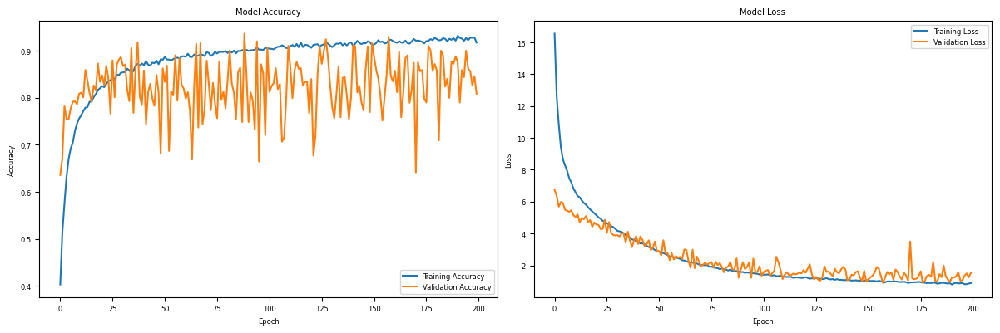

In [545]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from imblearn.over_sampling import SMOTENC
import tensorflow as tf

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat_columns = X_train.select_dtypes("object").columns
cat_indices = [X.columns.get_loc(col) for col in cat_columns]

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_columns),
    remainder=MinMaxScaler()
)

# Fit and transform the data
X_train_processed = column_trans.fit_transform(X_train)
X_test_processed = column_trans.transform(X_test)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_train_numeric = y_train.map(label_mapping)
y_test_numeric = y_test.map(label_mapping)

# Apply SMOTENC (SMOTE for Nominal/Continuous features)
smote = SMOTENC(random_state=42, categorical_features=cat_indices)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train_numeric)

# Apply the column transformer to the resampled data
X_train_resampled_processed = column_trans.transform(X_train_resampled)

# Convert to one-hot encoded format
y_train_categorical = to_categorical(y_train_resampled)
y_test_categorical = to_categorical(y_test_numeric)

# Define focal loss
def focal_loss(gamma=2., alpha=.25):
    def focal_loss_fixed(y_true, y_pred):
        pt_1 = tf.where(tf.equal(y_true, 1), y_pred, tf.ones_like(y_pred))
        return -tf.reduce_sum(alpha * tf.pow(1. - pt_1, gamma) * tf.math.log(pt_1))
    return focal_loss_fixed

# Define the ANN model
def create_ann_model(input_dim):
    model = Sequential([
        Dense(256, activation='relu', input_shape=(input_dim,), kernel_regularizer=l2(0.01)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(3, activation='softmax')  # 3 output classes
    ])
    model.compile(optimizer=Adam(learning_rate=0.0001), loss=focal_loss(alpha=.25, gamma=2), metrics=['accuracy'])
    return model

# Create and compile the model
model = create_ann_model(X_train_resampled_processed.shape[1])

# Define class weights
class_weights = {
    0: 1.0,  # Black
    1: 2.0,  # Hispanic (increased weight)
    2: 1.0   # White
}

# Fit the model
history = model.fit(
    X_train_resampled_processed, y_train_categorical,
    epochs=200,
    batch_size=32,
    class_weight=class_weights,
    validation_split=0.2,
    verbose=1
)

# Make predictions
y_pred_proba = model.predict(X_test_processed)
y_pred_numeric = np.argmax(y_pred_proba, axis=1)

# Convert numeric predictions back to string labels
reverse_label_mapping = {v: k for k, v in label_mapping.items()}
y_pred_labels = [reverse_label_mapping[pred] for pred in y_pred_numeric]

# Evaluate the model
print("Test Set Results:")
print(confusion_matrix(y_test, y_pred_labels))
print(classification_report(y_test, y_pred_labels))

# Plot training history
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### ANN Model_4

Epoch 1/1000
228/228 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3862 - hispanic_f1_score: 0.2445 - loss: 6.6989 - val_accuracy: 0.6447 - val_hispanic_f1_score: 0.7805 - val_loss: 5.3214
Epoch 2/1000
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5269 - hispanic_f1_score: 0.3403 - loss: 5.6817 - val_accuracy: 0.7803 - val_hispanic_f1_score: 0.8749 - val_loss: 4.6635
Epoch 3/1000
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5981 - hispanic_f1_score: 0.3942 - loss: 5.1594 - val_accuracy: 0.8012 - val_hispanic_f1_score: 0.8884 - val_loss: 4.3058
Epoch 4/1000
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6517 - hispanic_f1_score: 0.4412 - loss: 4.7741 - val_accuracy: 0.7891 - val_hispanic_f1_score: 0.8809 - val_loss: 4.1180
Epoch 5/1000
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6907 - hispanic_f1_score: 0.4795 - loss: 4.4449 - val_accuracy: 0.7825 - val_hispanic_f1_score: 0.8770 - val_loss: 3.9694
Epoch 6/1000
228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/s

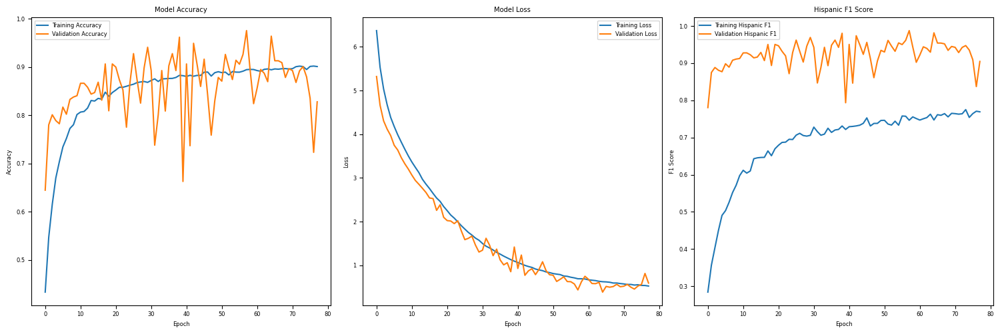

In [554]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTENC
import tensorflow as tf
import tensorflow.keras.backend as K

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101, stratify=y)

# Identify categorical columns
cat_columns = X_train.select_dtypes("object").columns
cat_indices = [X.columns.get_loc(col) for col in cat_columns]

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_columns),
    remainder=MinMaxScaler()
)

# Fit and transform the data
X_train_processed = column_trans.fit_transform(X_train)
X_test_processed = column_trans.transform(X_test)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_train_numeric = y_train.map(label_mapping)
y_test_numeric = y_test.map(label_mapping)

# Apply SMOTENC (SMOTE for Nominal/Continuous features)
smote = SMOTENC(random_state=42, categorical_features=cat_indices)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train_numeric)

# Apply the column transformer to the resampled data
X_train_resampled_processed = column_trans.transform(X_train_resampled)

# Convert to one-hot encoded format
y_train_categorical = to_categorical(y_train_resampled)
y_test_categorical = to_categorical(y_test_numeric)

# Define custom F1 score metric for Hispanic class
def hispanic_f1_score(y_true, y_pred):
    # Convert one-hot encoded y_true and y_pred to class indices
    y_true = K.argmax(y_true, axis=-1)
    y_pred = K.argmax(y_pred, axis=-1)
    
    # Calculate True Positives, False Positives, and False Negatives for Hispanic class (index 1)
    true_positives = K.sum(K.cast(K.equal(y_true, 1) & K.equal(y_pred, 1), 'float32'))
    false_positives = K.sum(K.cast(K.not_equal(y_true, 1) & K.equal(y_pred, 1), 'float32'))
    false_negatives = K.sum(K.cast(K.equal(y_true, 1) & K.not_equal(y_pred, 1), 'float32'))
    
    # Calculate precision and recall
    precision = true_positives / (true_positives + false_positives + K.epsilon())
    recall = true_positives / (true_positives + false_negatives + K.epsilon())
    
    # Calculate F1 score
    f1_score = 2 * precision * recall / (precision + recall + K.epsilon())
    
    return f1_score

# Define the ANN model
def create_ann_model(input_dim):
    model = Sequential([
        Dense(256, activation='relu', input_shape=(input_dim,), kernel_regularizer=l2(0.01)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(3, activation='softmax')  # 3 output classes
    ])
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy', hispanic_f1_score])
    return model

# Create and compile the model
model = create_ann_model(X_train_resampled_processed.shape[1])

# Define class weights
class_weights = {
    0: 1.0,  # Black
    1: 2.0,  # Hispanic (increased weight)
    2: 1.0   # White
}

# Define early stopping
early_stopping = EarlyStopping(monitor='val_hispanic_f1_score', mode='max', patience=20, restore_best_weights=True)

# Fit the model
history = model.fit(
    X_train_resampled_processed, y_train_categorical,
    epochs=1000,
    batch_size=32,
    class_weight=class_weights,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

# Make predictions
y_pred_proba = model.predict(X_test_processed)
y_pred_numeric = np.argmax(y_pred_proba, axis=1)

# Convert numeric predictions back to string labels
reverse_label_mapping = {v: k for k, v in label_mapping.items()}
y_pred_labels = [reverse_label_mapping[pred] for pred in y_pred_numeric]

# Evaluate the model
print("Test Set Results:")
print(confusion_matrix(y_test, y_pred_labels))
print(classification_report(y_test, y_pred_labels))

# Plot training history
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history.history['hispanic_f1_score'], label='Training Hispanic F1')
plt.plot(history.history['val_hispanic_f1_score'], label='Validation Hispanic F1')
plt.title('Hispanic F1 Score')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()

plt.tight_layout()
plt.show()

### ANN Model_6

In [577]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTENC
import tensorflow as tf
import tensorflow.keras.backend as K

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Identify categorical columns
cat_columns = X.select_dtypes("object").columns
cat_indices = [X.columns.get_loc(col) for col in cat_columns]

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_columns),
    remainder=MinMaxScaler()
)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_numeric = y.map(label_mapping)

# Define custom F1 score metric for Hispanic class
def hispanic_f1_score(y_true, y_pred):
    y_true = K.argmax(y_true, axis=-1)
    y_pred = K.argmax(y_pred, axis=-1)
    
    true_positives = K.sum(K.cast(K.equal(y_true, 1) & K.equal(y_pred, 1), 'float32'))
    false_positives = K.sum(K.cast(K.not_equal(y_true, 1) & K.equal(y_pred, 1), 'float32'))
    false_negatives = K.sum(K.cast(K.equal(y_true, 1) & K.not_equal(y_pred, 1), 'float32'))
    
    precision = true_positives / (true_positives + false_positives + K.epsilon())
    recall = true_positives / (true_positives + false_negatives + K.epsilon())
    
    f1_score = 2 * precision * recall / (precision + recall + K.epsilon())
    
    return f1_score

# Define the ANN model
def create_ann_model(input_dim):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_dim,), kernel_regularizer=l2(0.02)),
        BatchNormalization(),
        Dropout(0.5),
        Dense(64, activation='relu', kernel_regularizer=l2(0.02)),
        BatchNormalization(),
        Dropout(0.5),
        Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
        BatchNormalization(),
        Dropout(0.5),
        Dense(3, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy', hispanic_f1_score])
    return model

# Stratified K-Fold cross-validation
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Lists to store results
test_accuracies = []
test_hispanic_f1_scores = []

for fold, (train_index, test_index) in enumerate(skf.split(X, y_numeric), 1):
    print(f"Fold {fold}")
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y_numeric.iloc[train_index], y_numeric.iloc[test_index]
    
    # Apply SMOTENC with a lower sampling strategy
    smote = SMOTENC(sampling_strategy={1: 1000}, random_state=42, categorical_features=cat_indices)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
    
    # Apply the column transformer
    X_train_processed = column_trans.fit_transform(X_train_resampled)
    X_test_processed = column_trans.transform(X_test)
    
    # Convert to one-hot encoded format
    y_train_categorical = to_categorical(y_train_resampled)
    y_test_categorical = to_categorical(y_test)
    
    # Create and compile the model
    model = create_ann_model(X_train_processed.shape[1])
    
    # Define class weights
    class_weights = {0: 1.0, 1: 1.5, 2: 0.5}  # Adjusted weights
    
    # Define early stopping
    early_stopping = EarlyStopping(monitor='val_hispanic_f1_score', mode='max', patience=20, restore_best_weights=True)
    
    # Fit the model
    history = model.fit(
        X_train_processed, y_train_categorical,
        epochs=200,
        batch_size=32,
        class_weight=class_weights,
        validation_split=0.2,
        callbacks=[early_stopping],
        verbose=0
    )
    
    # Evaluate the model
    test_loss, test_accuracy, test_hispanic_f1 = model.evaluate(X_test_processed, y_test_categorical, verbose=0)
    test_accuracies.append(test_accuracy)
    test_hispanic_f1_scores.append(test_hispanic_f1)
    
    # Make predictions
    y_pred_proba = model.predict(X_test_processed)
    y_pred_numeric = np.argmax(y_pred_proba, axis=1)
    
    # Convert numeric predictions back to string labels
    reverse_label_mapping = {v: k for k, v in label_mapping.items()}
    y_pred_labels = [reverse_label_mapping[pred] for pred in y_pred_numeric]
    y_test_labels = [reverse_label_mapping[true] for true in y_test]
    
    print(f"Fold {fold} Results:")
    print(confusion_matrix(y_test_labels, y_pred_labels))
    print(classification_report(y_test_labels, y_pred_labels))
    print("\n")

# Print average results
print("Average Test Accuracy:", np.mean(test_accuracies))
print("Average Test Hispanic F1-score:", np.mean(test_hispanic_f1_scores))

Fold 1
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Fold 1 Results:
[[209  27  23]
 [  4 107  25]
 [  2  86 671]]
              precision    recall  f1-score   support

       Black       0.97      0.81      0.88       259
    Hispanic       0.49      0.79      0.60       136
       White       0.93      0.88      0.91       759

    accuracy                           0.86      1154
   macro avg       0.80      0.83      0.80      1154
weighted avg       0.89      0.86      0.87      1154



Fold 2
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Fold 2 Results:
[[236  15   8]
 [  6 110  20]
 [ 20 111 628]]
              precision    recall  f1-score   support

       Black       0.90      0.91      0.91       259
    Hispanic       0.47      0.81      0.59       136
       White       0.96      0.83      0.89       759

    accuracy                           0.84      1154
   macro avg       0.77      0.85      0.79      1154
weighted avg       0.89      0.84      0.86      1154



Fold 3
37/37 ━━━

### ANN Model_7 (Best in Final Model)

In [584]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTENC
import tensorflow as tf
import optuna

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Identify categorical columns
cat_columns = X.select_dtypes("object").columns
cat_indices = [X.columns.get_loc(col) for col in cat_columns]

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_columns),
    remainder=MinMaxScaler()
)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_numeric = y.map(label_mapping)

# Preprocess the entire dataset
X_processed = column_trans.fit_transform(X)
y_categorical = to_categorical(y_numeric)

# Define the model creation function
def create_model(trial):
    n_layers = trial.suggest_int('n_layers', 1, 5)
    activation = trial.suggest_categorical('activation', ['relu', 'elu', 'selu', 'tanh'])
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'SGD', 'RMSprop'])
    learning_rate = trial.suggest_loguniform('learning_rate', 1e-5, 1e-2)
    dropout_rate = trial.suggest_uniform('dropout_rate', 0.1, 0.5)
    l2_lambda = trial.suggest_loguniform('l2_lambda', 1e-5, 1e-2)

    model = Sequential()
    for i in range(n_layers):
        n_units = trial.suggest_int(f'n_units_l{i}', 32, 256)
        model.add(Dense(n_units, activation=activation, kernel_regularizer=l2(l2_lambda)))
        model.add(BatchNormalization())
        model.add(Dropout(dropout_rate))
    model.add(Dense(3, activation='softmax'))

    if optimizer_name == 'Adam':
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name == 'SGD':
        optimizer = SGD(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Define the objective function for Optuna
def objective(trial):
    model = create_model(trial)
    
    # Use StratifiedKFold for cross-validation
    n_splits = 5
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    hispanic_f1_scores = []
    
    for train_index, val_index in skf.split(X_processed, y_numeric):
        X_train, X_val = X_processed[train_index], X_processed[val_index]
        y_train, y_val = y_categorical[train_index], y_categorical[val_index]
        
        # Apply SMOTENC
        smote = SMOTENC(sampling_strategy={1: 1000}, random_state=42, categorical_features=cat_indices)
        X_train_resampled, y_train_resampled = smote.fit_resample(X_train, np.argmax(y_train, axis=1))
        y_train_resampled = to_categorical(y_train_resampled)
        
        # Define early stopping
        early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        
        # Fit the model
        model.fit(
            X_train_resampled, y_train_resampled,
            epochs=100,
            batch_size=trial.suggest_categorical('batch_size', [16, 32, 64, 128]),
            validation_data=(X_val, y_val),
            callbacks=[early_stopping],
            verbose=0
        )
        
        # Evaluate the model
        y_pred = model.predict(X_val)
        y_pred_classes = np.argmax(y_pred, axis=1)
        y_true_classes = np.argmax(y_val, axis=1)
        
        hispanic_f1 = f1_score(y_true_classes, y_pred_classes, average=None)[1]  # F1 score for Hispanic class
        hispanic_f1_scores.append(hispanic_f1)
    
    return np.mean(hispanic_f1_scores)

# Run the optimization
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print('Number of finished trials:', len(study.trials))
print('Best trial:')
trial = study.best_trial

print('Value:', trial.value)
print('Params:')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

# Train the final model with the best hyperparameters
best_model = create_model(trial)
best_model.fit(X_processed, y_categorical, epochs=100, batch_size=trial.params['batch_size'], verbose=0)

# Make predictions
y_pred = best_model.predict(X_processed)
y_pred_classes = np.argmax(y_pred, axis=1)

# Convert numeric predictions back to string labels
reverse_label_mapping = {v: k for k, v in label_mapping.items()}
y_pred_labels = [reverse_label_mapping[pred] for pred in y_pred_classes]
y_true_labels = [reverse_label_mapping[true] for true in y_numeric]

print("\nFinal Model Results:")
print(confusion_matrix(y_true_labels, y_pred_labels))
print(classification_report(y_true_labels, y_pred_labels))

[I 2024-09-11 12:48:28,664] A new study created in memory with name: no-name-7f12229e-55a3-43b7-ba2c-08e090d1a734


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 538us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step


[I 2024-09-11 12:49:16,141] Trial 0 finished with value: 0.7302714055076857 and parameters: {'n_layers': 3, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 3.5163363802215866e-05, 'dropout_rate': 0.20089455973613496, 'l2_lambda': 0.004259528143924106, 'n_units_l0': 236, 'n_units_l1': 212, 'n_units_l2': 188, 'batch_size': 128}. Best is trial 0 with value: 0.7302714055076857.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 451us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 425us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step


[I 2024-09-11 12:49:30,432] Trial 1 finished with value: 0.6898278354267031 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'Adam', 'learning_rate': 7.60966256221049e-05, 'dropout_rate': 0.22194719251013761, 'l2_lambda': 0.0001293317703484523, 'n_units_l0': 253, 'n_units_l1': 55, 'n_units_l2': 151, 'n_units_l3': 206, 'batch_size': 128}. Best is trial 0 with value: 0.7302714055076857.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 405us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 372us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 372us/step


[I 2024-09-11 12:50:27,895] Trial 2 finished with value: 0.42176014454966826 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'SGD', 'learning_rate': 0.00010055944645009335, 'dropout_rate': 0.3791314580859684, 'l2_lambda': 3.3834937051333705e-05, 'n_units_l0': 35, 'n_units_l1': 242, 'n_units_l2': 129, 'n_units_l3': 211, 'batch_size': 64}. Best is trial 0 with value: 0.7302714055076857.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 933us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 330us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 324us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 329us/step


[I 2024-09-11 12:50:48,814] Trial 3 finished with value: 0.7906718612249674 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 5.204120136166025e-05, 'dropout_rate': 0.30597424707855553, 'l2_lambda': 0.003190216167044584, 'n_units_l0': 152, 'n_units_l1': 234, 'batch_size': 128}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 913us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 301us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 280us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 301us/step


[I 2024-09-11 12:51:07,490] Trial 4 finished with value: 0.6817814205920024 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 0.0020592286796944147, 'dropout_rate': 0.37939224138085953, 'l2_lambda': 6.840941571469008e-05, 'n_units_l0': 66, 'n_units_l1': 66, 'batch_size': 16}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 422us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 353us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 345us/step


[I 2024-09-11 12:51:31,121] Trial 5 finished with value: 0.7005683979452175 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'SGD', 'learning_rate': 0.0014377457655441802, 'dropout_rate': 0.21636112658737436, 'l2_lambda': 0.00013415900414818027, 'n_units_l0': 195, 'n_units_l1': 105, 'n_units_l2': 34, 'n_units_l3': 59, 'batch_size': 16}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 447us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 439us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 394us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 405us/step


[I 2024-09-11 12:51:52,464] Trial 6 finished with value: 0.6699353590930466 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 2.4623625504404726e-05, 'dropout_rate': 0.13277408723905967, 'l2_lambda': 0.00012127258777787051, 'n_units_l0': 104, 'n_units_l1': 253, 'n_units_l2': 109, 'n_units_l3': 174, 'n_units_l4': 130, 'batch_size': 128}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 684us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 625us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step


[I 2024-09-11 12:52:59,060] Trial 7 finished with value: 0.2471551163837523 and parameters: {'n_layers': 5, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 3.737069577887584e-05, 'dropout_rate': 0.3095378643088501, 'l2_lambda': 0.0006797829107609482, 'n_units_l0': 85, 'n_units_l1': 37, 'n_units_l2': 254, 'n_units_l3': 244, 'n_units_l4': 250, 'batch_size': 64}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 343us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 309us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 309us/step


[I 2024-09-11 12:53:09,731] Trial 8 finished with value: 0.7047993266060513 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.00029598917591438465, 'dropout_rate': 0.393860369376659, 'l2_lambda': 0.0003244856926935869, 'n_units_l0': 38, 'n_units_l1': 214, 'n_units_l2': 127, 'batch_size': 128}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 356us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 352us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step


[I 2024-09-11 12:53:35,697] Trial 9 finished with value: 0.6682470807563936 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 1.0071498424819576e-05, 'dropout_rate': 0.38649375921575274, 'l2_lambda': 0.0005153794689536145, 'n_units_l0': 200, 'n_units_l1': 55, 'batch_size': 64}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 914us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 365us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 364us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 305us/step


[I 2024-09-11 12:53:50,826] Trial 10 finished with value: 0.4560638518110129 and parameters: {'n_layers': 1, 'activation': 'elu', 'optimizer': 'Adam', 'learning_rate': 0.008434421064359455, 'dropout_rate': 0.47381088870328203, 'l2_lambda': 0.007680342085132523, 'n_units_l0': 147, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 385us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 381us/step


[I 2024-09-11 12:54:07,975] Trial 11 finished with value: 0.7404808264386595 and parameters: {'n_layers': 2, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.0001869437359886225, 'dropout_rate': 0.2368949360099255, 'l2_lambda': 0.0046131978143974205, 'n_units_l0': 253, 'n_units_l1': 181, 'batch_size': 128}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 243us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 278us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 274us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 279us/step


[I 2024-09-11 12:54:15,615] Trial 12 finished with value: 0.6772715287016184 and parameters: {'n_layers': 1, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.00028174133301388753, 'dropout_rate': 0.28635858136213427, 'l2_lambda': 0.0021764062763733978, 'n_units_l0': 142, 'batch_size': 128}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 416us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 607us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step


[I 2024-09-11 12:54:37,213] Trial 13 finished with value: 0.7799869046764779 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.00011497481126896432, 'dropout_rate': 0.28945586391044614, 'l2_lambda': 0.0017991328687691638, 'n_units_l0': 190, 'n_units_l1': 166, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 319us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 361us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 301us/step


[I 2024-09-11 12:54:51,285] Trial 14 finished with value: 0.6488029152445722 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0008622641736564109, 'dropout_rate': 0.3129703100064306, 'l2_lambda': 0.001451131956617922, 'n_units_l0': 154, 'n_units_l1': 155, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 278us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 274us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 293us/step


[I 2024-09-11 12:55:04,086] Trial 15 finished with value: 0.7562926468818423 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 9.365915793730999e-05, 'dropout_rate': 0.15455756692634406, 'l2_lambda': 0.0018859902814855325, 'n_units_l0': 183, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 333us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step


[I 2024-09-11 12:55:40,991] Trial 16 finished with value: 0.6647469359643726 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 1.0084280802399354e-05, 'dropout_rate': 0.27838751553775776, 'l2_lambda': 0.0009315964479319295, 'n_units_l0': 123, 'n_units_l1': 128, 'n_units_l2': 34, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 346us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step


[I 2024-09-11 12:56:00,705] Trial 17 finished with value: 0.6704319564377657 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0005311518465677954, 'dropout_rate': 0.46550330177742066, 'l2_lambda': 0.003259312193383041, 'n_units_l0': 179, 'n_units_l1': 183, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 311us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 304us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 287us/step


[I 2024-09-11 12:56:24,395] Trial 18 finished with value: 0.6715348572403215 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.00012990137602511217, 'dropout_rate': 0.33622100948356143, 'l2_lambda': 0.009857936983602546, 'n_units_l0': 220, 'batch_size': 16}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 407us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 413us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 379us/step


[I 2024-09-11 12:56:46,931] Trial 19 finished with value: 0.7086580614263729 and parameters: {'n_layers': 2, 'activation': 'elu', 'optimizer': 'Adam', 'learning_rate': 2.0820829813308122e-05, 'dropout_rate': 0.10036339253539117, 'l2_lambda': 1.7891083927486585e-05, 'n_units_l0': 164, 'n_units_l1': 205, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 421us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 424us/step


[I 2024-09-11 12:57:06,838] Trial 20 finished with value: 0.7058871719585607 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 5.887129739475027e-05, 'dropout_rate': 0.25629508355506847, 'l2_lambda': 0.0011481137526854715, 'n_units_l0': 123, 'n_units_l1': 157, 'n_units_l2': 243, 'batch_size': 128}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 283us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 288us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 328us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 289us/step


[I 2024-09-11 12:57:21,184] Trial 21 finished with value: 0.7823250324462668 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00014707912814792602, 'dropout_rate': 0.1660402255594447, 'l2_lambda': 0.002064183421487135, 'n_units_l0': 178, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 326us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 286us/step


[I 2024-09-11 12:57:35,732] Trial 22 finished with value: 0.7456308326684249 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00019331172951339394, 'dropout_rate': 0.15691278592800606, 'l2_lambda': 0.0031082357321759757, 'n_units_l0': 217, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 892us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 566us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 319us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 309us/step


[I 2024-09-11 12:57:52,119] Trial 23 finished with value: 0.760064020949015 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 5.4180124400163835e-05, 'dropout_rate': 0.18537510774566088, 'l2_lambda': 0.0003390526094129022, 'n_units_l0': 170, 'n_units_l1': 109, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 674us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 364us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 292us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 295us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 280us/step


[I 2024-09-11 12:58:05,142] Trial 24 finished with value: 0.6714380905506554 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.0004452871721625014, 'dropout_rate': 0.34198323064894665, 'l2_lambda': 0.006380273814178251, 'n_units_l0': 203, 'batch_size': 32}. Best is trial 3 with value: 0.7906718612249674.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 323us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 296us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step


[I 2024-09-11 12:58:26,541] Trial 25 finished with value: 0.8215491199714886 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00015762057370088899, 'dropout_rate': 0.25735841178841834, 'l2_lambda': 0.002427035045941167, 'n_units_l0': 127, 'n_units_l1': 179, 'batch_size': 32}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 714us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 285us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 534us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 557us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/step


[I 2024-09-11 12:58:44,121] Trial 26 finished with value: 0.7483061441020862 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00017527269916771293, 'dropout_rate': 0.25170668080921266, 'l2_lambda': 0.000785347463373104, 'n_units_l0': 115, 'batch_size': 16}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 883us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 288us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 324us/step


[I 2024-09-11 12:58:54,293] Trial 27 finished with value: 0.743952601866832 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.0004884888156603878, 'dropout_rate': 0.17111386331315326, 'l2_lambda': 0.002429949706820407, 'n_units_l0': 92, 'n_units_l1': 237, 'batch_size': 64}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 905us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 720us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 330us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 288us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 288us/step


[I 2024-09-11 12:59:24,937] Trial 28 finished with value: 0.6932637527277816 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 2.341088006318777e-05, 'dropout_rate': 0.4229875025556601, 'l2_lambda': 0.006132840239254577, 'n_units_l0': 138, 'batch_size': 32}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 471us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 903us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 508us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 414us/step


[I 2024-09-11 13:00:05,319] Trial 29 finished with value: 0.7356281936993613 and parameters: {'n_layers': 3, 'activation': 'elu', 'optimizer': 'Adam', 'learning_rate': 4.048722717112576e-05, 'dropout_rate': 0.19653099664074214, 'l2_lambda': 0.0036711571889950874, 'n_units_l0': 162, 'n_units_l1': 192, 'n_units_l2': 76, 'batch_size': 128}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 379us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 374us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 365us/step


[I 2024-09-11 13:00:15,496] Trial 30 finished with value: 0.6413881879819457 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.004238625909509667, 'dropout_rate': 0.1246746729390791, 'l2_lambda': 0.0044880695991637055, 'n_units_l0': 136, 'n_units_l1': 228, 'n_units_l2': 198, 'batch_size': 128}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 338us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 326us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step


[I 2024-09-11 13:00:32,673] Trial 31 finished with value: 0.7266342978481365 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0001309645366790231, 'dropout_rate': 0.34068559830067063, 'l2_lambda': 0.0014583557922783167, 'n_units_l0': 183, 'n_units_l1': 172, 'batch_size': 32}. Best is trial 25 with value: 0.8215491199714886.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 383us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 352us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 362us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 339us/step


[I 2024-09-11 13:01:00,825] Trial 32 finished with value: 0.8467860118739964 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 6.623248044392882e-05, 'dropout_rate': 0.2620066539868291, 'l2_lambda': 0.0020576951246548607, 'n_units_l0': 224, 'n_units_l1': 140, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 405us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 396us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step


[I 2024-09-11 13:01:22,943] Trial 33 finished with value: 0.7913732247591339 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 6.366786404643131e-05, 'dropout_rate': 0.2643572290134568, 'l2_lambda': 0.0005304987145323305, 'n_units_l0': 230, 'n_units_l1': 132, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 390us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 370us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 349us/step


[I 2024-09-11 13:01:48,612] Trial 34 finished with value: 0.7804168520054816 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 5.7626124619593135e-05, 'dropout_rate': 0.2672679267655509, 'l2_lambda': 0.00016884198968875004, 'n_units_l0': 237, 'n_units_l1': 136, 'n_units_l2': 83, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 383us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 331us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step


[I 2024-09-11 13:02:40,396] Trial 35 finished with value: 0.6241968259378046 and parameters: {'n_layers': 2, 'activation': 'tanh', 'optimizer': 'SGD', 'learning_rate': 7.394450191856787e-05, 'dropout_rate': 0.2197841778860529, 'l2_lambda': 0.0002429502209751592, 'n_units_l0': 235, 'n_units_l1': 110, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 403us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 399us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step


[I 2024-09-11 13:03:42,933] Trial 36 finished with value: 0.7459702617392537 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 1.805620056394061e-05, 'dropout_rate': 0.22658512567029235, 'l2_lambda': 0.0006299965986809007, 'n_units_l0': 220, 'n_units_l1': 126, 'n_units_l2': 178, 'n_units_l3': 94, 'batch_size': 16}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 580us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 365us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step


[I 2024-09-11 13:04:24,419] Trial 37 finished with value: 0.3944041337778067 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'SGD', 'learning_rate': 3.10438441218572e-05, 'dropout_rate': 0.30843424226504473, 'l2_lambda': 0.0004172062925007947, 'n_units_l0': 255, 'n_units_l1': 87, 'batch_size': 64}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 474us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 440us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 456us/step


[I 2024-09-11 13:04:42,128] Trial 38 finished with value: 0.7031834420333322 and parameters: {'n_layers': 4, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 8.038144477574532e-05, 'dropout_rate': 0.24186172481813498, 'l2_lambda': 5.842299270216981e-05, 'n_units_l0': 75, 'n_units_l1': 146, 'n_units_l2': 214, 'n_units_l3': 124, 'batch_size': 128}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 365us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 331us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 328us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step


[I 2024-09-11 13:05:09,277] Trial 39 finished with value: 0.7284883147786427 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 3.711048720373138e-05, 'dropout_rate': 0.3269079375885412, 'l2_lambda': 0.0010149125517089257, 'n_units_l0': 58, 'n_units_l1': 196, 'n_units_l2': 157, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 453us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step


[I 2024-09-11 13:05:37,702] Trial 40 finished with value: 0.6044941989722542 and parameters: {'n_layers': 2, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 0.00027837907481949667, 'dropout_rate': 0.3558734799195461, 'l2_lambda': 0.00023443516300181518, 'n_units_l0': 236, 'n_units_l1': 215, 'batch_size': 128}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 389us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 357us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 394us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 329us/step


[I 2024-09-11 13:05:58,697] Trial 41 finished with value: 0.7722785665572827 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 4.891267741019702e-05, 'dropout_rate': 0.26159650584282906, 'l2_lambda': 0.0026341436628702364, 'n_units_l0': 209, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 893us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 290us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 355us/step


[I 2024-09-11 13:06:13,449] Trial 42 finished with value: 0.7787490998063549 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00016270315206113188, 'dropout_rate': 0.20753501343626823, 'l2_lambda': 0.0013053176562214097, 'n_units_l0': 100, 'n_units_l1': 146, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 968us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 359us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 337us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step


[I 2024-09-11 13:06:40,367] Trial 43 finished with value: 0.8189690641774536 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 9.62925053219703e-05, 'dropout_rate': 0.2761522339222631, 'l2_lambda': 0.005304073199018073, 'n_units_l0': 229, 'n_units_l1': 92, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 958us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 361us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 372us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 325us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 330us/step


[I 2024-09-11 13:07:01,135] Trial 44 finished with value: 0.7254650277957035 and parameters: {'n_layers': 2, 'activation': 'tanh', 'optimizer': 'Adam', 'learning_rate': 7.849000519614235e-05, 'dropout_rate': 0.2932611050143912, 'l2_lambda': 0.005183486315870547, 'n_units_l0': 240, 'n_units_l1': 80, 'batch_size': 64}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 535us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 363us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 332us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step


[I 2024-09-11 13:07:25,756] Trial 45 finished with value: 0.7279616687211024 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00022580831099897175, 'dropout_rate': 0.27554133597731995, 'l2_lambda': 0.009337574103071499, 'n_units_l0': 246, 'n_units_l1': 121, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 535us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 380us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 322us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step


[I 2024-09-11 13:08:46,961] Trial 46 finished with value: 0.7755996521690542 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 1.5683085308989726e-05, 'dropout_rate': 0.3595864016938945, 'l2_lambda': 0.004167244819083055, 'n_units_l0': 227, 'n_units_l1': 95, 'batch_size': 16}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 349us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 489us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 386us/step


[I 2024-09-11 13:09:09,730] Trial 47 finished with value: 0.7312405680294078 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 9.668700127638506e-05, 'dropout_rate': 0.24052853904850124, 'l2_lambda': 9.047796483443658e-05, 'n_units_l0': 198, 'n_units_l1': 139, 'n_units_l2': 65, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 633us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 398us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 408us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step


[I 2024-09-11 13:09:49,833] Trial 48 finished with value: 0.7189399213434299 and parameters: {'n_layers': 2, 'activation': 'tanh', 'optimizer': 'Adam', 'learning_rate': 2.9098910473808368e-05, 'dropout_rate': 0.3085933915538449, 'l2_lambda': 0.006875488038865118, 'n_units_l0': 212, 'n_units_l1': 256, 'batch_size': 128}. Best is trial 32 with value: 0.8467860118739964.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step


[I 2024-09-11 13:10:34,074] Trial 49 finished with value: 0.6117365024523137 and parameters: {'n_layers': 5, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 0.00036858300036814027, 'dropout_rate': 0.29233394261061973, 'l2_lambda': 0.000545333177598126, 'n_units_l0': 225, 'n_units_l1': 77, 'n_units_l2': 228, 'n_units_l3': 32, 'n_units_l4': 36, 'batch_size': 32}. Best is trial 32 with value: 0.8467860118739964.


Number of finished trials: 50
Best trial:
Value: 0.8467860118739964
Params:
    n_layers: 2
    activation: relu
    optimizer: Adam
    learning_rate: 6.623248044392882e-05
    dropout_rate: 0.2620066539868291
    l2_lambda: 0.0020576951246548607
    n_units_l0: 224
    n_units_l1: 140
    batch_size: 32
181/181 ━━━━━━━━━━━━━━━━━━━━ 0s 487us/step

Final Model Results:
[[1274    2   22]
 [  14  534  131]
 [   3   14 3775]]
              precision    recall  f1-score   support

       Black       0.99      0.98      0.98      1298
    Hispanic       0.97      0.79      0.87       679
       White       0.96      1.00      0.98      3792

    accuracy                           0.97      5769
   macro avg       0.97      0.92      0.94      5769
weighted avg       0.97      0.97      0.97      5769



### ANN Model_8 

In [158]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTENC
import optuna
import tensorflow as tf

# Assume df is your DataFrame containing the data
# If you need to load the data, uncomment and modify the following line:
# df = pd.read_csv('your_data_file.csv')

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Identify categorical columns
cat_columns = X.select_dtypes("object").columns
cat_indices = [X.columns.get_loc(col) for col in cat_columns]

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_columns),
    remainder=MinMaxScaler()
)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_numeric = y.map(label_mapping)

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_numeric, test_size=0.2, stratify=y_numeric, random_state=42)

# Preprocess the data
X_train_processed = column_trans.fit_transform(X_train)
X_test_processed = column_trans.transform(X_test)
y_train_categorical = to_categorical(y_train)
y_test_categorical = to_categorical(y_test)

# Define the model creation function
def create_model(trial, input_shape):
    n_layers = trial.suggest_int('n_layers', 1, 5)
    activation = trial.suggest_categorical('activation', ['relu', 'elu', 'selu', 'tanh'])
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'SGD', 'RMSprop'])
    learning_rate = trial.suggest_loguniform('learning_rate', 1e-5, 1e-2)
    dropout_rate = trial.suggest_uniform('dropout_rate', 0.1, 0.5)
    l2_lambda = trial.suggest_loguniform('l2_lambda', 1e-5, 1e-2)

    model = Sequential()
    for i in range(n_layers):
        n_units = trial.suggest_int(f'n_units_l{i}', 32, 256)
        if i == 0:
            model.add(Dense(n_units, activation=activation, kernel_regularizer=l2(l2_lambda), input_shape=input_shape))
        else:
            model.add(Dense(n_units, activation=activation, kernel_regularizer=l2(l2_lambda)))
        model.add(BatchNormalization())
        model.add(Dropout(dropout_rate))
    model.add(Dense(3, activation='softmax'))

    if optimizer_name == 'Adam':
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name == 'SGD':
        optimizer = SGD(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Define the objective function for Optuna
def objective(trial):
    # Apply SMOTENC
    smote = SMOTENC(sampling_strategy={1: 1000}, random_state=42, categorical_features=cat_indices)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)
    y_train_resampled_categorical = to_categorical(y_train_resampled)
    
    # Print shapes for debugging
    print("X_train_resampled shape:", X_train_resampled.shape)
    print("y_train_resampled_categorical shape:", y_train_resampled_categorical.shape)
    print("X_test_processed shape:", X_test_processed.shape)
    print("y_test_categorical shape:", y_test_categorical.shape)

    # Create model with input shape
    model = create_model(trial, input_shape=(X_train_resampled.shape[1],))
    
    # Define early stopping
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    
    # Fit the model
    history = model.fit(
        X_train_resampled, y_train_resampled_categorical,
        epochs=100,
        batch_size=trial.suggest_categorical('batch_size', [16, 32, 64, 128]),
        validation_split=0.2,
        callbacks=[early_stopping],
        verbose=0
    )
    
    # Evaluate the model on the test set
    y_pred = model.predict(X_test_processed)
    y_pred_classes = np.argmax(y_pred, axis=1)
    
    hispanic_f1 = classification_report(y_test, y_pred_classes, output_dict=True)['1']['f1-score']
    
    return hispanic_f1

# Run the optimization
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print('Number of finished trials:', len(study.trials))
print('Best trial:')
trial = study.best_trial

print('Value:', trial.value)
print('Params:')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

# Train the final model with the best hyperparameters
best_model = create_model(trial, input_shape=(X_train_processed.shape[1],))

# Apply SMOTENC to the entire training set
smote = SMOTENC(sampling_strategy={1: 1000}, random_state=42, categorical_features=cat_indices)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)
y_train_resampled_categorical = to_categorical(y_train_resampled)

# Fit the model
best_model.fit(X_train_resampled, y_train_resampled_categorical, epochs=100, batch_size=trial.params['batch_size'], verbose=0)

# Function to print results
def print_results(y_true, y_pred, set_name):
    print(f"\n{set_name} Results:")
    print(confusion_matrix(y_true, y_pred))
    print(classification_report(y_true, y_pred, target_names=['Black', 'Hispanic', 'White']))

# Evaluate on training set
y_train_pred = best_model.predict(X_train_processed)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)
print_results(y_train, y_train_pred_classes, "Training")

# Evaluate on test set
y_test_pred = best_model.predict(X_test_processed)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)
print_results(y_test, y_test_pred_classes, "Test")

[I 2024-10-09 08:27:49,596] A new study created in memory with name: no-name-9ec90e33-45cd-4a29-88fe-79af3ee6f93f


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:27:52,913] Trial 0 finished with value: 0.20630372492836677 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'SGD', 'learning_rate': 7.330457263368835e-05, 'dropout_rate': 0.2584976672793906, 'l2_lambda': 0.00013601238614722137, 'n_units_l0': 83, 'n_units_l1': 61, 'n_units_l2': 208, 'n_units_l3': 176, 'batch_size': 16}. Best is trial 0 with value: 0.20630372492836677.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


[I 2024-10-09 08:28:02,397] Trial 1 finished with value: 0.32075471698113206 and parameters: {'n_layers': 4, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 0.00017516749682513686, 'dropout_rate': 0.42779461460108203, 'l2_lambda': 2.9345115696531356e-05, 'n_units_l0': 123, 'n_units_l1': 165, 'n_units_l2': 236, 'n_units_l3': 52, 'batch_size': 64}. Best is trial 1 with value: 0.32075471698113206.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:28:08,831] Trial 2 finished with value: 0.6231454005934718 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'Adam', 'learning_rate': 0.00035641374087004194, 'dropout_rate': 0.3515422139258009, 'l2_lambda': 0.00014953367480565716, 'n_units_l0': 192, 'n_units_l1': 205, 'n_units_l2': 81, 'n_units_l3': 233, 'batch_size': 64}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:28:20,332] Trial 3 finished with value: 0.6219512195121951 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.000569408071014425, 'dropout_rate': 0.13817586789845887, 'l2_lambda': 2.4865150654511747e-05, 'n_units_l0': 190, 'n_units_l1': 159, 'n_units_l2': 256, 'batch_size': 16}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:28:42,642] Trial 4 finished with value: 0.5692307692307692 and parameters: {'n_layers': 2, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 5.24080780560697e-05, 'dropout_rate': 0.11147890862646839, 'l2_lambda': 0.0003284686028609352, 'n_units_l0': 254, 'n_units_l1': 202, 'batch_size': 16}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


[I 2024-10-09 08:28:46,028] Trial 5 finished with value: 0.6143790849673203 and parameters: {'n_layers': 4, 'activation': 'elu', 'optimizer': 'RMSprop', 'learning_rate': 0.0004650837396877267, 'dropout_rate': 0.33306041899204075, 'l2_lambda': 0.00022595959542210978, 'n_units_l0': 47, 'n_units_l1': 144, 'n_units_l2': 50, 'n_units_l3': 148, 'batch_size': 32}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:28:47,794] Trial 6 finished with value: 0.18732261116367077 and parameters: {'n_layers': 3, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 5.91420171698605e-05, 'dropout_rate': 0.4529595633296102, 'l2_lambda': 0.0013763826062101968, 'n_units_l0': 90, 'n_units_l1': 119, 'n_units_l2': 137, 'batch_size': 128}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[I 2024-10-09 08:29:15,561] Trial 7 finished with value: 0.6060606060606061 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 0.00020997551917672103, 'dropout_rate': 0.28746288874466536, 'l2_lambda': 0.0004651876723432312, 'n_units_l0': 222, 'n_units_l1': 200, 'n_units_l2': 168, 'batch_size': 16}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 714us/step


[I 2024-10-09 08:29:25,086] Trial 8 finished with value: 0.36649214659685864 and parameters: {'n_layers': 1, 'activation': 'tanh', 'optimizer': 'SGD', 'learning_rate': 2.4972732448926693e-05, 'dropout_rate': 0.27174574651762035, 'l2_lambda': 0.0002416212968933092, 'n_units_l0': 186, 'batch_size': 32}. Best is trial 2 with value: 0.6231454005934718.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:29:38,012] Trial 9 finished with value: 0.6743295019157088 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 3.264144542262816e-05, 'dropout_rate': 0.2050904289222103, 'l2_lambda': 0.004783207348239676, 'n_units_l0': 247, 'n_units_l1': 88, 'n_units_l2': 60, 'batch_size': 64}. Best is trial 9 with value: 0.6743295019157088.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[I 2024-10-09 08:29:43,903] Trial 10 finished with value: 0.5181347150259067 and parameters: {'n_layers': 5, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.005699836538591266, 'dropout_rate': 0.18694610311964205, 'l2_lambda': 0.009137382658840633, 'n_units_l0': 248, 'n_units_l1': 46, 'n_units_l2': 103, 'n_units_l3': 39, 'n_units_l4': 165, 'batch_size': 64}. Best is trial 9 with value: 0.6743295019157088.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[I 2024-10-09 08:29:51,919] Trial 11 finished with value: 0.502127659574468 and parameters: {'n_layers': 5, 'activation': 'tanh', 'optimizer': 'Adam', 'learning_rate': 0.0013452850662508736, 'dropout_rate': 0.38295664981615984, 'l2_lambda': 0.005471423930551342, 'n_units_l0': 179, 'n_units_l1': 255, 'n_units_l2': 36, 'n_units_l3': 239, 'n_units_l4': 34, 'batch_size': 64}. Best is trial 9 with value: 0.6743295019157088.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 967us/step


[I 2024-10-09 08:30:01,972] Trial 12 finished with value: 0.6515151515151515 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 1.0919380118233205e-05, 'dropout_rate': 0.2139905646510997, 'l2_lambda': 0.0017260653516310413, 'n_units_l0': 215, 'n_units_l1': 83, 'batch_size': 64}. Best is trial 9 with value: 0.6743295019157088.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:30:12,669] Trial 13 finished with value: 0.6367041198501873 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 1.1379313868352853e-05, 'dropout_rate': 0.199148708947911, 'l2_lambda': 0.002282607270875291, 'n_units_l0': 217, 'n_units_l1': 86, 'batch_size': 64}. Best is trial 9 with value: 0.6743295019157088.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step


[I 2024-10-09 08:30:19,988] Trial 14 finished with value: 0.5899280575539568 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 1.3631175637187842e-05, 'dropout_rate': 0.2173584470295863, 'l2_lambda': 0.0017042067192507354, 'n_units_l0': 155, 'n_units_l1': 100, 'batch_size': 128}. Best is trial 9 with value: 0.6743295019157088.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 725us/step


[I 2024-10-09 08:30:26,394] Trial 15 finished with value: 0.6761565836298933 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 2.67247354977164e-05, 'dropout_rate': 0.16418790042215148, 'l2_lambda': 0.002826138679580065, 'n_units_l0': 224, 'batch_size': 64}. Best is trial 15 with value: 0.6761565836298933.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 694us/step


[I 2024-10-09 08:30:31,968] Trial 16 finished with value: 0.6739130434782609 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 3.058293888542489e-05, 'dropout_rate': 0.15408569026627664, 'l2_lambda': 0.004125455237099655, 'n_units_l0': 238, 'batch_size': 64}. Best is trial 15 with value: 0.6761565836298933.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 708us/step


[I 2024-10-09 08:30:35,449] Trial 17 finished with value: 0.6479750778816199 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00010407176431965067, 'dropout_rate': 0.1635010165285033, 'l2_lambda': 0.0007454985879283596, 'n_units_l0': 143, 'batch_size': 64}. Best is trial 15 with value: 0.6761565836298933.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 699us/step


[I 2024-10-09 08:30:41,301] Trial 18 finished with value: 0.6715328467153284 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 2.6790971061825733e-05, 'dropout_rate': 0.10273598284641927, 'l2_lambda': 0.009082895052631875, 'n_units_l0': 227, 'batch_size': 128}. Best is trial 15 with value: 0.6761565836298933.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step


[I 2024-10-09 08:30:44,218] Trial 19 finished with value: 0.6118980169971672 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.0020908568495419467, 'dropout_rate': 0.4994996648596476, 'l2_lambda': 6.492638655094558e-05, 'n_units_l0': 160, 'n_units_l1': 42, 'batch_size': 32}. Best is trial 15 with value: 0.6761565836298933.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:30:58,035] Trial 20 finished with value: 0.6879432624113475 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00011145747064188049, 'dropout_rate': 0.24894259432881738, 'l2_lambda': 0.003668435932931292, 'n_units_l0': 207, 'n_units_l1': 126, 'n_units_l2': 115, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:31:07,246] Trial 21 finished with value: 0.6644951140065146 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00014422490602029956, 'dropout_rate': 0.23876720934788662, 'l2_lambda': 0.0036753356037349614, 'n_units_l0': 206, 'n_units_l1': 124, 'n_units_l2': 104, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


[I 2024-10-09 08:31:17,453] Trial 22 finished with value: 0.6741573033707865 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 3.913912405500566e-05, 'dropout_rate': 0.31094204886292176, 'l2_lambda': 0.000793859651294408, 'n_units_l0': 235, 'n_units_l1': 72, 'n_units_l2': 149, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


[I 2024-10-09 08:31:32,750] Trial 23 finished with value: 0.6640316205533597 and parameters: {'n_layers': 4, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 2.2749850471509337e-05, 'dropout_rate': 0.2374368611969223, 'l2_lambda': 0.003500547054035973, 'n_units_l0': 256, 'n_units_l1': 116, 'n_units_l2': 73, 'n_units_l3': 102, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:31:44,768] Trial 24 finished with value: 0.6642857142857143 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 9.185829743839962e-05, 'dropout_rate': 0.17568713765663146, 'l2_lambda': 0.005964230784941811, 'n_units_l0': 206, 'n_units_l1': 137, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:31:54,644] Trial 25 finished with value: 0.6796875 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 1.871640961632534e-05, 'dropout_rate': 0.1383381769027769, 'l2_lambda': 0.0008874488030504455, 'n_units_l0': 175, 'n_units_l1': 101, 'n_units_l2': 113, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[I 2024-10-09 08:32:06,338] Trial 26 finished with value: 0.642570281124498 and parameters: {'n_layers': 5, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 1.6163081862652085e-05, 'dropout_rate': 0.13274974570145592, 'l2_lambda': 0.000908981629048813, 'n_units_l0': 171, 'n_units_l1': 177, 'n_units_l2': 121, 'n_units_l3': 92, 'n_units_l4': 250, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:32:09,839] Trial 27 finished with value: 0.5241935483870968 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 5.377582117903984e-05, 'dropout_rate': 0.13382170273664104, 'l2_lambda': 1.1055849048016603e-05, 'n_units_l0': 125, 'n_units_l1': 105, 'n_units_l2': 176, 'batch_size': 128}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[I 2024-10-09 08:32:14,181] Trial 28 finished with value: 0.5076586433260394 and parameters: {'n_layers': 1, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.0008975862814360038, 'dropout_rate': 0.2424152530539089, 'l2_lambda': 0.0025015488413500557, 'n_units_l0': 196, 'batch_size': 32}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


[I 2024-10-09 08:32:40,563] Trial 29 finished with value: 0.6287625418060201 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 9.103639025224907e-05, 'dropout_rate': 0.1587169058048923, 'l2_lambda': 0.0004997526868705806, 'n_units_l0': 142, 'n_units_l1': 137, 'n_units_l2': 92, 'n_units_l3': 194, 'batch_size': 16}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 929us/step


[I 2024-10-09 08:32:52,073] Trial 30 finished with value: 0.6746031746031746 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 1.7970535260009807e-05, 'dropout_rate': 0.2719984695955079, 'l2_lambda': 0.0011936560150361993, 'n_units_l0': 169, 'n_units_l1': 177, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:33:02,958] Trial 31 finished with value: 0.6431372549019608 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 1.833264179002308e-05, 'dropout_rate': 0.25802032172352485, 'l2_lambda': 0.0011481571829909715, 'n_units_l0': 171, 'n_units_l1': 181, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 975us/step


[I 2024-10-09 08:33:09,497] Trial 32 finished with value: 0.6341463414634146 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 4.7938734568996295e-05, 'dropout_rate': 0.29106704791793275, 'l2_lambda': 0.0025278023436185915, 'n_units_l0': 126, 'n_units_l1': 244, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step


[I 2024-10-09 08:33:13,500] Trial 33 finished with value: 0.6328358208955224 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 0.0002588184118053203, 'dropout_rate': 0.3299383787432097, 'l2_lambda': 0.0012036382644748072, 'n_units_l0': 206, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:33:29,705] Trial 34 finished with value: 0.6615384615384615 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 1.5602774929128188e-05, 'dropout_rate': 0.2667662147891617, 'l2_lambda': 0.0006004262355992065, 'n_units_l0': 176, 'n_units_l1': 222, 'n_units_l2': 125, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:33:37,677] Trial 35 finished with value: 0.6597222222222222 and parameters: {'n_layers': 3, 'activation': 'elu', 'optimizer': 'RMSprop', 'learning_rate': 0.00013963921458062464, 'dropout_rate': 0.122469383374193, 'l2_lambda': 0.0020953520021879065, 'n_units_l0': 100, 'n_units_l1': 157, 'n_units_l2': 163, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


[I 2024-10-09 08:33:45,206] Trial 36 finished with value: 0.6382978723404256 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 7.988339305047756e-05, 'dropout_rate': 0.1752046374590316, 'l2_lambda': 0.0003320520247356392, 'n_units_l0': 158, 'n_units_l1': 65, 'n_units_l2': 200, 'n_units_l3': 105, 'batch_size': 16}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 983us/step


[I 2024-10-09 08:33:46,975] Trial 37 finished with value: 0.050761421319796954 and parameters: {'n_layers': 2, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 2.0260496665259547e-05, 'dropout_rate': 0.36727105516509834, 'l2_lambda': 0.001132704746295062, 'n_units_l0': 196, 'n_units_l1': 176, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:33:53,179] Trial 38 finished with value: 0.5485232067510548 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'RMSprop', 'learning_rate': 3.751977161312833e-05, 'dropout_rate': 0.3157859739473525, 'l2_lambda': 0.00010653890378484949, 'n_units_l0': 55, 'n_units_l1': 149, 'n_units_l2': 117, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step


[I 2024-10-09 08:33:54,553] Trial 39 finished with value: 0.24758220502901354 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 5.469608543667214e-05, 'dropout_rate': 0.22821700934814104, 'l2_lambda': 0.00039518678765103896, 'n_units_l0': 186, 'batch_size': 32}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 919us/step


[I 2024-10-09 08:34:02,141] Trial 40 finished with value: 0.5270935960591133 and parameters: {'n_layers': 2, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0003158057142307092, 'dropout_rate': 0.3991833736986869, 'l2_lambda': 0.0029866680744556865, 'n_units_l0': 233, 'n_units_l1': 130, 'batch_size': 16}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


[I 2024-10-09 08:34:17,177] Trial 41 finished with value: 0.6692307692307692 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 3.273232281539865e-05, 'dropout_rate': 0.20101425084840016, 'l2_lambda': 0.007226557068777789, 'n_units_l0': 247, 'n_units_l1': 99, 'n_units_l2': 68, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


[I 2024-10-09 08:34:33,875] Trial 42 finished with value: 0.656 and parameters: {'n_layers': 4, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 2.2606034500637268e-05, 'dropout_rate': 0.19785096183002063, 'l2_lambda': 0.004407544983857031, 'n_units_l0': 216, 'n_units_l1': 86, 'n_units_l2': 51, 'n_units_l3': 199, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:34:43,046] Trial 43 finished with value: 0.6746987951807228 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 4.189401754121862e-05, 'dropout_rate': 0.2563305423149984, 'l2_lambda': 0.0016009262911336497, 'n_units_l0': 245, 'n_units_l1': 56, 'n_units_l2': 60, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:34:54,268] Trial 44 finished with value: 0.5579399141630901 and parameters: {'n_layers': 3, 'activation': 'elu', 'optimizer': 'Adam', 'learning_rate': 1.0729638371402096e-05, 'dropout_rate': 0.27676641556192977, 'l2_lambda': 0.001967175544159125, 'n_units_l0': 201, 'n_units_l1': 62, 'n_units_l2': 89, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:35:02,995] Trial 45 finished with value: 0.6716981132075471 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 6.429913708887338e-05, 'dropout_rate': 0.2528605251952602, 'l2_lambda': 0.0014913487628942523, 'n_units_l0': 225, 'n_units_l1': 34, 'n_units_l2': 33, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:35:04,905] Trial 46 finished with value: 0.19597550306211722 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 4.016791407088864e-05, 'dropout_rate': 0.3467701168449298, 'l2_lambda': 0.0001887769063109717, 'n_units_l0': 184, 'n_units_l1': 194, 'n_units_l2': 137, 'batch_size': 128}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


[I 2024-10-09 08:35:13,088] Trial 47 finished with value: 0.5796344647519582 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'Adam', 'learning_rate': 0.00018669196422006778, 'dropout_rate': 0.2929588152289265, 'l2_lambda': 0.0005998652167709769, 'n_units_l0': 217, 'n_units_l1': 220, 'n_units_l2': 100, 'n_units_l3': 256, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step


[I 2024-10-09 08:35:17,964] Trial 48 finished with value: 0.6842105263157895 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00011942040493395624, 'dropout_rate': 0.21894626349011048, 'l2_lambda': 0.0009080246434084713, 'n_units_l0': 166, 'n_units_l1': 110, 'batch_size': 64}. Best is trial 20 with value: 0.6879432624113475.


X_train_resampled shape: (5072, 229)
y_train_resampled_categorical shape: (5072, 3)
X_test_processed shape: (1154, 229)
y_test_categorical shape: (1154, 3)
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step


[I 2024-10-09 08:35:24,299] Trial 49 finished with value: 0.6363636363636364 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.000129605029118474, 'dropout_rate': 0.14921165772814493, 'l2_lambda': 0.0008802443411741758, 'n_units_l0': 242, 'n_units_l1': 111, 'batch_size': 32}. Best is trial 20 with value: 0.6879432624113475.


Number of finished trials: 50
Best trial:
Value: 0.6879432624113475
Params:
    n_layers: 3
    activation: selu
    optimizer: Adam
    learning_rate: 0.00011145747064188049
    dropout_rate: 0.24894259432881738
    l2_lambda: 0.003668435932931292
    n_units_l0: 207
    n_units_l1: 126
    n_units_l2: 115
    batch_size: 64
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 606us/step

Training Results:
[[ 995   12   31]
 [  22  438   83]
 [  36  161 2837]]
              precision    recall  f1-score   support

       Black       0.94      0.96      0.95      1038
    Hispanic       0.72      0.81      0.76       543
       White       0.96      0.94      0.95      3034

    accuracy                           0.93      4615
   macro avg       0.87      0.90      0.89      4615
weighted avg       0.93      0.93      0.93      4615

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step

Test Results:
[[240  12   8]
 [  7  99  30]
 [ 11  48 699]]
              precision    recall  f1-score   support

       Black     

## ANN Model_9

In [164]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTENC
import optuna

# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Identify categorical columns
cat_columns = X.select_dtypes("object").columns
cat_indices = [X.columns.get_loc(col) for col in cat_columns]

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_columns),
    remainder=MinMaxScaler()
)

# Convert string labels to numeric
label_mapping = {'Black': 0, 'Hispanic': 1, 'White': 2}
y_numeric = y.map(label_mapping)

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_numeric, test_size=0.2, stratify=y_numeric, random_state=42)

# Preprocess the data
X_train_processed = column_trans.fit_transform(X_train)
X_test_processed = column_trans.transform(X_test)
y_train_categorical = to_categorical(y_train)
y_test_categorical = to_categorical(y_test)

def create_model(trial, input_shape):
    n_layers = trial.suggest_int('n_layers', 1, 5)
    activation = trial.suggest_categorical('activation', ['relu', 'elu', 'selu', 'tanh'])
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'SGD', 'RMSprop'])
    learning_rate = trial.suggest_loguniform('learning_rate', 1e-5, 1e-2)
    dropout_rate = trial.suggest_uniform('dropout_rate', 0.1, 0.5)
    l2_lambda = trial.suggest_loguniform('l2_lambda', 1e-5, 1e-2)

    model = Sequential()
    for i in range(n_layers):
        n_units = trial.suggest_int(f'n_units_l{i}', 32, 256)
        if i == 0:
            model.add(Dense(n_units, activation=activation, kernel_regularizer=l2(l2_lambda), input_shape=input_shape))
        else:
            model.add(Dense(n_units, activation=activation, kernel_regularizer=l2(l2_lambda)))
        model.add(BatchNormalization())
        model.add(Dropout(dropout_rate))
    model.add(Dense(3, activation='softmax'))

    if optimizer_name == 'Adam':
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name == 'SGD':
        optimizer = SGD(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def objective(trial):
    model = create_model(trial, input_shape=(X_train_processed.shape[1],))
    
    n_splits = 5
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    hispanic_f1_scores = []
    
    for train_index, val_index in skf.split(X_train_processed, y_train):
        X_train_fold, X_val_fold = X_train_processed[train_index], X_train_processed[val_index]
        y_train_fold, y_val_fold = y_train_categorical[train_index], y_train_categorical[val_index]
        
        smote = SMOTENC(sampling_strategy={1: 1000}, random_state=42, categorical_features=cat_indices)
        X_train_resampled, y_train_resampled = smote.fit_resample(X_train_fold, np.argmax(y_train_fold, axis=1))
        y_train_resampled = to_categorical(y_train_resampled)
        
        early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        
        model.fit(
            X_train_resampled, y_train_resampled,
            epochs=100,
            batch_size=trial.suggest_categorical('batch_size', [16, 32, 64, 128]),
            validation_data=(X_val_fold, y_val_fold),
            callbacks=[early_stopping],
            verbose=0
        )
        
        y_pred = model.predict(X_val_fold)
        y_pred_classes = np.argmax(y_pred, axis=1)
        y_true_classes = np.argmax(y_val_fold, axis=1)
        
        hispanic_f1 = f1_score(y_true_classes, y_pred_classes, average=None)[1]
        hispanic_f1_scores.append(hispanic_f1)
    
    return np.mean(hispanic_f1_scores)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print('Number of finished trials:', len(study.trials))
print('Best trial:')
trial = study.best_trial

print('Value:', trial.value)
print('Params:')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

best_model = create_model(trial, input_shape=(X_train_processed.shape[1],))
best_model.fit(X_train_processed, y_train_categorical, epochs=100, batch_size=trial.params['batch_size'], verbose=0)

def print_results(y_true, y_pred, set_name):
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_true if len(y_true.shape) == 1 else np.argmax(y_true, axis=1)
    
    print(f"\n{set_name} Results:")
    print(confusion_matrix(y_true_classes, y_pred_classes))
    print(classification_report(y_true_classes, y_pred_classes, target_names=['Black', 'Hispanic', 'White']))

y_train_pred = best_model.predict(X_train_processed)
print_results(y_train, y_train_pred, "Training")

y_test_pred = best_model.predict(X_test_processed)
print_results(y_test, y_test_pred, "Test")

[I 2024-10-09 08:45:41,382] A new study created in memory with name: no-name-104926ca-d335-455c-93a6-017b41b50b3c


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 360us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step


[I 2024-10-09 08:46:21,219] Trial 0 finished with value: 0.6759246640436342 and parameters: {'n_layers': 2, 'activation': 'elu', 'optimizer': 'RMSprop', 'learning_rate': 2.320280024572594e-05, 'dropout_rate': 0.3205485907858714, 'l2_lambda': 0.004857908312108297, 'n_units_l0': 46, 'n_units_l1': 175, 'batch_size': 16}. Best is trial 0 with value: 0.6759246640436342.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 337us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 334us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step


[I 2024-10-09 08:46:44,055] Trial 1 finished with value: 0.6447555249356672 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 1.0960725567773594e-05, 'dropout_rate': 0.1793792304724165, 'l2_lambda': 0.0008959554594987995, 'n_units_l0': 110, 'n_units_l1': 66, 'n_units_l2': 51, 'n_units_l3': 56, 'batch_size': 32}. Best is trial 0 with value: 0.6759246640436342.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 446us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step


[I 2024-10-09 08:47:12,089] Trial 2 finished with value: 0.6504639537012551 and parameters: {'n_layers': 5, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.001294631462322192, 'dropout_rate': 0.2569202633631288, 'l2_lambda': 0.00016560785403027222, 'n_units_l0': 204, 'n_units_l1': 109, 'n_units_l2': 245, 'n_units_l3': 74, 'n_units_l4': 84, 'batch_size': 16}. Best is trial 0 with value: 0.6759246640436342.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 381us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 362us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 324us/step


[I 2024-10-09 08:47:39,312] Trial 3 finished with value: 0.5354321557376338 and parameters: {'n_layers': 2, 'activation': 'tanh', 'optimizer': 'SGD', 'learning_rate': 9.479859830713869e-05, 'dropout_rate': 0.16740693607701612, 'l2_lambda': 0.001846243442147979, 'n_units_l0': 185, 'n_units_l1': 171, 'batch_size': 128}. Best is trial 0 with value: 0.6759246640436342.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 357us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 329us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step


[I 2024-10-09 08:47:48,787] Trial 4 finished with value: 0.6542512697693403 and parameters: {'n_layers': 1, 'activation': 'elu', 'optimizer': 'RMSprop', 'learning_rate': 1.8200810852800186e-05, 'dropout_rate': 0.34430024535909043, 'l2_lambda': 0.0005416402615129122, 'n_units_l0': 243, 'batch_size': 128}. Best is trial 0 with value: 0.6759246640436342.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 858us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 287us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 282us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 267us/step


[I 2024-10-09 08:47:54,491] Trial 5 finished with value: 0.6869771136761428 and parameters: {'n_layers': 1, 'activation': 'elu', 'optimizer': 'RMSprop', 'learning_rate': 0.0002412217568585419, 'dropout_rate': 0.2281701919760166, 'l2_lambda': 1.551218294231425e-05, 'n_units_l0': 93, 'batch_size': 64}. Best is trial 5 with value: 0.6869771136761428.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 660us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 626us/step


[I 2024-10-09 08:49:27,982] Trial 6 finished with value: 0.4969780691748351 and parameters: {'n_layers': 5, 'activation': 'elu', 'optimizer': 'SGD', 'learning_rate': 3.133222260651842e-05, 'dropout_rate': 0.1662595937209698, 'l2_lambda': 5.919279473048177e-05, 'n_units_l0': 133, 'n_units_l1': 234, 'n_units_l2': 159, 'n_units_l3': 213, 'n_units_l4': 128, 'batch_size': 64}. Best is trial 5 with value: 0.6869771136761428.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 353us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 370us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 419us/step


[I 2024-10-09 08:49:35,826] Trial 7 finished with value: 0.6546927373719696 and parameters: {'n_layers': 3, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.0028451779494942184, 'dropout_rate': 0.4475875654558364, 'l2_lambda': 2.3001617285802594e-05, 'n_units_l0': 174, 'n_units_l1': 86, 'n_units_l2': 151, 'batch_size': 128}. Best is trial 5 with value: 0.6869771136761428.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 416us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 394us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 403us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 970us/step


[I 2024-10-09 08:49:53,582] Trial 8 finished with value: 0.6428272712469097 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.0002876443502087548, 'dropout_rate': 0.4787672907494243, 'l2_lambda': 0.006959729893836946, 'n_units_l0': 52, 'n_units_l1': 188, 'n_units_l2': 83, 'n_units_l3': 45, 'batch_size': 64}. Best is trial 5 with value: 0.6869771136761428.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 526us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 435us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step


[I 2024-10-09 08:50:35,507] Trial 9 finished with value: 0.6248742330342397 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 1.996979214116611e-05, 'dropout_rate': 0.3593682133345326, 'l2_lambda': 0.00017748779192970634, 'n_units_l0': 181, 'n_units_l1': 176, 'n_units_l2': 229, 'n_units_l3': 177, 'batch_size': 16}. Best is trial 5 with value: 0.6869771136761428.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 743us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 283us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 291us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step


[I 2024-10-09 08:50:41,122] Trial 10 finished with value: 0.6950449159611534 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.0005832830606373659, 'dropout_rate': 0.10109176608118908, 'l2_lambda': 1.0513935763774222e-05, 'n_units_l0': 99, 'batch_size': 64}. Best is trial 10 with value: 0.6950449159611534.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 727us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 295us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 276us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 278us/step


[I 2024-10-09 08:50:46,347] Trial 11 finished with value: 0.678788286453612 and parameters: {'n_layers': 1, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.0005265980363155986, 'dropout_rate': 0.10552672912296689, 'l2_lambda': 1.0341271239284578e-05, 'n_units_l0': 91, 'batch_size': 64}. Best is trial 10 with value: 0.6950449159611534.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 749us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 281us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 280us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 262us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 257us/step


[I 2024-10-09 08:50:52,281] Trial 12 finished with value: 0.6635949628790516 and parameters: {'n_layers': 1, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.009159626996671003, 'dropout_rate': 0.25232799649572607, 'l2_lambda': 3.693667791475811e-05, 'n_units_l0': 89, 'batch_size': 64}. Best is trial 10 with value: 0.6950449159611534.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 398us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 387us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 375us/step


[I 2024-10-09 08:51:02,688] Trial 13 finished with value: 0.6942670285093099 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00018007885211675996, 'dropout_rate': 0.1303176504265336, 'l2_lambda': 1.0469744337852308e-05, 'n_units_l0': 132, 'n_units_l1': 248, 'batch_size': 64}. Best is trial 10 with value: 0.6950449159611534.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 402us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 396us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 414us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step


[I 2024-10-09 08:51:15,838] Trial 14 finished with value: 0.7150635707709029 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 7.710489525220823e-05, 'dropout_rate': 0.10088166706100354, 'l2_lambda': 0.00011120997711125385, 'n_units_l0': 142, 'n_units_l1': 256, 'batch_size': 32}. Best is trial 14 with value: 0.7150635707709029.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 357us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 345us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 339us/step


[I 2024-10-09 08:51:28,452] Trial 15 finished with value: 0.7284739412823187 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 6.287425062924019e-05, 'dropout_rate': 0.10174738871484829, 'l2_lambda': 9.07242114086797e-05, 'n_units_l0': 153, 'n_units_l1': 122, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 373us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 366us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 352us/step


[I 2024-10-09 08:51:42,631] Trial 16 finished with value: 0.713277024578627 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 6.922687703341148e-05, 'dropout_rate': 0.20185796906657638, 'l2_lambda': 8.740496073331578e-05, 'n_units_l0': 158, 'n_units_l1': 33, 'n_units_l2': 105, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 389us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 415us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 376us/step


[I 2024-10-09 08:51:57,333] Trial 17 finished with value: 0.6859635554792092 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 6.434959750089267e-05, 'dropout_rate': 0.40916485812446174, 'l2_lambda': 0.00028339168745746647, 'n_units_l0': 214, 'n_units_l1': 126, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 378us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 407us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 413us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 404us/step


[I 2024-10-09 08:52:09,954] Trial 18 finished with value: 0.7002462054949259 and parameters: {'n_layers': 3, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.0001242559824333179, 'dropout_rate': 0.14090625379844748, 'l2_lambda': 8.785139714921111e-05, 'n_units_l0': 149, 'n_units_l1': 213, 'n_units_l2': 204, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 505us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 476us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step


[I 2024-10-09 08:52:34,769] Trial 19 finished with value: 0.6998880579935078 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 4.957813165986021e-05, 'dropout_rate': 0.2833577880525734, 'l2_lambda': 3.986035333900193e-05, 'n_units_l0': 250, 'n_units_l1': 135, 'n_units_l2': 191, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 349us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 339us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 419us/step


[I 2024-10-09 08:53:08,092] Trial 20 finished with value: 0.44712805807434963 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 4.288191311376235e-05, 'dropout_rate': 0.21261100987625442, 'l2_lambda': 0.000561193023820023, 'n_units_l0': 127, 'n_units_l1': 101, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 535us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 385us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 366us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 385us/step


[I 2024-10-09 08:53:24,431] Trial 21 finished with value: 0.7150035463411681 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 9.281177892123462e-05, 'dropout_rate': 0.19065691461085701, 'l2_lambda': 0.00010336662036740961, 'n_units_l0': 157, 'n_units_l1': 42, 'n_units_l2': 106, 'batch_size': 32}. Best is trial 15 with value: 0.7284739412823187.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 374us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 378us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 359us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 359us/step


[I 2024-10-09 08:53:37,851] Trial 22 finished with value: 0.7290211336160001 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.0001453527245110038, 'dropout_rate': 0.14104956146001707, 'l2_lambda': 0.0001502694508245612, 'n_units_l0': 161, 'n_units_l1': 53, 'n_units_l2': 32, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 372us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 374us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 361us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 347us/step


[I 2024-10-09 08:53:48,645] Trial 23 finished with value: 0.6896289358723691 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00015071332361315954, 'dropout_rate': 0.138137099331323, 'l2_lambda': 0.00021676206724325256, 'n_units_l0': 205, 'n_units_l1': 67, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 373us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 361us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 349us/step


[I 2024-10-09 08:53:58,685] Trial 24 finished with value: 0.6905930628271282 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.0004611539152447946, 'dropout_rate': 0.10058747260047542, 'l2_lambda': 0.00041725911015368653, 'n_units_l0': 168, 'n_units_l1': 150, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 375us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 347us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 348us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step


[I 2024-10-09 08:54:14,341] Trial 25 finished with value: 0.6650082179587383 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.0009187166346910494, 'dropout_rate': 0.14307045581156574, 'l2_lambda': 0.0010972229486300306, 'n_units_l0': 72, 'n_units_l1': 208, 'n_units_l2': 37, 'n_units_l3': 128, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 408us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 365us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step


[I 2024-10-09 08:54:38,723] Trial 26 finished with value: 0.6909506113959224 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 1.0049647978003162e-05, 'dropout_rate': 0.12954373688225326, 'l2_lambda': 0.00010999891457854667, 'n_units_l0': 116, 'n_units_l1': 149, 'n_units_l2': 68, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 366us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 369us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 338us/step


[I 2024-10-09 08:55:03,709] Trial 27 finished with value: 0.6431981729556511 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'SGD', 'learning_rate': 0.00018975674056696237, 'dropout_rate': 0.15956740974219813, 'l2_lambda': 5.051559093201838e-05, 'n_units_l0': 192, 'n_units_l1': 65, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 343us/step


[I 2024-10-09 08:55:19,099] Trial 28 finished with value: 0.7129670001408561 and parameters: {'n_layers': 2, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 4.176793898288357e-05, 'dropout_rate': 0.1168622012832947, 'l2_lambda': 3.108396745120414e-05, 'n_units_l0': 144, 'n_units_l1': 118, 'batch_size': 32}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 408us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 405us/step


[I 2024-10-09 08:55:42,124] Trial 29 finished with value: 0.6876591589831792 and parameters: {'n_layers': 3, 'activation': 'selu', 'optimizer': 'Adam', 'learning_rate': 0.00010588683142678039, 'dropout_rate': 0.2998621659161218, 'l2_lambda': 0.0001664942765201227, 'n_units_l0': 220, 'n_units_l1': 92, 'n_units_l2': 121, 'batch_size': 16}. Best is trial 22 with value: 0.7290211336160001.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 402us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 384us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 374us/step


[I 2024-10-09 08:56:24,453] Trial 30 finished with value: 0.7536677854165539 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 3.209928540317791e-05, 'dropout_rate': 0.23750486563929565, 'l2_lambda': 0.0025408500334664595, 'n_units_l0': 165, 'n_units_l1': 53, 'n_units_l2': 176, 'n_units_l3': 256, 'batch_size': 32}. Best is trial 30 with value: 0.7536677854165539.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 402us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 393us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 419us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 379us/step


[I 2024-10-09 08:57:27,227] Trial 31 finished with value: 0.7142888566259862 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 2.4330709570545837e-05, 'dropout_rate': 0.2281140933939536, 'l2_lambda': 0.0027152711474829495, 'n_units_l0': 163, 'n_units_l1': 44, 'n_units_l2': 179, 'n_units_l3': 251, 'batch_size': 32}. Best is trial 30 with value: 0.7536677854165539.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 561us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 520us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 474us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 471us/step


[I 2024-10-09 08:58:34,819] Trial 32 finished with value: 0.8392431006460784 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 6.22437359830965e-05, 'dropout_rate': 0.17949240853539478, 'l2_lambda': 0.004670511419786226, 'n_units_l0': 148, 'n_units_l1': 80, 'n_units_l2': 127, 'n_units_l3': 254, 'n_units_l4': 236, 'batch_size': 32}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 622us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 542us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 489us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step


[I 2024-10-09 09:00:52,078] Trial 33 finished with value: 0.645986366955407 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 1.4029412943188339e-05, 'dropout_rate': 0.2562931585530497, 'l2_lambda': 0.009511368607371942, 'n_units_l0': 197, 'n_units_l1': 76, 'n_units_l2': 134, 'n_units_l3': 250, 'n_units_l4': 253, 'batch_size': 32}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 430us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 495us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step


[I 2024-10-09 09:03:11,387] Trial 34 finished with value: 0.7515157222170044 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 2.7523175003282723e-05, 'dropout_rate': 0.19119163305028938, 'l2_lambda': 0.0027774665094636056, 'n_units_l0': 113, 'n_units_l1': 53, 'n_units_l2': 169, 'n_units_l3': 192, 'n_units_l4': 252, 'batch_size': 16}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 551us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 465us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 538us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step


[I 2024-10-09 09:04:35,297] Trial 35 finished with value: 0.42509151268320566 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'SGD', 'learning_rate': 2.5165558389614834e-05, 'dropout_rate': 0.18451405857871414, 'l2_lambda': 0.003847785395147882, 'n_units_l0': 114, 'n_units_l1': 50, 'n_units_l2': 212, 'n_units_l3': 212, 'n_units_l4': 251, 'batch_size': 16}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 452us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step


[I 2024-10-09 09:06:20,020] Trial 36 finished with value: 0.7218871197872245 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 2.952909919271348e-05, 'dropout_rate': 0.2270587526519729, 'l2_lambda': 0.0014024533203668304, 'n_units_l0': 71, 'n_units_l1': 55, 'n_units_l2': 172, 'n_units_l3': 210, 'n_units_l4': 197, 'batch_size': 16}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 445us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 381us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 357us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 352us/step


[I 2024-10-09 09:08:06,988] Trial 37 finished with value: 0.6742549936118787 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 1.4335185213530589e-05, 'dropout_rate': 0.28299438071518973, 'l2_lambda': 0.0024101467519478913, 'n_units_l0': 121, 'n_units_l1': 32, 'n_units_l2': 148, 'n_units_l3': 253, 'batch_size': 16}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 482us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 423us/step


[I 2024-10-09 09:08:14,633] Trial 38 finished with value: 0.01759185980780102 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'SGD', 'learning_rate': 3.676614151828956e-05, 'dropout_rate': 0.176212573243605, 'l2_lambda': 0.00571200986668823, 'n_units_l0': 176, 'n_units_l1': 80, 'n_units_l2': 172, 'n_units_l3': 164, 'n_units_l4': 191, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 627us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 547us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 525us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step


[I 2024-10-09 09:10:26,965] Trial 39 finished with value: 0.6902817764156934 and parameters: {'n_layers': 4, 'activation': 'elu', 'optimizer': 'RMSprop', 'learning_rate': 1.6610884296143518e-05, 'dropout_rate': 0.20931540024729062, 'l2_lambda': 0.0035165139218747777, 'n_units_l0': 230, 'n_units_l1': 60, 'n_units_l2': 197, 'n_units_l3': 223, 'batch_size': 16}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 395us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 387us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 369us/step


[I 2024-10-09 09:10:37,017] Trial 40 finished with value: 0.7340732231565852 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00037484988298164723, 'dropout_rate': 0.15614905012999478, 'l2_lambda': 0.0007214588525446885, 'n_units_l0': 142, 'n_units_l1': 72, 'n_units_l2': 86, 'n_units_l3': 128, 'n_units_l4': 199, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 403us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 372us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 380us/step


[I 2024-10-09 09:10:49,284] Trial 41 finished with value: 0.7373199171001856 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00035870461282951527, 'dropout_rate': 0.16182184784911954, 'l2_lambda': 0.0007284499332262278, 'n_units_l0': 136, 'n_units_l1': 76, 'n_units_l2': 71, 'n_units_l3': 122, 'n_units_l4': 207, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 406us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 384us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 373us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 367us/step


[I 2024-10-09 09:11:01,744] Trial 42 finished with value: 0.7821489907673014 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.00036383865212420794, 'dropout_rate': 0.1698983641798232, 'l2_lambda': 0.0007921083413489861, 'n_units_l0': 139, 'n_units_l1': 96, 'n_units_l2': 84, 'n_units_l3': 105, 'n_units_l4': 211, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step


[I 2024-10-09 09:11:14,627] Trial 43 finished with value: 0.7128858625977393 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'Adam', 'learning_rate': 0.0015821681568972358, 'dropout_rate': 0.23713734038025538, 'l2_lambda': 0.0016276892139418164, 'n_units_l0': 107, 'n_units_l1': 101, 'n_units_l2': 75, 'n_units_l3': 99, 'n_units_l4': 229, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 422us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 388us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 380us/step


[I 2024-10-09 09:11:31,906] Trial 44 finished with value: 0.8185618674300281 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0002700900911344261, 'dropout_rate': 0.18459052406254636, 'l2_lambda': 0.0009019506161156968, 'n_units_l0': 133, 'n_units_l1': 91, 'n_units_l2': 128, 'n_units_l3': 113, 'n_units_l4': 216, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 388us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 395us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 370us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 366us/step


[I 2024-10-09 09:11:45,298] Trial 45 finished with value: 0.7360569443651537 and parameters: {'n_layers': 5, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0007797602765925049, 'dropout_rate': 0.1968964172688557, 'l2_lambda': 0.002203090894146137, 'n_units_l0': 101, 'n_units_l1': 90, 'n_units_l2': 124, 'n_units_l3': 94, 'n_units_l4': 256, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 386us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 384us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 350us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 343us/step


[I 2024-10-09 09:11:58,326] Trial 46 finished with value: 0.8005368412755194 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0002711177158651555, 'dropout_rate': 0.2456740844836822, 'l2_lambda': 0.0011191371442058316, 'n_units_l0': 123, 'n_units_l1': 108, 'n_units_l2': 104, 'n_units_l3': 162, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 367us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 370us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 346us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step


[I 2024-10-09 09:12:08,573] Trial 47 finished with value: 0.6754706204244793 and parameters: {'n_layers': 4, 'activation': 'relu', 'optimizer': 'RMSprop', 'learning_rate': 0.0017060040215106818, 'dropout_rate': 0.32841906968874984, 'l2_lambda': 0.0009825315325157117, 'n_units_l0': 125, 'n_units_l1': 107, 'n_units_l2': 103, 'n_units_l3': 96, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 390us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 401us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 367us/step


[I 2024-10-09 09:12:22,852] Trial 48 finished with value: 0.7759193892414263 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.00024170838763645008, 'dropout_rate': 0.23959429016529465, 'l2_lambda': 0.0013045693220322366, 'n_units_l0': 172, 'n_units_l1': 95, 'n_units_l2': 125, 'n_units_l3': 155, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 409us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 381us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 378us/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 376us/step


[I 2024-10-09 09:12:38,037] Trial 49 finished with value: 0.7576676813877118 and parameters: {'n_layers': 4, 'activation': 'tanh', 'optimizer': 'RMSprop', 'learning_rate': 0.0002378700281203545, 'dropout_rate': 0.27009687864253507, 'l2_lambda': 0.0013736567214325712, 'n_units_l0': 188, 'n_units_l1': 96, 'n_units_l2': 120, 'n_units_l3': 153, 'batch_size': 128}. Best is trial 32 with value: 0.8392431006460784.


Number of finished trials: 50
Best trial:
Value: 0.8392431006460784
Params:
    n_layers: 5
    activation: relu
    optimizer: Adam
    learning_rate: 6.22437359830965e-05
    dropout_rate: 0.17949240853539478
    l2_lambda: 0.004670511419786226
    n_units_l0: 148
    n_units_l1: 80
    n_units_l2: 127
    n_units_l3: 254
    n_units_l4: 236
    batch_size: 32
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 740us/step

Training Results:
[[1024    5    9]
 [  40  389  114]
 [  62   41 2931]]
              precision    recall  f1-score   support

       Black       0.91      0.99      0.95      1038
    Hispanic       0.89      0.72      0.80       543
       White       0.96      0.97      0.96      3034

    accuracy                           0.94      4615
   macro avg       0.92      0.89      0.90      4615
weighted avg       0.94      0.94      0.94      4615

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 417us/step

Test Results:
[[245   3  12]
 [ 11  80  45]
 [ 23  22 713]]
              precision    recall  

## Comparing Models

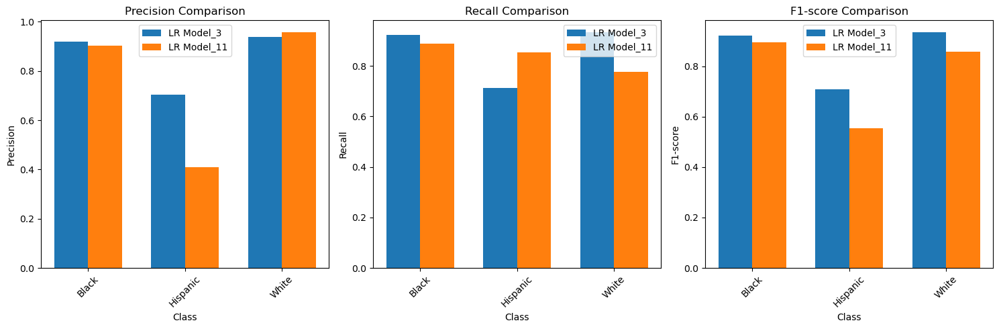

In [150]:
# Classification report for LR Model_3
report1 = classification_report(y_test, y_pred_custom, output_dict=True)

# Classification report for LR Model_11
report2 = classification_report(y_test_encoded, y_pred, output_dict=True, target_names=le.classes_)

# Extract the metrics for each class from the classification reports
classes = list(report1.keys())[:-3]  # Exclude the last three entries (micro avg, macro avg, weighted avg)

metrics = ['precision', 'recall', 'f1-score']

# Create subplots for each metric
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Iterate over metrics and create bar graphs
for i, metric in enumerate(metrics):
    ax = axes[i]
    
    # Extract the metric values for each class from both reports
    values1 = [report1[c][metric] for c in classes]
    values2 = [report2[c][metric] for c in classes]
    
    # Set the positions of the bars on the x-axis
    x = range(len(classes))
    
    # Plot the bars for each model
    width = 0.35
    ax.bar([x - width/2 for x in x], values1, width, label='LR Model_3')
    ax.bar([x + width/2 for x in x], values2, width, label='LR Model_11')
    
    # Set the labels and title
    ax.set_xlabel('Class')
    ax.set_ylabel(metric.capitalize())
    ax.set_title(f'{metric.capitalize()} Comparison')
    ax.set_xticks(x)
    ax.set_xticklabels(classes, rotation=45)
    ax.legend()

# Adjust the spacing between subplots
plt.tight_layout()

# Display the plot
plt.show()

# Model Selection: Logistic Regression Model_3 (LR Model_3)

After comparing the performance of LR Model_3 and LR Model_11 using precision, recall, and F1-score metrics, it is evident that both models exhibit similar results across all three classes (Black, Hispanic, and White).

Given the comparable performance, I have chosen to proceed with **LR Model_3** for the following reasons:

1. **Simplicity**: LR Model_3 has a simpler architecture and does not involve complex techniques like Bayesian optimization. This makes it easier to understand, interpret, and explain the model's behavior.

2. **Lower Computational Requirements**: Due to its simpler structure, LR Model_3 potentially requires fewer computational resources and training time compared to LR Model_11, which involves Bayesian optimization. This can be advantageous when working with limited resources or tight deadlines.

While both models demonstrate similar performance metrics, the simplicity and potentially lower computational requirements of LR Model_3 make it a preferable choice for this project. However, it's important to note that if interpretability is not a major concern and sufficient resources are available, LR Model_11 could also be a viable option.

Moving forward, LR Model_3 will be utilized for further development and deployment. The model's performance will be closely monitored, and if necessary, adjustments or refinements can be made to optimize its performance.

# Before the Deployment 
- Choose the model that works best based on your chosen metric
- For final step, fit the best model with whole dataset to get better performance.
- And your model ready to deploy, dump your model and scaler.

In [172]:
# Prepare the data
X = df.drop(columns=["DODRace"])
y = df.DODRace

# Identify categorical columns
cat = X.select_dtypes("object").columns

# Create the column transformer
column_trans = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    remainder=MinMaxScaler()
)

# Define class weights
class_weights = {
    'Black': 1.5,
    'Hispanic': 2.2,
    'White': 1
}

# Define the pipeline operations
operations = [
    ("OneHotEncoder", column_trans),
    ("log", LogisticRegression(class_weight=class_weights, max_iter=10000, random_state=42))
]

# Create the pipeline
pipe_log_model = Pipeline(steps=operations)

# Fit the model with the entire dataset
pipe_log_model.fit(X, y)

# Define the custom threshold prediction function
def predict_with_threshold(model, X, threshold=0.5):
    proba = model.predict_proba(X)
    return np.where(proba[:, model.named_steps['log'].classes_.tolist().index('Hispanic')] > threshold, 'Hispanic', model.predict(X))

# Evaluate the model performance on the entire dataset
y_pred_custom = predict_with_threshold(pipe_log_model, X)


print("Model Performance on Entire Dataset:")
print("\nWith Custom Threshold:")
print(confusion_matrix(y, y_pred_custom))
print(classification_report(y, y_pred_custom))

# Save the model and the custom prediction function
joblib.dump(pipe_log_model, 'final_model.joblib')
joblib.dump(predict_with_threshold, 'custom_predict_function.joblib')

print("\nModel and custom prediction function have been saved.")

# Example of how to load and use the model
loaded_model = joblib.load('final_model.joblib')
loaded_predict_function = joblib.load('custom_predict_function.joblib')

# Make predictions (you would replace this with your actual new data)
new_data = X.head(10)  # Just an example, replace with your new data
predictions = loaded_predict_function(loaded_model, new_data)

print("\nExample predictions:", predictions)

Model Performance on Entire Dataset:

With Custom Threshold:
[[1205   27   66]
 [  25  494  160]
 [  45  174 3573]]
              precision    recall  f1-score   support

       Black       0.95      0.93      0.94      1298
    Hispanic       0.71      0.73      0.72       679
       White       0.94      0.94      0.94      3792

    accuracy                           0.91      5769
   macro avg       0.87      0.87      0.87      5769
weighted avg       0.91      0.91      0.91      5769


Model and custom prediction function have been saved.

Example predictions: ['White' 'White' 'Black' 'White' 'Black' 'White' 'Black' 'White' 'White'
 'White']


# SMOTE
https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/

**SMOTE (Synthetic Minority Over-sampling Technique)**

**Purpose of Use:**

SMOTE is a sampling technique used to balance imbalanced data sets. Imbalanced data sets refer to situations where one class has many more examples than the other classes. In such data sets, the minority class (the class with fewer examples) is usually ignored and the model is more successful in predicting the majority class. SMOTE tries to correct this imbalance by generating new "synthetic" examples from the minority class.

**Usage Areas:**

- **Credit Risk Assessment**: Fraud cases are usually imbalanced; that is, most transactions are legitimate, but only a few are fraudulent.

- **Medical Diagnosis**: For example, if a disease is rare, there will be an imbalance between healthy and sick samples.
- **Customer Dropout Analysis**: Most customers continue to use the service, while only a few leave the service.
- **Anomaly Detection**: Normal cases are usually more common, while anomalies (e.g. security breaches) are rare.

**Importance for Unbalanced Data:**

Imbalanced datasets can negatively impact the performance of classification models. The model may be good at predicting the majority class, but will often ignore the minority class. This can be a problem, especially if the minority class is more important (e.g. fraud detection, rare disease diagnosis). SMOTE is used to mitigate such problems.

**How ​​Does It Work?**

1. A random sample is selected from the minority class.

2. The k nearest neighbors of this sample are calculated.

3. One of the k nearest neighbors is selected randomly.

4. A random interpolation factor* is generated.

5. A new "synthetic" sample is created using this factor.

**Usage:**

In Python, SMOTE is usually used with the imbalanced-learn library.

*The interpolation factor is a weighting factor used in the SMOTE algorithm when creating new "synthetic" samples. The basic idea is to create a new sample between a sample selected from the minority class and its k nearest neighbors. The interpolation factor determines how "close" these two samples will be. It increases the flexibility of the SMOTE algorithm and helps improve the generalization ability of the model by spreading the samples of the minority class over a larger area.

<div style="
  background: linear-gradient(135deg, #f5f7fa 0%, #e5e9f2 100%);
  border: 1px solid #d1d9e6;
  border-radius: 8px;
  box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1);
  padding: 25px;
  max-width: 600px;
  margin: 20px auto;
  font-family: Arial, sans-serif;
">
  <h2 style="
    color: #2c3e50;
    text-align: center;
    margin-bottom: 20px;
    font-size: 24px;
    text-shadow: 1px 1px 2px rgba(0,0,0,0.1);
  ">📊 Approach Suggestions for Imbalanced Data 📊</h2>
  
  <div style="
    background: linear-gradient(to right, #ffffff, #f8f9fa);
    border: 1px solid #e9ecef;
    border-radius: 6px;
    padding: 20px;
    margin-bottom: 20px;
  ">
    <h3 style="
      color: #34495e;
      margin-top: 0;
      font-size: 18px;
      border-bottom: 2px solid #3498db;
      padding-bottom: 8px;
    ">Key Models for SMOTE Approach:</h3>
    <ul style="list-style-type: none; padding-left: 0;">
      <li style="margin-bottom: 12px;">
        <span style="color: #3498db; margin-right: 8px;">▶</span>
        <a href="#4.1.2.-logistic-regression-(enchanced-smote,-no-hyperparameters,-labelencoder)-model_2" style="
          color: #2980b9;
          text-decoration: none;
          font-weight: bold;
          transition: color 0.3s ease;
        " onmouseover="this.style.color='#3498db'" onmouseout="this.style.color='#2980b9'">
          Logistic Regression model_2
        </a>
      </li>
      <li style="margin-bottom: 12px;">
        <span style="color: #3498db; margin-right: 8px;">▶</span>
        <a href="#4.1.5.-logistic-regression-(sublinear-and-enchanced-smote)---model_5" style="
          color: #2980b9;
          text-decoration: none;
          font-weight: bold;
          transition: color 0.3s ease;
        " onmouseover="this.style.color='#3498db'" onmouseout="this.style.color='#2980b9'">
          Logistic Regression model_Model_5
        </a>
      </li>
    </ul>
  </div>
  
  <div style="
    background: linear-gradient(to right, #e8f8f5, #d1f2eb);
    border: 1px solid #a3e4d7;
    border-radius: 6px;
    padding: 15px;
  ">
    <p style="
      color: #16a085;
      font-weight: bold;
      margin: 0;
      font-size: 16px;
    ">Note: Both models implement SMOTE for algorithm enhancement</p>
  </div>
  
  <p style="
    text-align: center;
    margin-top: 20px;
    font-style: italic;
    color: #7f8c8d;
    font-size: 14px;
  "> Thank you for your attention </p>
</div>

#  SHAP

**SHAP (SHapley Additive exPlanations)**

**What is it?**

SHAP is a tool used to explain the predictions of machine learning models. SHAP values ​​measure the impact of each feature of a model on a prediction. These values ​​are based on Shapley values, a mathematical theory known as cooperative game theory.

**What is it used for?**
- **Model Interpretability**: Understanding which features of the model affect the predictions the most.
- **Feature Selection**: Reducing the complexity of the model by identifying the most important features.
- **Audit and Compliance**: Explaining the model's decisions and meeting legal requirements.
- **Model Development**: Understanding in which areas the model performs well or poorly.

**Where is it used?**
- **Credit Scoring**: Understanding which factors affect a person's credit score.
- **Health**: Determining which medical features are important in predicting a disease.
- **Marketing**: Understanding the factors that influence customer behavior.

- **Natural Language Processing**: Understanding which words or features the model finds important in NLP tasks like text classification or sentiment analysis.

**Importance in Unbalanced Datasets
In unbalanced datasets, the model can often be biased towards the majority class. SHAP is also useful for such cases because it can explain why the model misclassified the minority class. This is very useful for understanding which features need to be taken into account more to improve the model’s performance.

**SHAP is a powerful and flexible tool for model interpretability and can be used with many different types of machine learning models.**

For information: https://towardsdatascience.com/shap-explain-any-machine-learning-model-in-python-24207127cad7

- Shap; shows how much each feature contributes when making a prediction, either on an observation basis or when estimating classes in the entire data.

- For example, if we select the features of the Hispanic class in this data and make a feature selection only on them, our scores can be better with fewer observations.

- A different process than the feature importance process we did before.

In [292]:
# Preparation of Dataframe 
X = df.drop('DODRace', axis=1)
y = df['DODRace']

# Identify categorical columns
categorical_columns = X.select_dtypes(include=['object', 'category']).columns

# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', X.select_dtypes(include=['int64', 'float64']).columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Define evaluation function
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)
    
    print("Test Set")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print()
    print("Train Set")
    print(confusion_matrix(y_train, y_train_pred))
    print(classification_report(y_train, y_train_pred))

# Create a pipeline with preprocessing, SMOTE and RandomForestClassifier
smote = SMOTE(sampling_strategy={
    'White': 3792,
    'Black': 3792,
    'Hispanic': 3000  # Increase Hispanic samples, but not to the full majority class level
}, random_state=42)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', smote),
    ('classifier', RandomForestClassifier(random_state=101))
])

# Define the parameter grid
param_grid = {
    'classifier__n_estimators': [32],
    'classifier__max_depth': [12],
    'classifier__min_samples_split': [18],
    'classifier__class_weight': ['balanced', {
        'White': 1,
        'Black': 1.5,
        'Hispanic': 2.2
    }]
}

# Instantiate the grid search model
grid_search = GridSearchCV(
    estimator=pipeline, 
    param_grid=param_grid, 
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1, 
    verbose=2, 
    scoring='recall_macro',
    return_train_score=True
)

# Fit the grid search to the data
grid_search.fit(X_train, y_train)

# Get the best parameters and model
print("Best parameters found: ", grid_search.best_params_)
best_model = grid_search.best_estimator_

# Evaluate the best model
print("Evaluation of the best model:")
eval_metric(best_model, X_train, y_train, X_test, y_test)

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best parameters found:  {'classifier__class_weight': {'White': 1, 'Black': 1.5, 'Hispanic': 2.2}, 'classifier__max_depth': 12, 'classifier__min_samples_split': 18, 'classifier__n_estimators': 32}
Evaluation of the best model:
Test Set
[[214  21  25]
 [ 14  82  40]
 [ 42 135 581]]
              precision    recall  f1-score   support

       Black       0.79      0.82      0.81       260
    Hispanic       0.34      0.60      0.44       136
       White       0.90      0.77      0.83       758

    accuracy                           0.76      1154
   macro avg       0.68      0.73      0.69      1154
weighted avg       0.81      0.76      0.78      1154


Train Set
[[1018   11    9]
 [   2  536    5]
 [  42  234 2758]]
              precision    recall  f1-score   support

       Black       0.96      0.98      0.97      1038
    Hispanic       0.69      0.99      0.81       543
       White       0.99      0.91      0.95      

In [348]:
column_trans_shap = make_column_transformer((OneHotEncoder(handle_unknown="ignore",
                                                           sparse_output=False), cat), 
                                             remainder=MinMaxScaler(),
                                             verbose_feature_names_out=False)

X_train_trans = column_trans_shap.fit_transform(X_train)
X_test_trans = column_trans_shap.transform(X_test)

model_shap = LogisticRegression(C=0.4,
                                class_weight='balanced',
                                random_state=101,
                                penalty="l1",
                                solver='saga')

model_shap.fit(X_train_trans, y_train)


eval_metric(model_shap, X_train_trans, y_train, X_test_trans, y_test)



operations = [("OneHotEncoder", column_trans_shap),
              ("log", LogisticRegression(C=0.4,
                                         class_weight='balanced',
                                         random_state=101,
                                         penalty="l1",
                                         solver='saga'))]

model = Pipeline(steps=operations)

scores = cross_validate(model,
                        X_train,
                        y_train, 
                        cv=10,
                        return_train_score=True)
df_scores = pd.DataFrame(scores, index = range(1, 11))
df_scores.mean()[2:]




features = column_trans_shap.get_feature_names_out()
features


Test Set
[[238  16   6]
 [  6 107  23]
 [ 14  97 647]]
              precision    recall  f1-score   support

       Black       0.92      0.92      0.92       260
    Hispanic       0.49      0.79      0.60       136
       White       0.96      0.85      0.90       758

    accuracy                           0.86      1154
   macro avg       0.79      0.85      0.81      1154
weighted avg       0.89      0.86      0.87      1154


Train Set
[[ 962   41   35]
 [  25  442   76]
 [  75  375 2584]]
              precision    recall  f1-score   support

       Black       0.91      0.93      0.92      1038
    Hispanic       0.52      0.81      0.63       543
       White       0.96      0.85      0.90      3034

    accuracy                           0.86      4615
   macro avg       0.79      0.86      0.82      4615
weighted avg       0.89      0.86      0.87      4615



array(['Gender_Female', 'Gender_Male', 'Component_Army National Guard',
       'Component_Army Reserve', 'Component_Regular Army',
       'SubjectsBirthLocation_Alabama', 'SubjectsBirthLocation_Alaska',
       'SubjectsBirthLocation_Antigua and Barbuda',
       'SubjectsBirthLocation_Argentina', 'SubjectsBirthLocation_Arizona',
       'SubjectsBirthLocation_Arkansas', 'SubjectsBirthLocation_Bahamas',
       'SubjectsBirthLocation_Barbados', 'SubjectsBirthLocation_Belarus',
       'SubjectsBirthLocation_Belgium', 'SubjectsBirthLocation_Belize',
       'SubjectsBirthLocation_Bermuda', 'SubjectsBirthLocation_Bolivia',
       'SubjectsBirthLocation_Bosnia and Herzegovina',
       'SubjectsBirthLocation_British Virgin Islands',
       'SubjectsBirthLocation_Bulgaria',
       'SubjectsBirthLocation_California',
       'SubjectsBirthLocation_Cameroon', 'SubjectsBirthLocation_Canada',
       'SubjectsBirthLocation_Cape Verde',
       'SubjectsBirthLocation_Colombia', 'SubjectsBirthLocation_Col

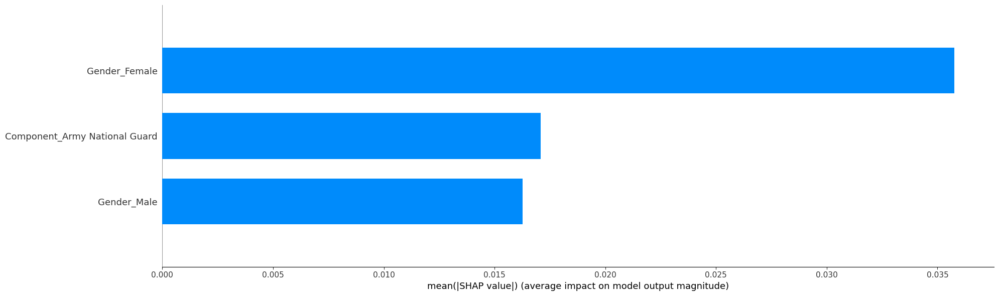

In [350]:
shap.summary_plot(shap_values[1], 
                  max_display=300, 
                  feature_names = features, 
                  plot_size=(20,6), 
                  plot_type="bar") 

In [365]:
np.random.seed(101)
shap.initjs()

In [369]:
# Create SHAP explainer
# We use model_shap instead of model['classifier'] because the pipeline doesn't have a 'classifier' step
explainer = shap.Explainer(model_shap, X_train_trans, feature_names=features)
shap_values = explainer(X_test_trans)

In [375]:
# Initialize SHAP JavaScript visualization
shap.initjs()

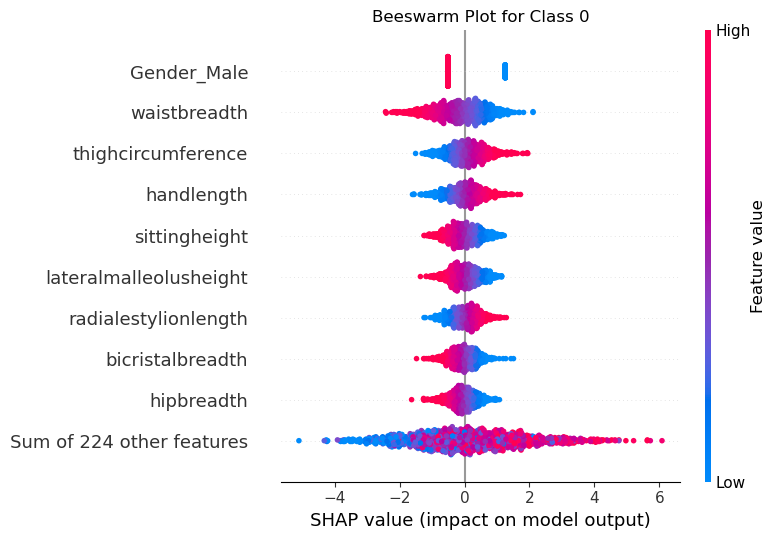

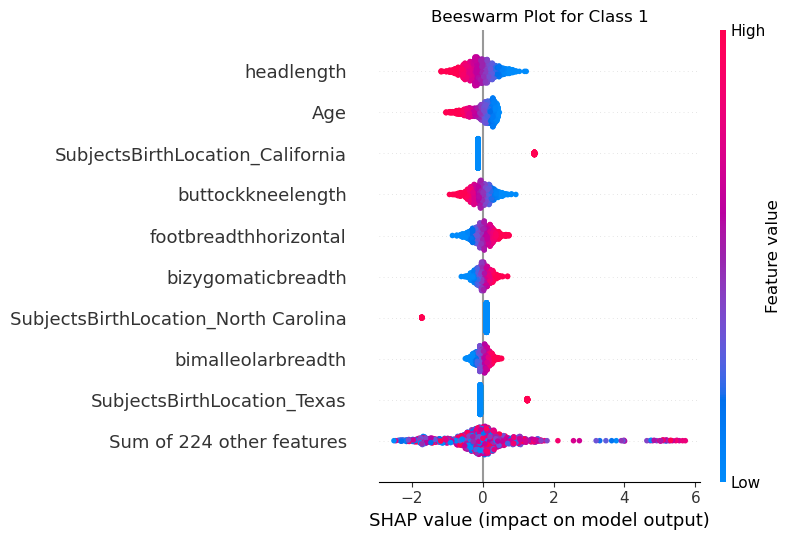

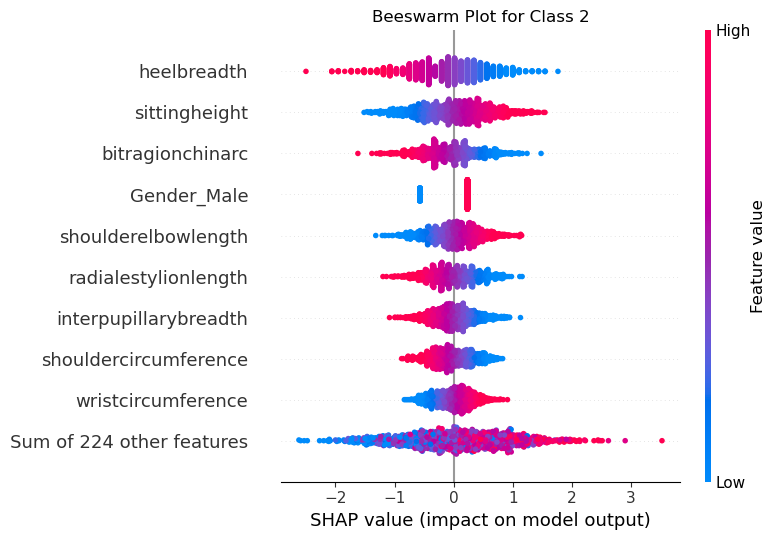

In [385]:
# 1. Beeswarm Plot (for each class)
for class_idx in range(shap_values.shape[2]):  # Iterate over classes
    plt.figure(figsize=(10, 6))
    shap.plots.beeswarm(shap_values[:, :, class_idx], show=False)
    plt.title(f"Beeswarm Plot for Class {class_idx}")
    plt.tight_layout()
    plt.show()



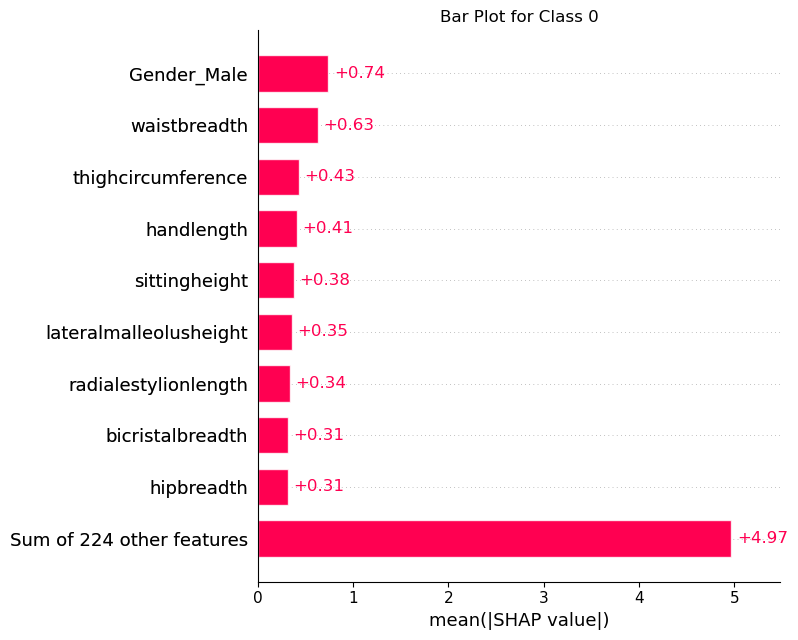

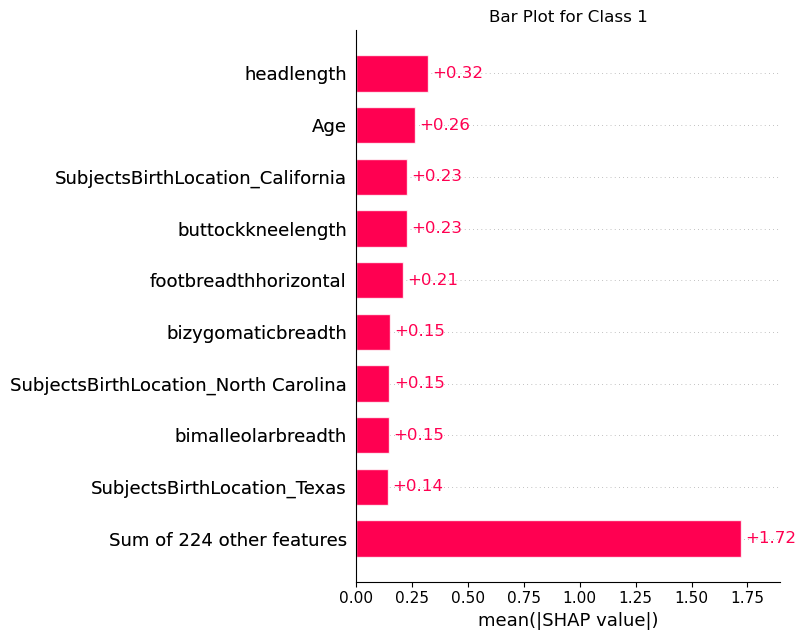

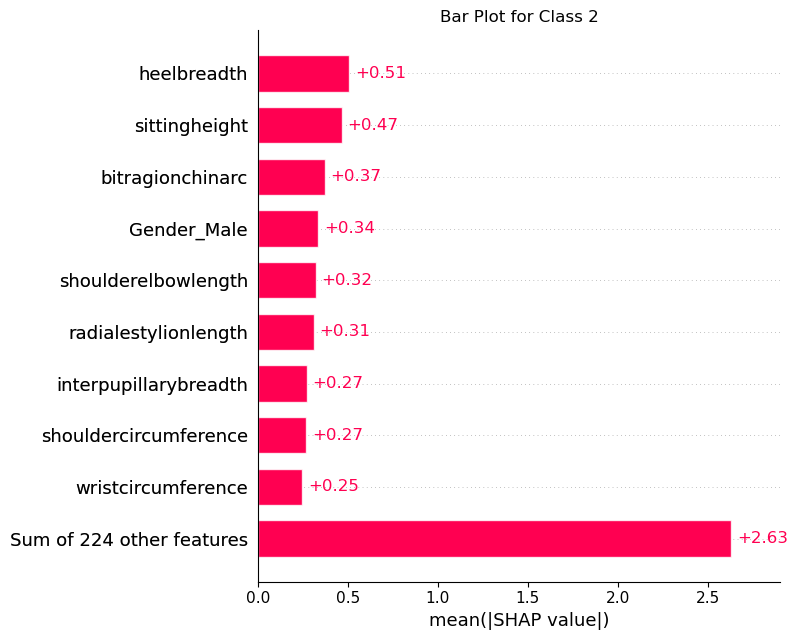

In [387]:
# 2. Bar Plot (for each class)
for class_idx in range(shap_values.shape[2]):
    plt.figure(figsize=(10, 6))
    shap.plots.bar(shap_values[:, :, class_idx], show=False)
    plt.title(f"Bar Plot for Class {class_idx}")
    plt.tight_layout()
    plt.show()

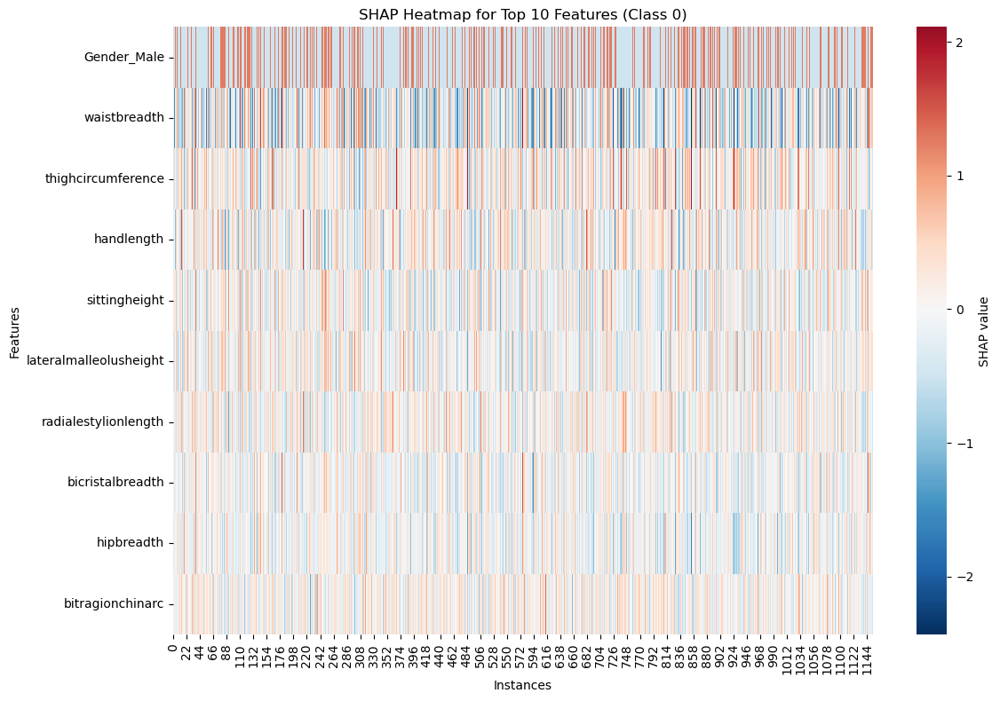


Top 10 features for Class 0 by mean |SHAP value|:
1. Gender_Male: 0.7382
2. waistbreadth: 0.6285
3. thighcircumference: 0.4299
4. handlength: 0.4088
5. sittingheight: 0.3775
6. lateralmalleolusheight: 0.3533
7. radialestylionlength: 0.3367
8. bicristalbreadth: 0.3126
9. hipbreadth: 0.3120
10. bitragionchinarc: 0.3117


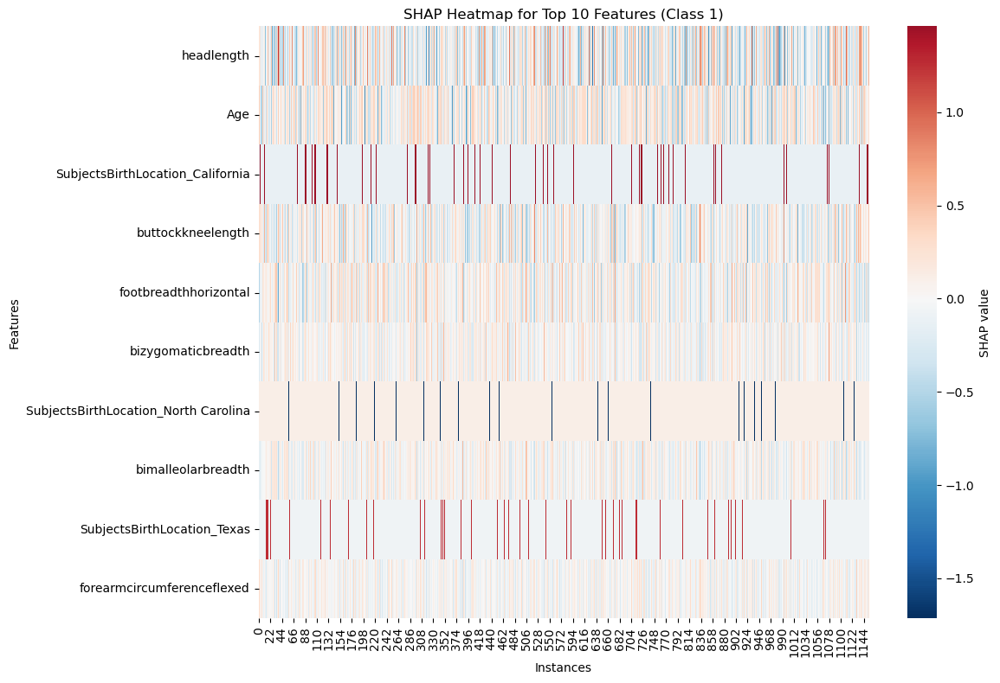


Top 10 features for Class 1 by mean |SHAP value|:
1. headlength: 0.3183
2. Age: 0.2608
3. SubjectsBirthLocation_California: 0.2265
4. buttockkneelength: 0.2255
5. footbreadthhorizontal: 0.2093
6. bizygomaticbreadth: 0.1504
7. SubjectsBirthLocation_North Carolina: 0.1470
8. bimalleolarbreadth: 0.1453
9. SubjectsBirthLocation_Texas: 0.1398
10. forearmcircumferenceflexed: 0.1250


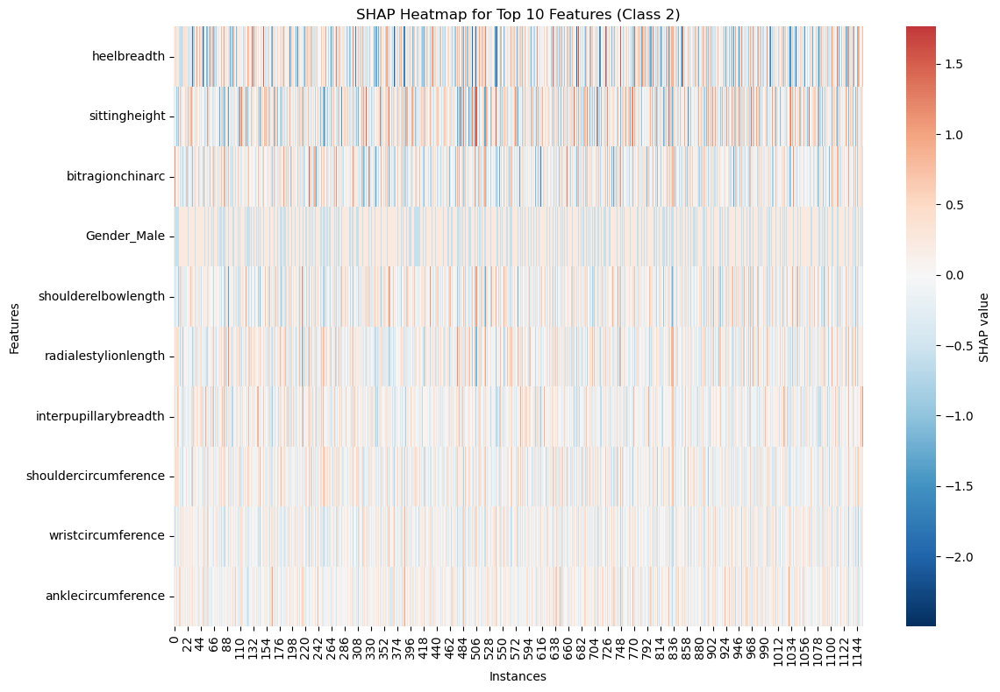


Top 10 features for Class 2 by mean |SHAP value|:
1. heelbreadth: 0.5079
2. sittingheight: 0.4668
3. bitragionchinarc: 0.3702
4. Gender_Male: 0.3353
5. shoulderelbowlength: 0.3217
6. radialestylionlength: 0.3127
7. interpupillarybreadth: 0.2703
8. shouldercircumference: 0.2692
9. wristcircumference: 0.2472
10. anklecircumference: 0.2228


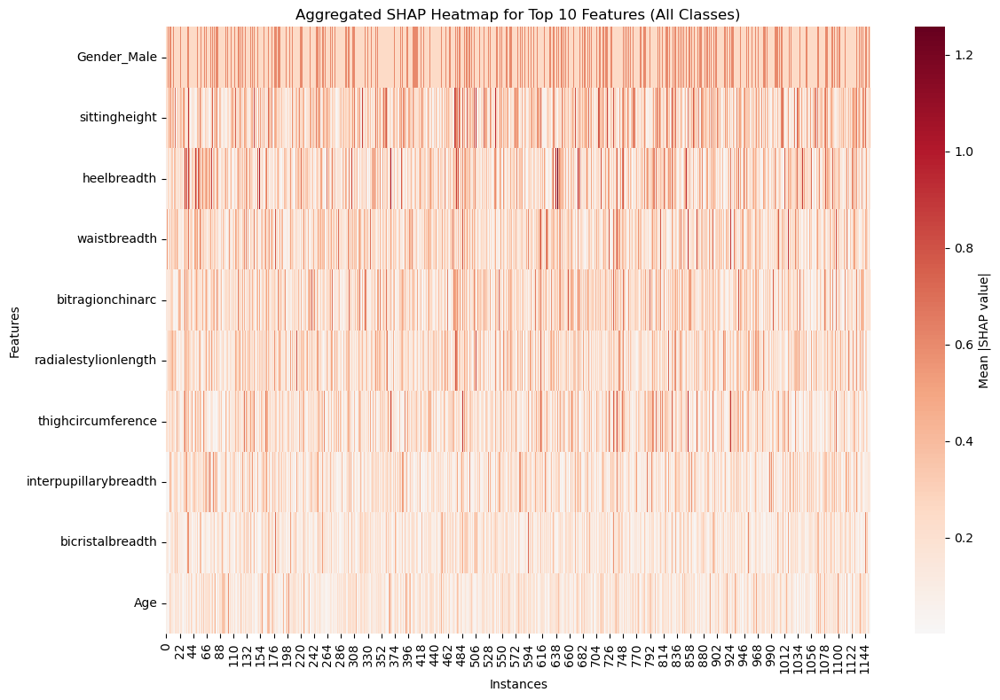


Top 10 features across all classes by mean |SHAP value|:
1. Gender_Male: 0.3578
2. sittingheight: 0.2814
3. heelbreadth: 0.2557
4. waistbreadth: 0.2297
5. bitragionchinarc: 0.2273
6. radialestylionlength: 0.2165
7. thighcircumference: 0.1987
8. interpupillarybreadth: 0.1730
9. bicristalbreadth: 0.1505
10. Age: 0.1467


In [446]:
# 3. Heatmap (for each class)
# shap_values is our SHAP Explanation object
num_classes = shap_values.shape[2]

for class_idx in range(num_classes):
    # Extract SHAP values for the current class
    class_shap_values = shap_values[:, :, class_idx].values

    # Calculate the mean absolute SHAP value for each feature
    mean_shap = np.abs(class_shap_values).mean(axis=0)

    # Get the top N features (e.g., top 10)
    top_n = 10
    top_features_idx = mean_shap.argsort()[-top_n:][::-1]
    top_features = [features[i] for i in top_features_idx]

    # Create a heatmap using seaborn
    plt.figure(figsize=(12, 8))
    sns.heatmap(class_shap_values[:, top_features_idx].T, 
                cmap='RdBu_r', 
                center=0, 
                yticklabels=top_features,
                cbar_kws={'label': 'SHAP value'})
    
    plt.title(f'SHAP Heatmap for Top {top_n} Features (Class {class_idx})')
    plt.xlabel('Instances')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

    # Optional: Print feature importance
    print(f"\nTop {top_n} features for Class {class_idx} by mean |SHAP value|:")
    for i, feature in enumerate(top_features):
        print(f"{i+1}. {feature}: {mean_shap[top_features_idx[i]]:.4f}")

# Aggregate view across all classes
aggregated_shap_values = np.abs(shap_values.values).mean(axis=2)
mean_shap_aggregated = aggregated_shap_values.mean(axis=0)
top_features_idx_aggregated = mean_shap_aggregated.argsort()[-top_n:][::-1]
top_features_aggregated = [features[i] for i in top_features_idx_aggregated]

plt.figure(figsize=(12, 8))
sns.heatmap(aggregated_shap_values[:, top_features_idx_aggregated].T, 
            cmap='RdBu_r', 
            center=0, 
            yticklabels=top_features_aggregated,
            cbar_kws={'label': 'Mean |SHAP value|'})

plt.title(f'Aggregated SHAP Heatmap for Top {top_n} Features (All Classes)')
plt.xlabel('Instances')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} features across all classes by mean |SHAP value|:")
for i, feature in enumerate(top_features_aggregated):
    print(f"{i+1}. {feature}: {mean_shap_aggregated[top_features_idx_aggregated[i]]:.4f}")

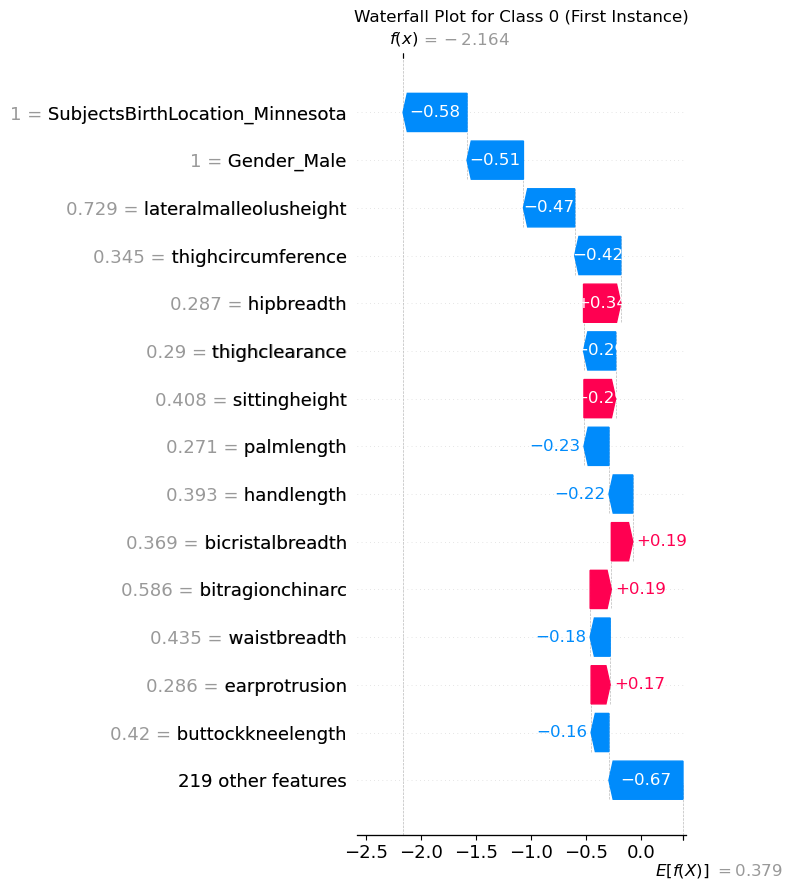

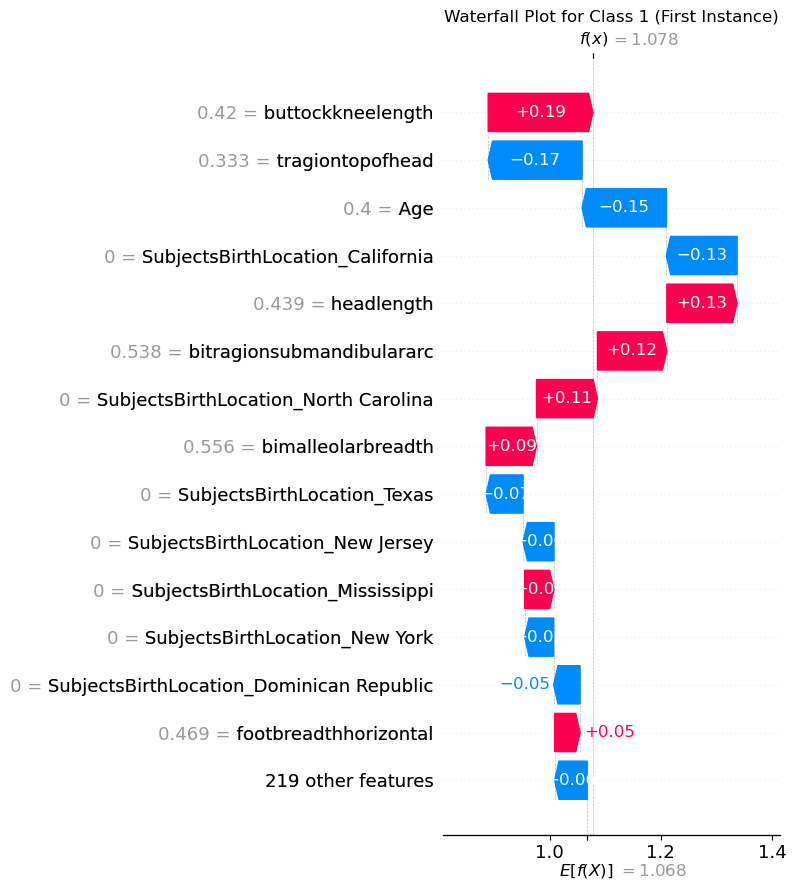

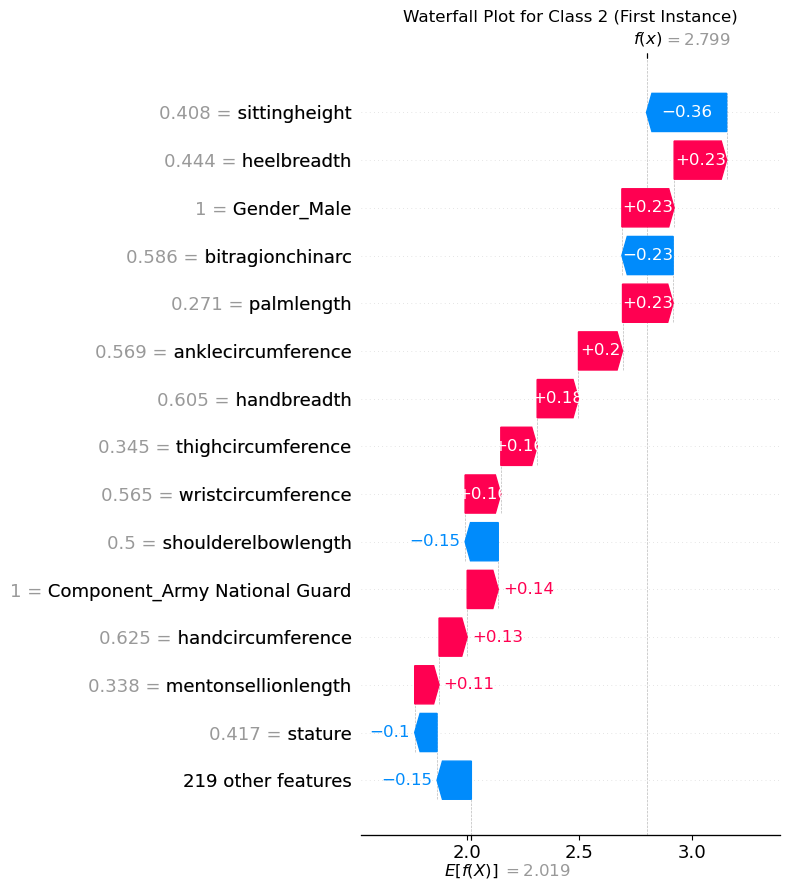

In [448]:
# 4. Waterfall Plot (for the first instance of each class)
num_classes = shap_values.shape[2]
for class_idx in range(num_classes):
    plt.figure(figsize=(10, 8))  # Increased figure size for better visibility
    shap.plots.waterfall(shap_values[0, :, class_idx], 
                         max_display=15,  # Limit to top 15 features for clarity
                         show=False)
    plt.title(f"Waterfall Plot for Class {class_idx} (First Instance)")
    plt.tight_layout()
    plt.show()


<Figure size 2000x500 with 0 Axes>

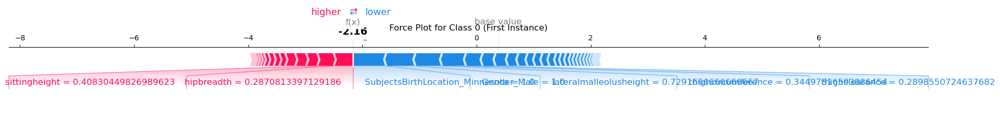

<Figure size 2000x500 with 0 Axes>

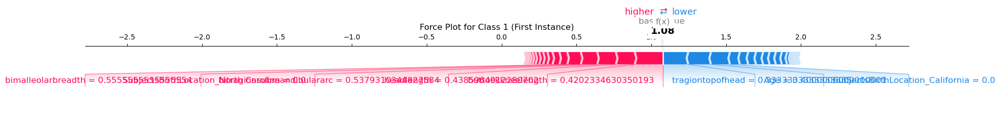

<Figure size 2000x500 with 0 Axes>

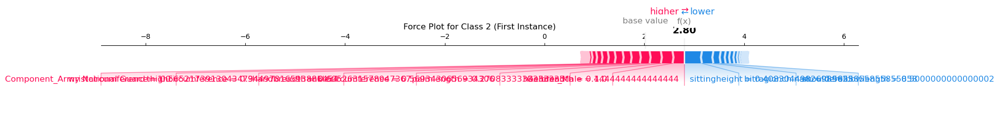

In [413]:
# 5. Force Plot (for the first instance of each class)
num_classes = shap_values.shape[2]
for class_idx in range(num_classes):
    plt.figure(figsize=(20, 5))  # Increased height for better visibility
    shap.plots.force(shap_values[0, :, class_idx], 
                     features=X_test_trans[0],  # Add feature values
                     feature_names=features,    # Ensure feature names are provided
                     matplotlib=True,
                     show=False)
    plt.title(f"Force Plot for Class {class_idx} (First Instance)")
    plt.tight_layout()
    plt.show()

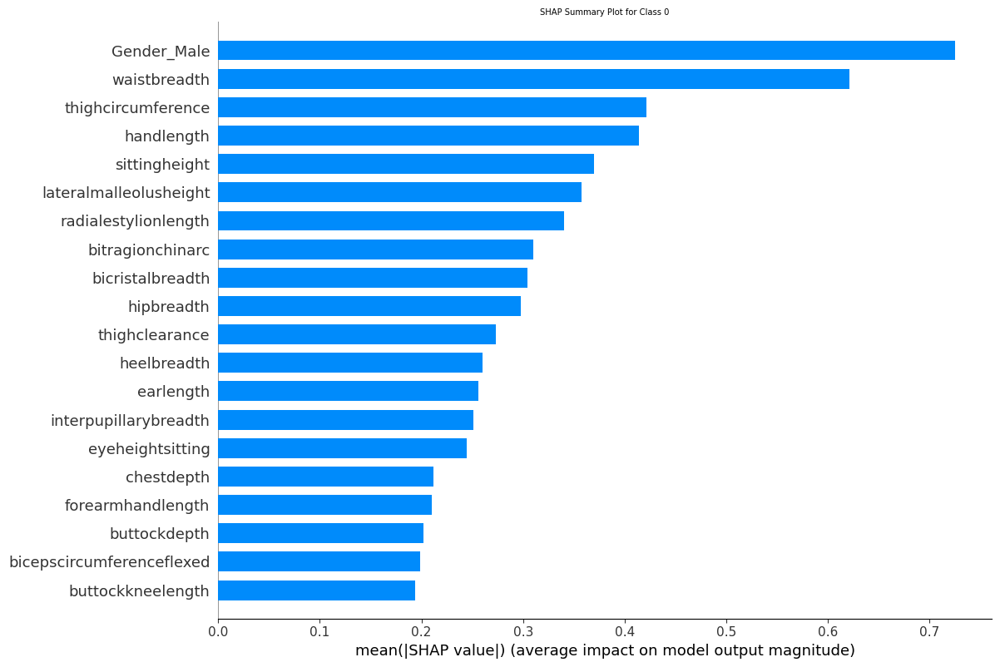

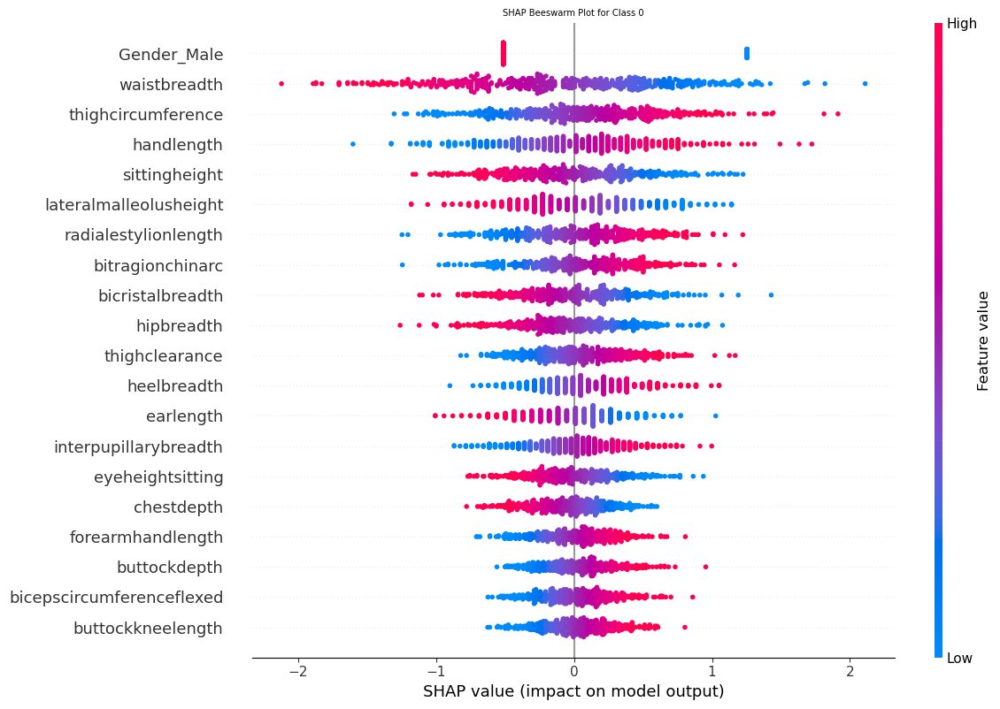

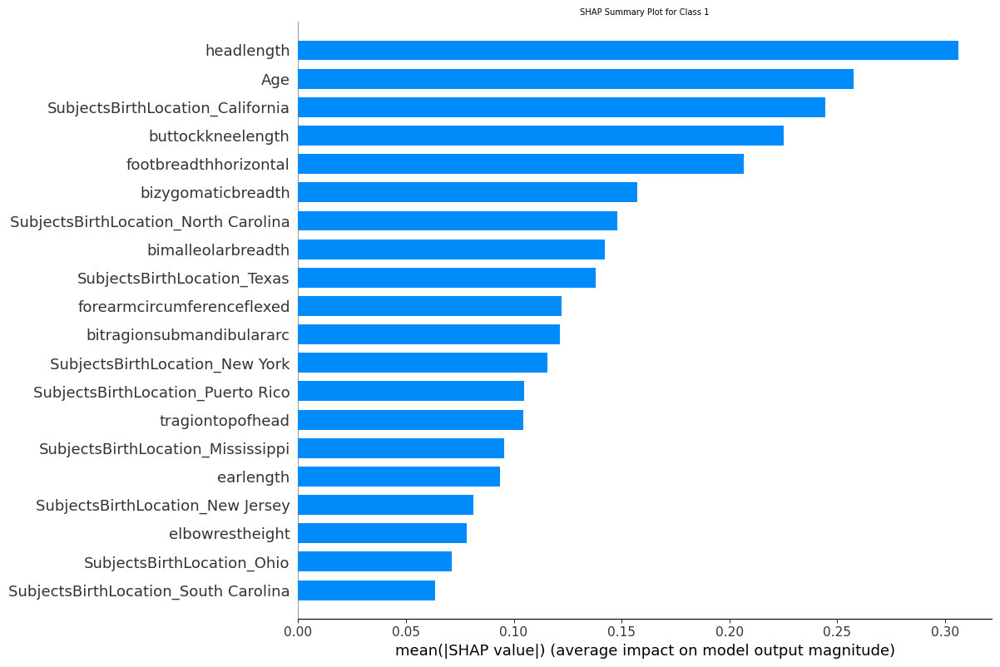

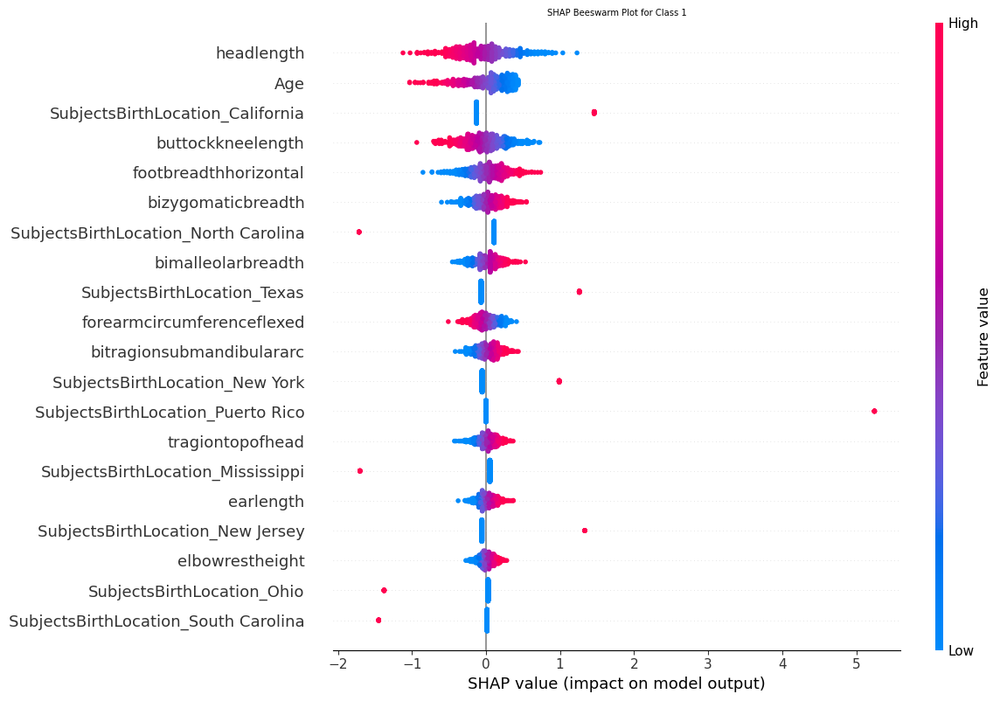

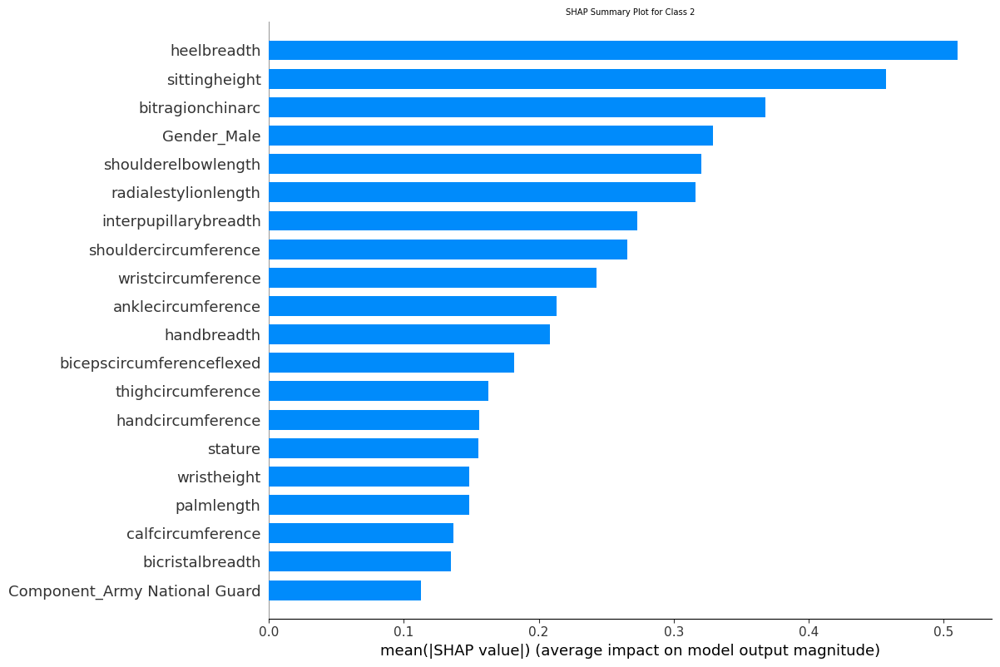

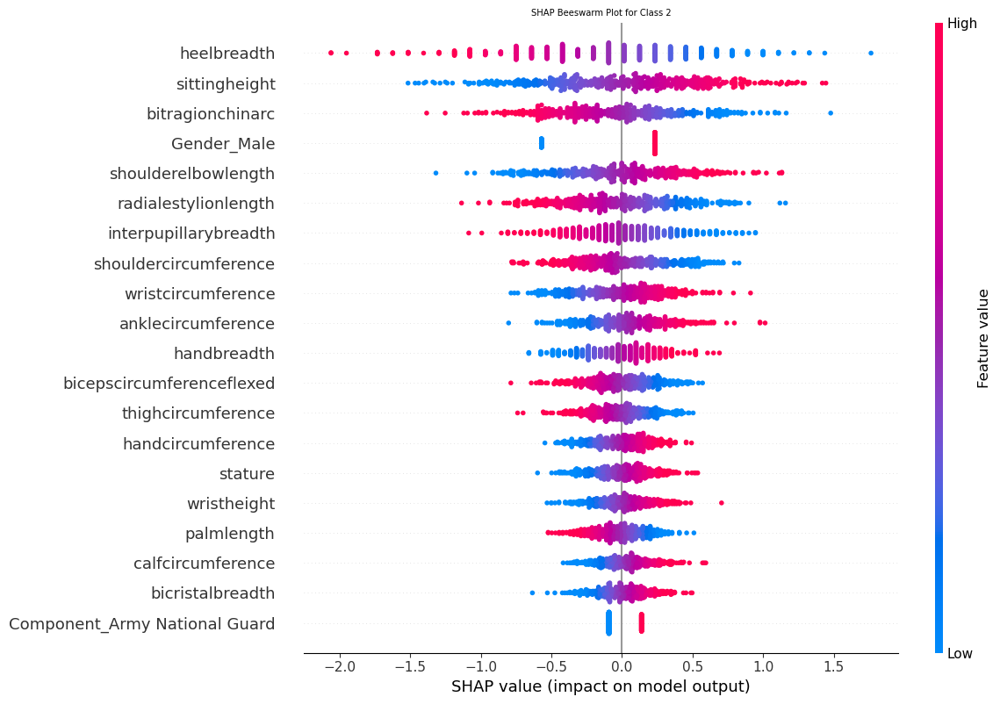

Summary plots for each class have been generated.


<Figure size 1600x3200 with 0 Axes>

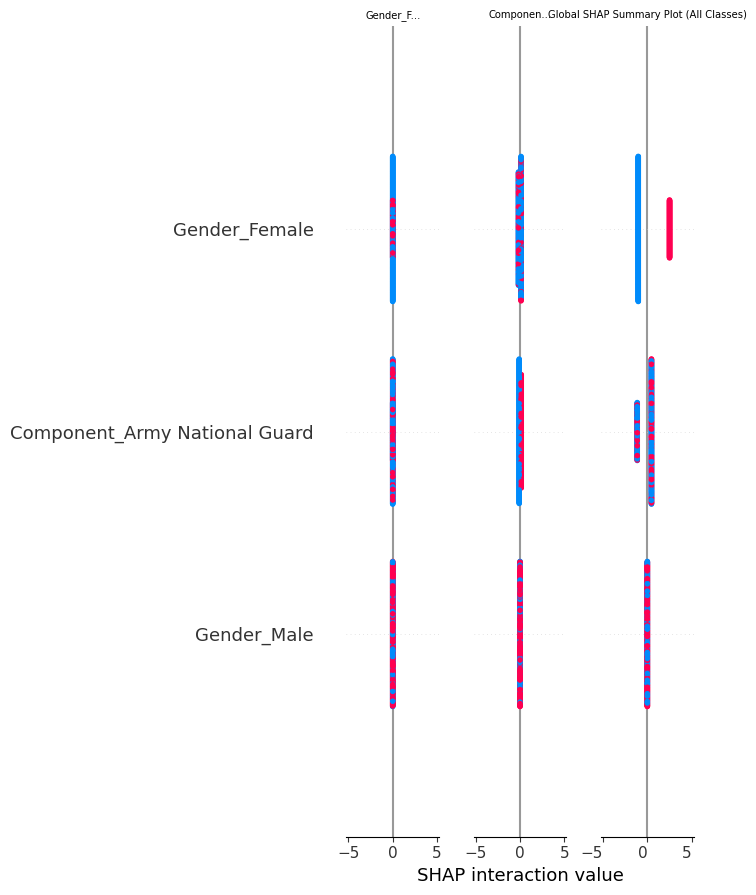

In [486]:
# 6. Summary Plot (for the entire dataset)
# For multi-class, we'll create a summary plot for each class
num_classes = shap_values.shape[2]
num_samples = min(500, shap_values.shape[0])  # Limit to 500 samples for better performance

for class_idx in range(num_classes):
    plt.figure(figsize=(12, 8))
    shap.summary_plot(
        shap_values[:num_samples, :, class_idx],
        X_test_trans[:num_samples],
        plot_type="bar",
        feature_names=features,
        plot_size=(12, 8),
        show=False
    )
    plt.title(f"SHAP Summary Plot for Class {class_idx}")
    plt.tight_layout()
    plt.show()

    # Alternative: Beeswarm plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(
        shap_values[:num_samples, :, class_idx],
        X_test_trans[:num_samples],
        plot_type="dot",
        feature_names=features,
        plot_size=(12, 8),
        show=False
    )
    plt.title(f"SHAP Beeswarm Plot for Class {class_idx}")
    plt.tight_layout()
    plt.show()

print("Summary plots for each class have been generated.")

# Optional: Global summary plot across all classes
plt.figure(figsize=(16, 32))
plt.rcParams.update({'font.size': 6})
shap.summary_plot(
    shap_values[:num_samples],
    X_test_trans[:num_samples],
    plot_type="bar",
    feature_names=features,
    plot_size=(10, 20),
    max_display=10,  # Adjust this to show more or fewer features
    show=False
)
plt.title("Global SHAP Summary Plot (All Classes)")
plt.xticks(rotation=0, ha='right')
plt.tight_layout(pad=1.5)
plt.show()

In [488]:
import os
import matplotlib.pyplot as plt
import shap
import seaborn as sns
import numpy as np

def save_plot(plt, plot_type, class_idx=None, additional_info=None):
    # Create a directory to store the images if it doesn't exist
    output_dir = "shap_plots"
    os.makedirs(output_dir, exist_ok=True)
    
    # Construct the filename
    filename = f"{plot_type}"
    if class_idx is not None:
        filename += f"_class_{class_idx}"
    if additional_info:
        filename += f"_{additional_info}"
    filename += ".png"
    
    # Save the plot
    plt.savefig(os.path.join(output_dir, filename), dpi=300, bbox_inches='tight')
    plt.close()  # Close the plot to free up memory

# 1. Beeswarm Plot
for class_idx in range(shap_values.shape[2]):
    plt.figure(figsize=(10, 6))
    shap.plots.beeswarm(shap_values[:, :, class_idx], show=False)
    plt.title(f"Beeswarm Plot for Class {class_idx}")
    plt.tight_layout()
    save_plot(plt, "beeswarm", class_idx)

# 2. Bar Plot
for class_idx in range(shap_values.shape[2]):
    plt.figure(figsize=(10, 6))
    shap.plots.bar(shap_values[:, :, class_idx], show=False)
    plt.title(f"Bar Plot for Class {class_idx}")
    plt.tight_layout()
    save_plot(plt, "bar", class_idx)

# 3. Heatmap
num_classes = shap_values.shape[2]
for class_idx in range(num_classes):
    class_shap_values = shap_values[:, :, class_idx].values
    mean_shap = np.abs(class_shap_values).mean(axis=0)
    top_n = 10
    top_features_idx = mean_shap.argsort()[-top_n:][::-1]
    top_features = [features[i] for i in top_features_idx]
    
    plt.figure(figsize=(12, 8))
    sns.heatmap(class_shap_values[:, top_features_idx].T, 
                cmap='RdBu_r', 
                center=0, 
                yticklabels=top_features,
                cbar_kws={'label': 'SHAP value'})
    
    plt.title(f'SHAP Heatmap for Top {top_n} Features (Class {class_idx})')
    plt.xlabel('Instances')
    plt.ylabel('Features')
    plt.tight_layout()
    save_plot(plt, "heatmap", class_idx)

# Aggregated Heatmap
aggregated_shap_values = np.abs(shap_values.values).mean(axis=2)
mean_shap_aggregated = aggregated_shap_values.mean(axis=0)
top_features_idx_aggregated = mean_shap_aggregated.argsort()[-top_n:][::-1]
top_features_aggregated = [features[i] for i in top_features_idx_aggregated]

plt.figure(figsize=(12, 8))
sns.heatmap(aggregated_shap_values[:, top_features_idx_aggregated].T, 
            cmap='RdBu_r', 
            center=0, 
            yticklabels=top_features_aggregated,
            cbar_kws={'label': 'Mean |SHAP value|'})
plt.title(f'Aggregated SHAP Heatmap for Top {top_n} Features (All Classes)')
plt.xlabel('Instances')
plt.ylabel('Features')
plt.tight_layout()
save_plot(plt, "heatmap", additional_info="aggregated")

# 4. Waterfall Plot
for class_idx in range(num_classes):
    plt.figure(figsize=(10, 8))
    shap.plots.waterfall(shap_values[0, :, class_idx], 
                         max_display=15,
                         show=False)
    plt.title(f"Waterfall Plot for Class {class_idx} (First Instance)")
    plt.tight_layout()
    save_plot(plt, "waterfall", class_idx)

# 5. Force Plot
for class_idx in range(num_classes):
    plt.figure(figsize=(20, 5))
    shap.plots.force(shap_values[0, :, class_idx], 
                     features=X_test_trans[0],
                     feature_names=features,
                     matplotlib=True,
                     show=False)
    plt.title(f"Force Plot for Class {class_idx} (First Instance)")
    plt.tight_layout()
    save_plot(plt, "force", class_idx)

# 6. Summary Plot
num_samples = min(500, shap_values.shape[0])
for class_idx in range(num_classes):
    plt.figure(figsize=(12, 8))
    shap.summary_plot(
        shap_values[:num_samples, :, class_idx],
        X_test_trans[:num_samples],
        plot_type="bar",
        feature_names=features,
        plot_size=(12, 8),
        show=False
    )
    plt.title(f"SHAP Summary Plot for Class {class_idx}")
    plt.tight_layout()
    save_plot(plt, "summary_bar", class_idx)
    
    plt.figure(figsize=(12, 8))
    shap.summary_plot(
        shap_values[:num_samples, :, class_idx],
        X_test_trans[:num_samples],
        plot_type="dot",
        feature_names=features,
        plot_size=(12, 8),
        show=False
    )
    plt.title(f"SHAP Beeswarm Plot for Class {class_idx}")
    plt.tight_layout()
    save_plot(plt, "summary_beeswarm", class_idx)

# Global summary plot
plt.figure(figsize=(16, 32))
plt.rcParams.update({'font.size': 6})
shap.summary_plot(
    shap_values[:num_samples],
    X_test_trans[:num_samples],
    plot_type="bar",
    feature_names=features,
    plot_size=(10, 20),
    max_display=10,
    show=False
)
plt.title("Global SHAP Summary Plot (All Classes)")
plt.xticks(rotation=0, ha='right')
plt.tight_layout(pad=1.5)
save_plot(plt, "global_summary")

print("All plots have been saved as image files in the 'shap_plots' directory.")

All plots have been saved as image files in the 'shap_plots' directory.


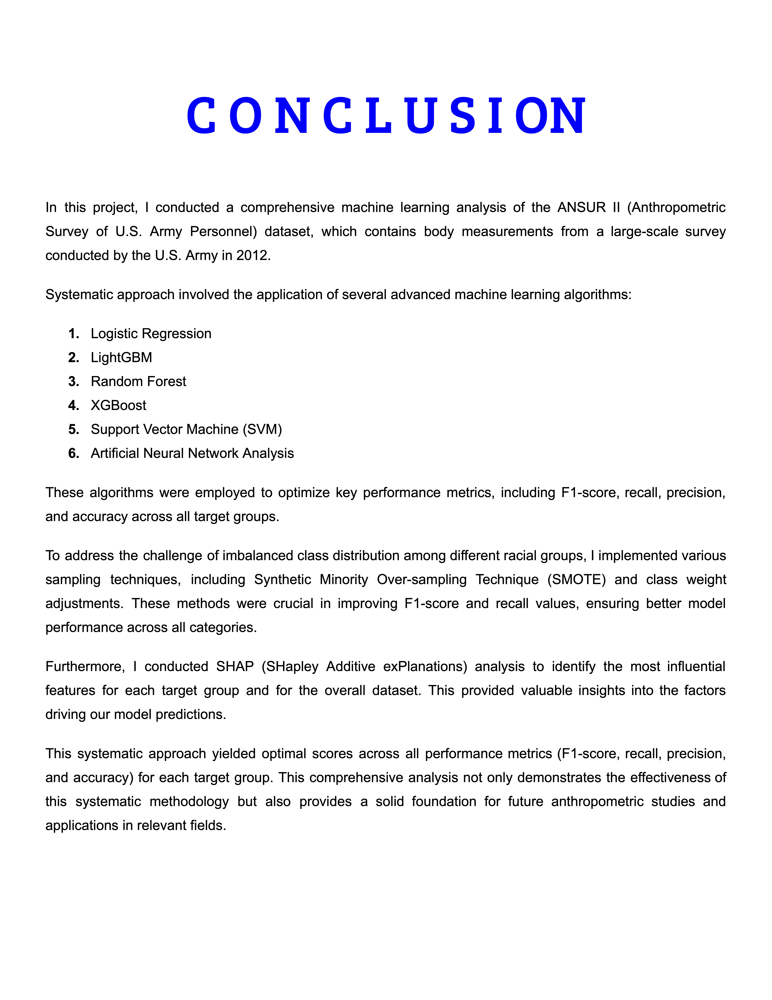